In [1]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [10]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [11]:
# 3. Lectura de la ruta
base_dir = r"C:\Users\Luis Felipe\Desktop\Trabajo IA\Cars_Body_Type\train"

## Fuente del dataset

Para este ejercicio se utiliza el dataset **Cars Body Type Cropped**, publicado en Kaggle por **ademboukhris**.

[Consultar el dataset en Kaggle](https://www.kaggle.com/datasets/ademboukhris/cars-body-type-cropped?resource=download-directory)

En este notebook se cargaron **5350 imágenes** distribuidas en **7 clases**, correspondientes a diferentes tipos de carrocería:

- Convertible
- Coupe
- Hatchback
- Pick-Up
- SUV
- Sedan
- VAN

In [12]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 5350 imagenes, 150x 150 pixeles, y 3 canales (RGB) por ser imagenes a color

Shape: (5350, 150, 150, 3)
Ejemplo etiquetas: ['Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible'
 'Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible']


In [6]:
# Conteo de imágenes cargadas por clase
clases, conteos = np.unique(Y, return_counts=True)
for clase, conteo in zip(clases, conteos):
    print(f"{clase}: {conteo} imágenes")

print("Cumple mínimo de 200 por clase:", bool(np.all(conteos >= 200)))

Convertible: 811 imágenes
Coupe: 721 imágenes
Hatchback: 701 imágenes
Pick-Up: 759 imágenes
SUV: 847 imágenes
Sedan: 729 imágenes
VAN: 782 imágenes
Cumple mínimo de 200 por clase: True


In [7]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['Convertible' 'Coupe' 'Hatchback' 'Pick-Up' 'SUV' 'Sedan' 'VAN']


In [13]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

## Preparación de las imágenes

Para entrenar el modelo, se prepararon las imágenes mediante los siguientes pasos:

- **Carga y asignación de etiquetas:** se recorren las subcarpetas de `train` y se utiliza el nombre de cada carpeta como etiqueta. Esto permite relacionar cada imagen con su tipo de carrocería sin etiquetarla manualmente.

- **Redimensionado a 150 × 150 píxeles:** todas las imágenes se llevan al mismo tamaño para que tengan dimensiones compatibles con la entrada de la red. Este tamaño busca un equilibrio entre el detalle visual y el costo de procesamiento.

- **Normalización:** se dividen los valores de los píxeles entre 255 para pasarlos del rango de 0 a 255 al rango de 0 a 1. Esto mantiene una escala de entrada uniforme y puede facilitar la optimización durante el entrenamiento.

- **Codificación de etiquetas:** se utiliza `LabelEncoder` para convertir los nombres de las clases en etiquetas numéricas que puedan utilizarse al entrenar el modelo.

- **Separación de datos:** se reserva el 80 % de las imágenes para entrenamiento y el 20 % para evaluación. Se utiliza una división estratificada para mantener aproximadamente la proporción de cada clase en ambos conjuntos.

## MODELO BASE

In [9]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom
import tensorflow as tf

tf.random.set_seed(3)
np.random.seed(3)

modelo = Sequential()

# Genera variaciones de las imágenes durante el entrenamiento.
modelo.add(RandomFlip("horizontal"))
modelo.add(RandomRotation(0.05))
modelo.add(RandomZoom(0.1))

# Primera capa convolucional para extraer características básicas.
modelo.add(Conv2D(16, (3,3), activation='relu', input_shape=(150,150,3)))
modelo.add(MaxPooling2D(2,2))

# Segunda capa convolucional para identificar características más complejas.
modelo.add(Conv2D(32, (3,3), activation='relu'))
modelo.add(MaxPooling2D(2,2))

# Tercera capa convolucional para profundizar en la extracción de características.
modelo.add(Conv2D(64, (3,3), activation='relu'))
modelo.add(MaxPooling2D(2,2))

# Convierte los mapas de características en un vector.
modelo.add(Flatten())

# Desactiva aleatoriamente algunas conexiones durante el entrenamiento.
modelo.add(Dropout(0.2))

# Capa densa para realizar la clasificación.
modelo.add(Dense(32, activation='relu'))

# Clasificación en las siete categorías.
modelo.add(Dense(7, activation='softmax'))

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=8
)

c:\Users\Luis Felipe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 45s 72ms/step - accuracy: 0.2668 - loss: 1.8058
Epoch 2/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 46s 86ms/step - accuracy: 0.4428 - loss: 1.4607
Epoch 3/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 45s 84ms/step - accuracy: 0.5110 - loss: 1.2888
Epoch 4/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 44s 83ms/step - accuracy: 0.5537 - loss: 1.1659
Epoch 5/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 49s 92ms/step - accuracy: 0.5995 - loss: 1.0788
Epoch 6/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 52s 98ms/step - accuracy: 0.6213 - loss: 1.0021
Epoch 7/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 46s 86ms/step - accuracy: 0.6519 - loss: 0.9282
Epoch 8/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 54s 101ms/step - accuracy: 0.6717 - loss: 0.8711
Epoch 9/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 37s 69ms/step - accuracy: 0.6846 - loss: 0.8276
Epoch 10/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 36s 67ms/step - accuracy: 0.7033 - loss: 0.7886
Epoch 11/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 36s 68ms/step - accuracy: 0.7157 - loss: 0.7618
Epoch 12/20
535/535 ━━━━━━━━━

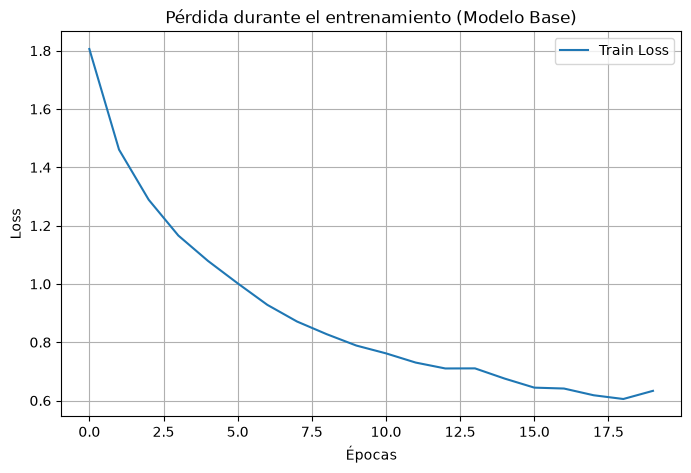

In [10]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

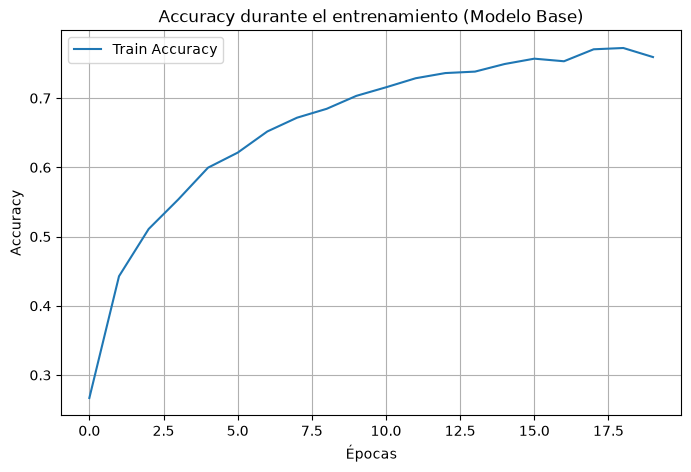

In [11]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [12]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

134/134 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step
===== TRAIN =====
Accuracy: 0.8630841121495327
F1-score: 0.8633361738215056

===== TEST =====
Accuracy: 0.7663551401869159
F1-score: 0.7659402860345277


## Interpretación de los resultados del modelo base

Después de entrenar durante 20 épocas, se obtuvieron los siguientes resultados en la evaluación:

| Conjunto | Accuracy | F1-score ponderado |
| --- | ---: | ---: |
| Entrenamiento | 0.82477 | 0.82180 |
| Prueba | 0.73551 | 0.73192 |

### Conclusión

El modelo clasifica correctamente aproximadamente el 73.55 % de las imágenes del conjunto de prueba. Este resultado sirve como referencia para comparar el modelo base con la versión optimizada.

## MODELO CNN OPTIMIZADO

In [2]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    shear_range=0.2, #las imágenes pueden ser deformadas hasta un 20%
    zoom_range=0.2, #las imágenes pueden aumentarse hasta un 20% en su tamaño original.
    horizontal_flip=True, #voltear horizontalmente las imágenes de manera aleatoria durante el entrenamiento
    rotation_range=20, #rotacion de las imágenes (20 grados)
    fill_mode='nearest' # Rellena los píxeles fuera de los límites de la imagen con los valores más cercanos
)

In [4]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom
import tensorflow as tf

# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers

modelo_opt = Sequential() # Se crea un nuevo modelo secuencial para el modelo optimizado, que permitirá construir una arquitectura más compleja añadiendo capas de manera secuencial.

# Capas convolucionales con normalización por lotes y activación ReLU para mejorar la capacidad de extracción de características, seguidas de capas de pooling para reducir la dimensionalidad.
modelo_opt.add(Conv2D(16, (3,3), input_shape=(150,150,3))) 
modelo_opt.add(layers.BatchNormalization()) # La normalización por lotes ayuda a estabilizar y acelerar el entrenamiento al normalizar las activaciones de la capa anterior, lo que puede mejorar la convergencia del modelo.
modelo_opt.add(layers.Activation('relu')) # La función de activación ReLU introduce no linealidad en el modelo, lo que permite aprender relaciones más complejas entre las características extraídas por la capa convolucional.
modelo_opt.add(MaxPooling2D(2,2)) # Agrega una capa de pooling que reduce la dimensionalidad de las características extraídas por la capa convolucional, utilizando un tamaño de ventana de 2x2.

modelo_opt.add(Conv2D(32, (3,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# capa flatten para convertir las características extraídas en un vector unidimensional, seguido de capas densas con dropout para prevenir el sobreajuste y mejorar la capacidad de generalización del modelo.
modelo_opt.add(Flatten())

# Capas densas para la clasificación final, con dropout para prevenir el sobreajuste.
modelo_opt.add(Dense(128, activation='relu'))
modelo_opt.add(Dropout(0.2))

modelo_opt.add(Dense(64, activation='relu'))
modelo_opt.add(Dropout(0.2))

modelo_opt.add(Dense(32, activation='relu'))
modelo_opt.add(Dropout(0.2))

modelo_opt.add(Dense(7, activation='softmax'))

modelo_opt.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

c:\Users\Luis Felipe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=16),
    epochs=150
)

ValueError: Invalid dtype: str352

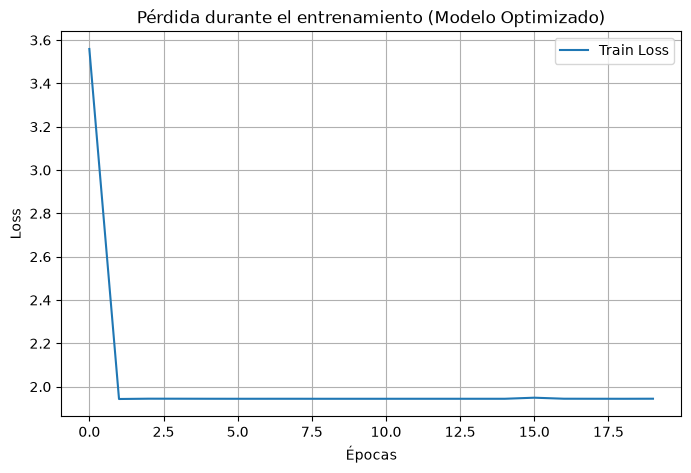

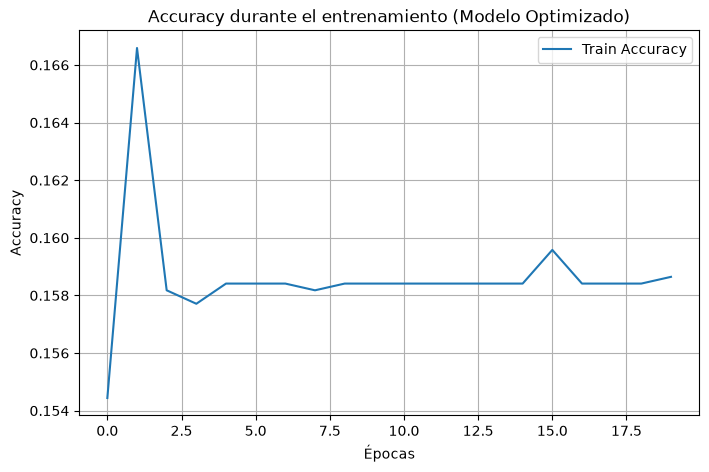

In [ ]:
import matplotlib.pyplot as plt

# =========================
# LOSS
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

134/134 ━━━━━━━━━━━━━━━━━━━━ 17s 115ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step
===== TRAIN =====
Accuracy: 0.15841121495327104
F1-score: 0.04332505193155214

===== TEST =====
Accuracy: 0.15794392523364487
F1-score: 0.04308720478528811


aqui sacar conclusiones

In [ ]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_cars.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

# Despliegue

Cargando modelo y label encoder...
Se encontraron 802 imágenes. Procesando...
[Convertible] 00134_Mercedes-Benz-300-Class-Convertible-1993_jpg.rf.491a23de6a3854af9ff421eaa8c13556.jpg → Predicción: SUV


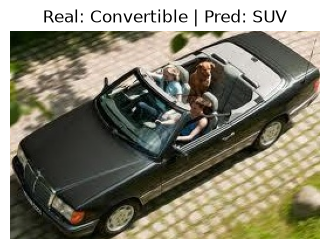

[Convertible] 00165_BMW-M6-Convertible-2010_jpg.rf.56a6bb8baa3348c08d25ce1105c0e233.jpg → Predicción: SUV


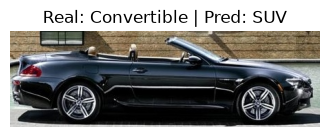

[Convertible] 00413_Chrysler-Crossfire-Convertible-2008_jpg.rf.c9df456418c955bb6835f088ace41039.jpg → Predicción: SUV


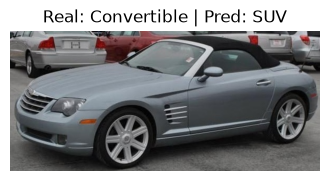

[Convertible] 00538_Ford-Mustang-Convertible-2007_jpg.rf.733b54a57012f683acb6a13cd32932d2.jpg → Predicción: SUV


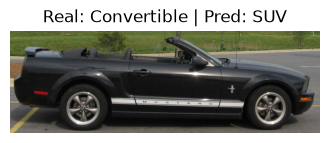

[Convertible] 00609_Geo-Metro-Convertible-1993_jpg.rf.3e94d6d6d17f6adcfbfb40dad8ba1a16.jpg → Predicción: SUV


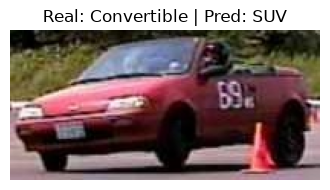

[Convertible] 00675_BMW-Z4-Convertible-2012_jpg.rf.8e38f5d9a0c5d69ba65308f3bee01485.jpg → Predicción: SUV


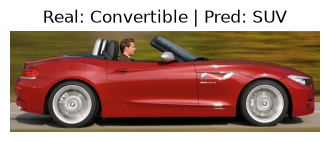

[Convertible] 00961_Mercedes-Benz-300-Class-Convertible-1993_jpg.rf.c8e5adbfa1cb5fae08113cadcf532048.jpg → Predicción: SUV


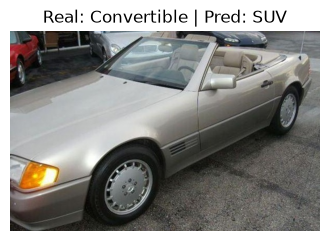

[Convertible] 01036_BMW-1-Series-Convertible-2012_jpg.rf.4919765524dc9cb21a6718bd56a46fac.jpg → Predicción: SUV


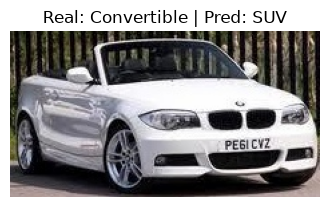

[Convertible] 01148_Aston-Martin-Virage-Convertible-2012_jpg.rf.0c772530722651427b45d6dd6b298898.jpg → Predicción: SUV


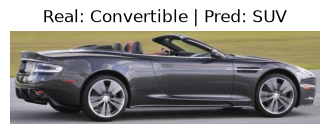

[Convertible] 01167_Audi-S5-Convertible-2012_jpg.rf.b54a1ee322804803ffd446ffc2be09f4.jpg → Predicción: SUV


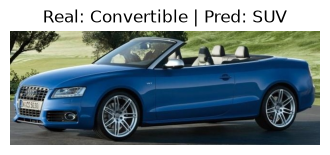

[Convertible] 01218_Mercedes-Benz-300-Class-Convertible-1993_jpg.rf.55bc07e98ac3ec4ab680f26d5c35a6a3.jpg → Predicción: SUV


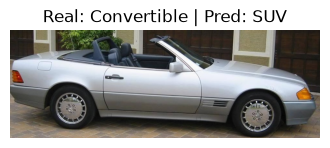

[Convertible] 01273_Ferrari-California-Convertible-2012_jpg.rf.571e9d32860326c2ccccc5d322fa9f07.jpg → Predicción: SUV


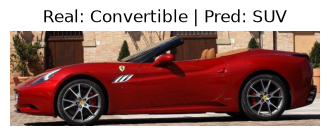

[Convertible] 01278_Chrysler-Crossfire-Convertible-2008_jpg.rf.785980fc69fefb43dcaabbc738a2b956.jpg → Predicción: SUV


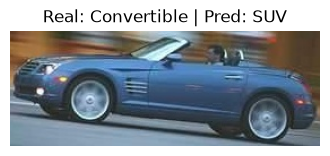

[Convertible] 01297_Audi-RS-4-Convertible-2008_jpg.rf.ce5cd633f7126caeb30661ff47dd05e0.jpg → Predicción: SUV


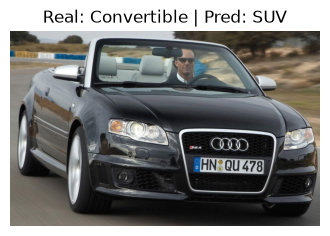

[Convertible] 01324_Bentley-Continental-Supersports-Conv-Convertible-2012_jpg.rf.49ffc0ae7a5604c9d1e6ae4d476d921f.jpg → Predicción: SUV


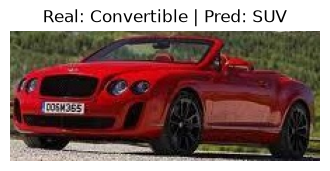

[Convertible] 01334_Spyker-C8-Convertible-2009_jpg.rf.f19a87b9890e14ed4f0b0bbfe0844d25.jpg → Predicción: SUV


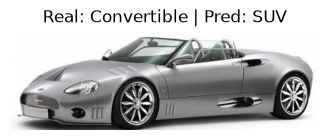

[Convertible] 01358_Chevrolet-Camaro-Convertible-2012_jpg.rf.817b54d01fbf50d47522bdd0b0e35854.jpg → Predicción: SUV


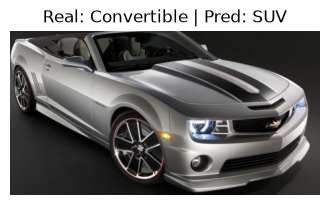

[Convertible] 01359_Chrysler-Crossfire-Convertible-2008_jpg.rf.a916a2dbe21e93d52278a93e20fd803d.jpg → Predicción: SUV


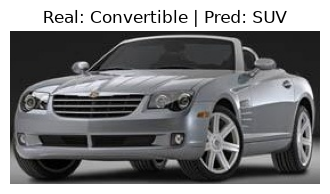

[Convertible] 01360_Chevrolet-Camaro-Convertible-2012_jpg.rf.a98f7d5fd54df4f40bca1fd14787fecc.jpg → Predicción: SUV


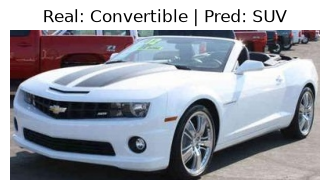

[Convertible] 01483_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.e90f4559cebd580d6141d62275e55b29.jpg → Predicción: SUV


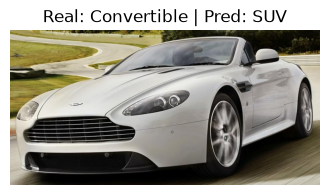

[Convertible] 01572_Chrysler-Crossfire-Convertible-2008_jpg.rf.2f714c793812c1efe1869c0ffe140dd7.jpg → Predicción: SUV


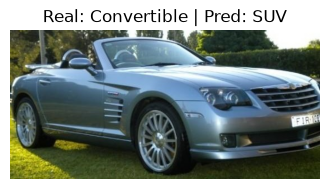

[Convertible] 01658_Rolls-Royce-Phantom-Drophead-Coupe-Convertible-2012_jpg.rf.581a4114a9cb39641f0cc70bb50fb71d.jpg → Predicción: SUV


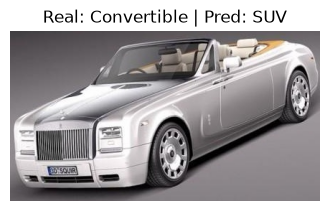

[Convertible] 01862_Ferrari-California-Convertible-2012_jpg.rf.07914cea27d05647b62b4890e5f11152.jpg → Predicción: SUV


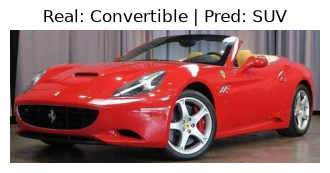

[Convertible] 01971_Chrysler-Sebring-Convertible-2010_jpg.rf.6561e6889c98257b5100f3c68a3b2520.jpg → Predicción: SUV


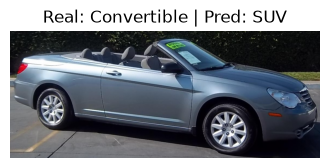

[Convertible] 02016_Chrysler-Sebring-Convertible-2010_jpg.rf.611903c4162de6cf9bfd070488e3c402.jpg → Predicción: SUV


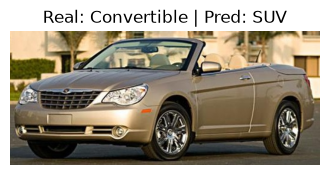

[Convertible] 02089_Geo-Metro-Convertible-1993_jpg.rf.37cd9c4d6a8625bbd65684676de111d3.jpg → Predicción: SUV


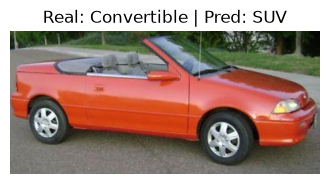

[Convertible] 02377_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.467c936c7b4e2db30e1592326064bc47.jpg → Predicción: SUV


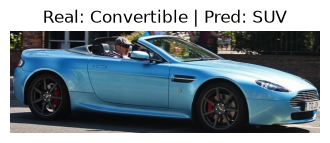

[Convertible] 02484_Aston-Martin-Virage-Convertible-2012_jpg.rf.0c6818b9ed9c22b570dc1411e3570d7b.jpg → Predicción: SUV


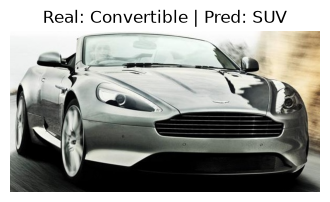

[Convertible] 02673_Chevrolet-Camaro-Convertible-2012_jpg.rf.94ccf5505978e1c2113e9f400aadc9ad.jpg → Predicción: SUV


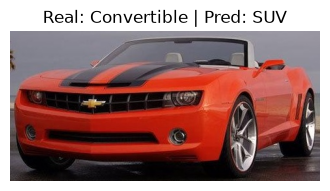

[Convertible] 02686_BMW-Z4-Convertible-2012_jpg.rf.cd47937f9b311e255419f6a5ddcdd55b.jpg → Predicción: SUV


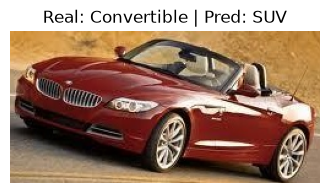

[Convertible] 02722_Ferrari-458-Italia-Convertible-2012_jpg.rf.60343b68965062101ac9586d09f3f586.jpg → Predicción: SUV


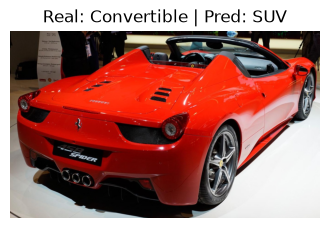

[Convertible] 02885_Audi-RS-4-Convertible-2008_jpg.rf.2e339573251ecc58527d92d5bf856ac2.jpg → Predicción: SUV


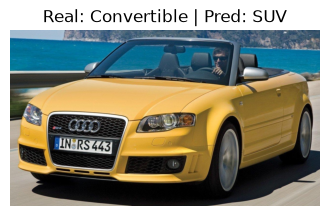

[Convertible] 03178_BMW-6-Series-Convertible-2007_jpg.rf.2cb9d0010a7a643c4dc4257223bc62ac.jpg → Predicción: SUV


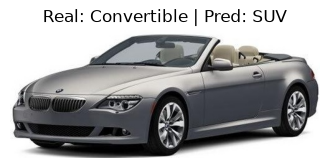

[Convertible] 03311_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.1ebd717a2522b41db5d81f264c888d05.jpg → Predicción: SUV


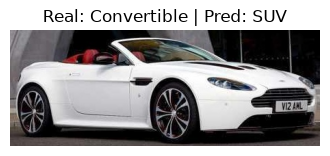

[Convertible] 03575_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.a23bcebe84cbf1ca9d9c4494b6f2177a.jpg → Predicción: SUV


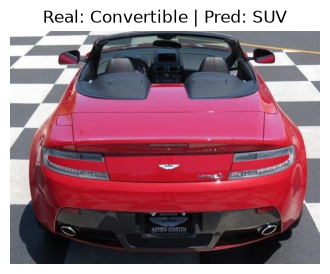

[Convertible] 03723_Audi-RS-4-Convertible-2008_jpg.rf.997a6fe5737a6ffb65119a57a87492f8.jpg → Predicción: SUV


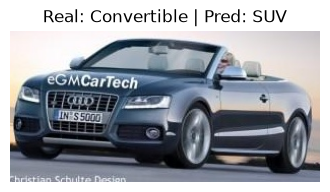

[Convertible] 04003_Chevrolet-Camaro-Convertible-2012_jpg.rf.0b260937bf47faa53960c881c5808f02.jpg → Predicción: SUV


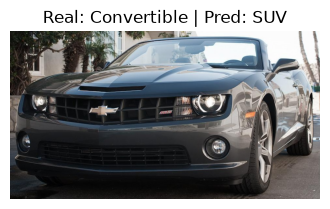

[Convertible] 04072_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.8acad251491281effefb6f1c75cef452.jpg → Predicción: SUV


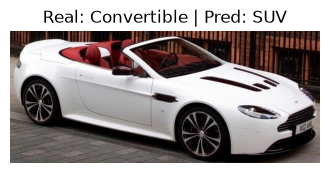

[Convertible] 04197_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.78ec7f119ec5e7c8e40bdeac67634572.jpg → Predicción: SUV


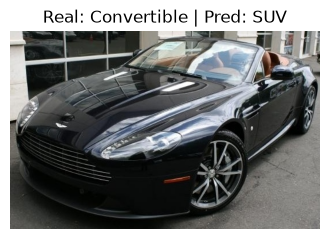

[Convertible] 04236_Ford-Mustang-Convertible-2007_jpg.rf.ac1885e1789ede4b81f9a36cdc8139bd.jpg → Predicción: SUV


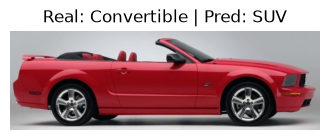

[Convertible] 04247_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.d28bb7cc7d34364a5a617c66cc9cc8a9.jpg → Predicción: SUV


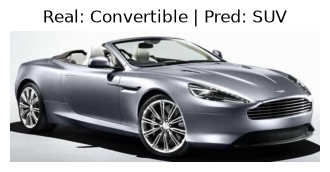

[Convertible] 04280_Chevrolet-Camaro-Convertible-2012_jpg.rf.7b54e222fe467b4fce85cc2ed8b6ee09.jpg → Predicción: SUV


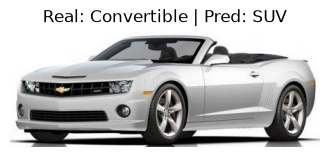

[Convertible] 04339_BMW-M6-Convertible-2010_jpg.rf.a2738ee0ef6afdd57d4db39a060fdeec.jpg → Predicción: SUV


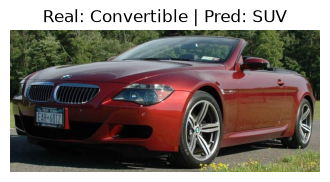

[Convertible] 04548_BMW-1-Series-Convertible-2012_jpg.rf.6c2b08a7a3df841a19593b2d78a2c969.jpg → Predicción: SUV


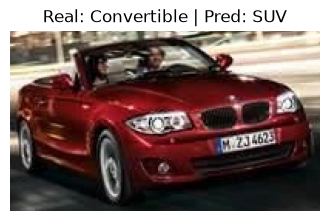

[Convertible] 04674_MINI-Cooper-Roadster-Convertible-2012_jpg.rf.412801fa25163d85d6e1ba8d5c42260c.jpg → Predicción: SUV


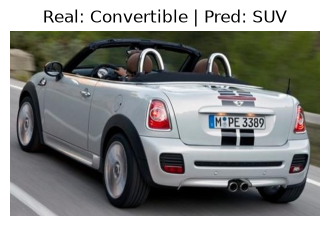

[Convertible] 04779_Bentley-Continental-Supersports-Conv-Convertible-2012_jpg.rf.2972dc10ef8f0f5e1e64997701e5ba20.jpg → Predicción: SUV


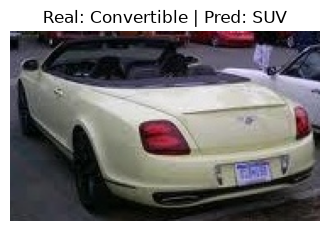

[Convertible] 04781_MINI-Cooper-Roadster-Convertible-2012_jpg.rf.641892973a241bf5746afe0006d9d95d.jpg → Predicción: SUV


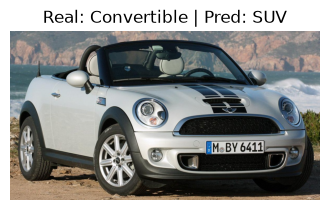

[Convertible] 04796_Ford-Mustang-Convertible-2007_jpg.rf.7d3e7d0c24011ea0bc145b1a9069b00a.jpg → Predicción: SUV


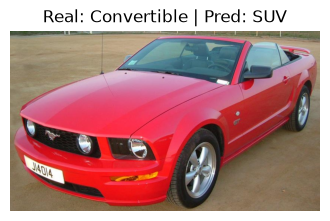

[Convertible] 04818_Audi-RS-4-Convertible-2008_jpg.rf.d85bf6d0ab2fa61c734dde6f7a45ec2a.jpg → Predicción: SUV


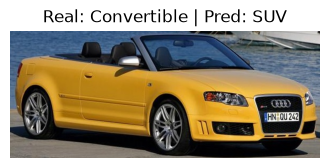

[Convertible] 04858_Chrysler-Sebring-Convertible-2010_jpg.rf.fa57ef0d177103c4b2d4d374bf20139d.jpg → Predicción: SUV


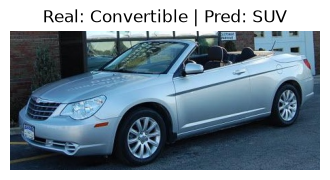

[Convertible] 04867_MINI-Cooper-Roadster-Convertible-2012_jpg.rf.78f195d5684d054b3e2cf0fb26b3c799.jpg → Predicción: SUV


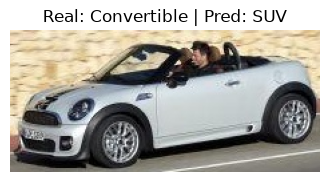

[Convertible] 04927_BMW-Z4-Convertible-2012_jpg.rf.5c5b05978d4be259daf4c9e9b94f16e6.jpg → Predicción: SUV


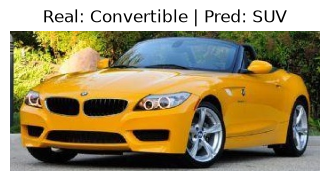

[Convertible] 05163_BMW-Z4-Convertible-2012_jpg.rf.56a4e5d2657524b018ac0aa729c113a9.jpg → Predicción: SUV


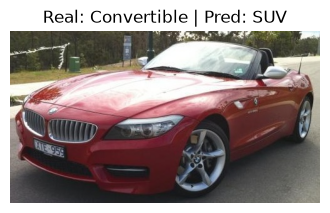

[Convertible] 05436_Chevrolet-Corvette-Convertible-2012_jpg.rf.f85b85332bfffdb35ceef0bde3ba254a.jpg → Predicción: SUV


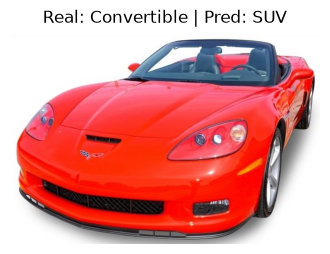

[Convertible] 05494_Rolls-Royce-Phantom-Drophead-Coupe-Convertible-2012_jpg.rf.fcf350d22638a45ea121b7984f2af087.jpg → Predicción: SUV


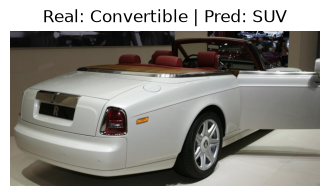

[Convertible] 05560_MINI-Cooper-Roadster-Convertible-2012_jpg.rf.62d28fabfae4f6ec15bc53101a30b523.jpg → Predicción: SUV


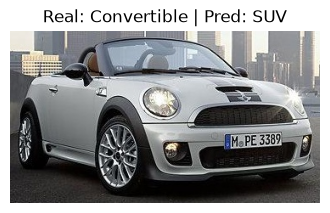

[Convertible] 05852_BMW-Z4-Convertible-2012_jpg.rf.454bf2a8492a12c3ff08152bb8afe19d.jpg → Predicción: SUV


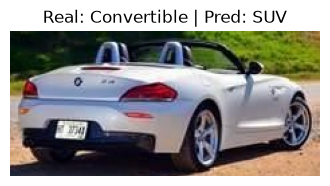

[Convertible] 05868_BMW-Z4-Convertible-2012_jpg.rf.47d8869427d7dab26caa2e719a774db5.jpg → Predicción: SUV


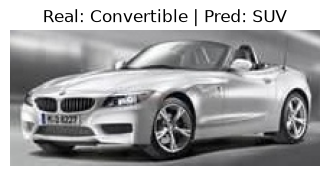

[Convertible] 05878_BMW-1-Series-Convertible-2012_jpg.rf.881b81b3388eef2240661573e7dcd79c.jpg → Predicción: SUV


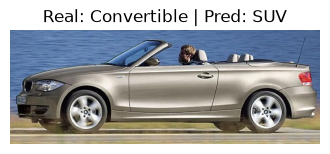

[Convertible] 05885_Chrysler-Crossfire-Convertible-2008_jpg.rf.22178900dee9d21d23841fa933c087ce.jpg → Predicción: SUV


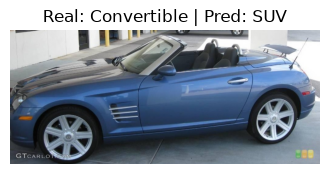

[Convertible] 05892_BMW-6-Series-Convertible-2007_jpg.rf.d81a32485bc74a0ab6d5e95b254b7284.jpg → Predicción: SUV


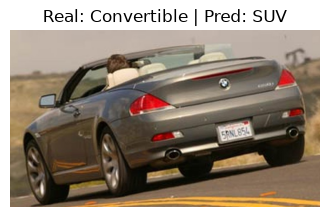

[Convertible] 06024_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.b6bc3db91cd715cc31b6141c9c216f57.jpg → Predicción: SUV


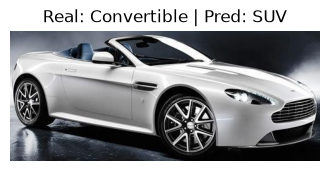

[Convertible] 06081_Mercedes-Benz-300-Class-Convertible-1993_jpg.rf.6435981f544ff04c6201906bf7cafdbb.jpg → Predicción: SUV


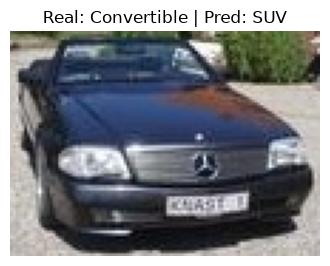

[Convertible] 06162_Ferrari-458-Italia-Convertible-2012_jpg.rf.c31d141ce82ba587a62c5effbb61276e.jpg → Predicción: SUV


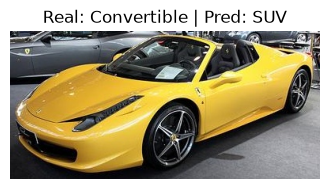

[Convertible] 06163_Audi-RS-4-Convertible-2008_jpg.rf.72920209c3dae0a0cb78e9c77602b5b2.jpg → Predicción: SUV


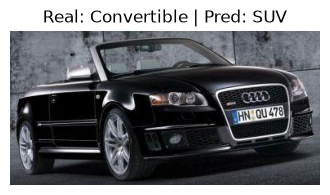

[Convertible] 06166_Chevrolet-Corvette-Convertible-2012_jpg.rf.a65df1f8ef7c334f0867d5665b9aca4f.jpg → Predicción: SUV


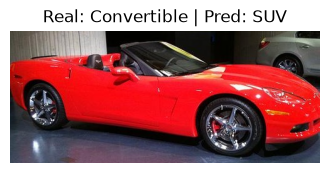

[Convertible] 06386_Chevrolet-Corvette-Convertible-2012_jpg.rf.1586792a236e53d0dd2544ada44f078b.jpg → Predicción: SUV


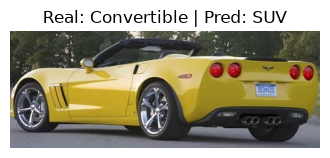

[Convertible] 06401_Ferrari-California-Convertible-2012_jpg.rf.02b483a4a3d5ed009148528551206bff.jpg → Predicción: SUV


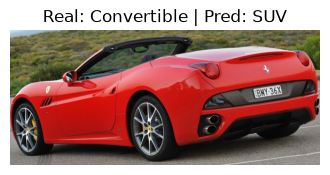

[Convertible] 06523_Rolls-Royce-Phantom-Drophead-Coupe-Convertible-2012_jpg.rf.8107ea2572008c1ace62e9977ee83045.jpg → Predicción: SUV


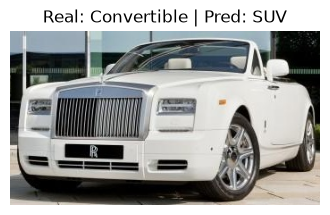

[Convertible] 06657_Chrysler-PT-Cruiser-Convertible-2008_jpg.rf.bab83f824c04dc4d592866beec0b8eeb.jpg → Predicción: SUV


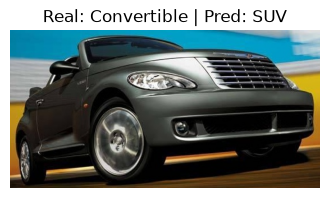

[Convertible] 06703_BMW-1-Series-Convertible-2012_jpg.rf.149a1cfb6a80f66e5e881df4ac3e6fae.jpg → Predicción: SUV


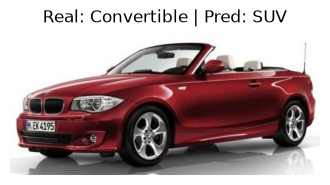

[Convertible] 06710_Rolls-Royce-Phantom-Drophead-Coupe-Convertible-2012_jpg.rf.4f4c0774aa925aa0b92bcc8d1acaa983.jpg → Predicción: SUV


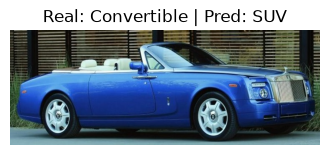

[Convertible] 06716_Audi-S5-Convertible-2012_jpg.rf.e2835436f9b127672f4c78ca5d2e42ff.jpg → Predicción: SUV


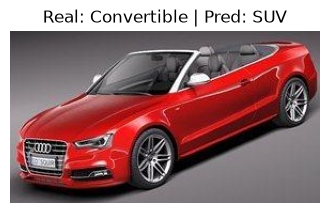

[Convertible] 06793_Audi-S5-Convertible-2012_jpg.rf.5daf8bbe78df6caa769862637f3a10f7.jpg → Predicción: SUV


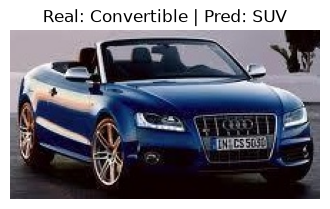

[Convertible] 06998_Rolls-Royce-Phantom-Drophead-Coupe-Convertible-2012_jpg.rf.0eec35347cfbf47cfa54813d9dcf23c2.jpg → Predicción: SUV


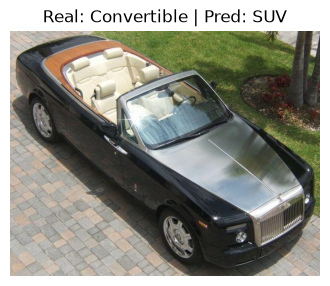

[Convertible] 07040_BMW-6-Series-Convertible-2007_jpg.rf.8e2b21dbbae82811a4b7ea3b7de772e9.jpg → Predicción: SUV


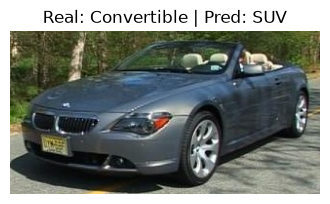

[Convertible] 07278_Aston-Martin-V8-Vantage-Convertible-2012_jpg.rf.7dae7672150aa2aea3111f172d9daf7e.jpg → Predicción: SUV


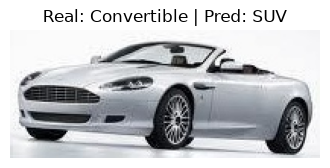

[Convertible] 07386_Aston-Martin-Virage-Convertible-2012_jpg.rf.1d91466943b35691cdad95695ef0c7cd.jpg → Predicción: SUV


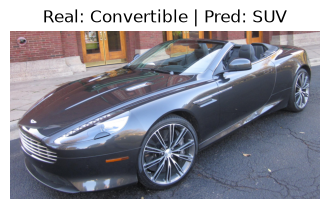

[Convertible] 07749_Chevrolet-Corvette-Convertible-2012_jpg.rf.242184fe97932010f3cc97e34e7e17ff.jpg → Predicción: SUV


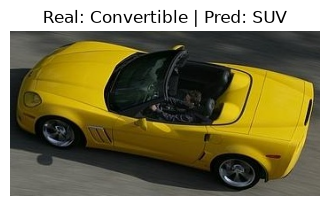

[Convertible] 07905_Ford-Mustang-Convertible-2007_jpg.rf.5f0f16218764f5aa353be5125a86cc9d.jpg → Predicción: SUV


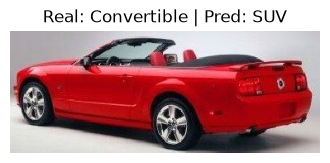

[Convertible] 108_jpg.rf.b3737f6053e3839930a999a2d88a41ea.jpg → Predicción: SUV


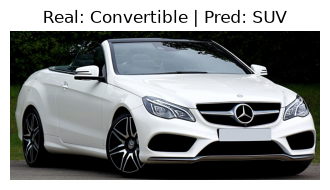

[Convertible] 115_jpg.rf.6db8a8d4473163b9442a71ce91bd2553.jpg → Predicción: SUV


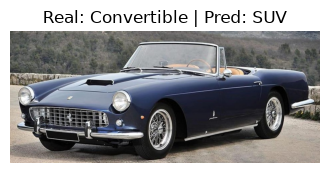

[Convertible] 11_jpg.rf.ea923c3a0ff80e933d12bfb74b350e06.jpg → Predicción: SUV


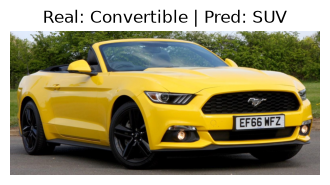

[Convertible] 129_jpg.rf.afad0bbb8cb758bf600130c2eff01cda.jpg → Predicción: SUV


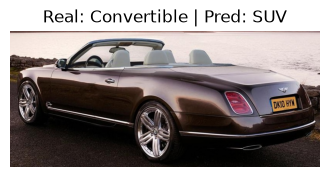

[Convertible] 12_jpg.rf.2aa89b92e0ee356c4c82dee803c5d74c.jpg → Predicción: SUV


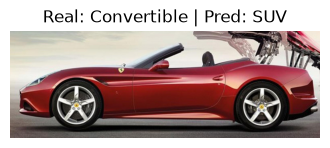

[Convertible] 139_jpg.rf.bfa5d350f6862fa3bd866397054625cf.jpg → Predicción: SUV


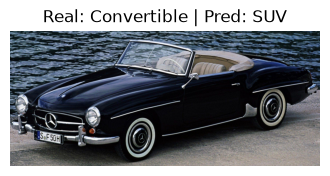

[Convertible] 13_jpg.rf.cb33a2701aa57573816e20d8e01b41f3.jpg → Predicción: SUV


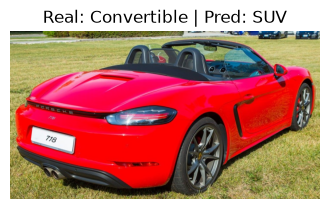

[Convertible] 142_jpg.rf.6cf6dd3b63953e7116bf37828e7b889f.jpg → Predicción: SUV


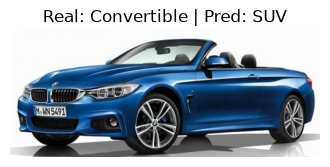

[Convertible] 151_jpg.rf.b3d234e67ecdde8d593be2e01b339234.jpg → Predicción: SUV


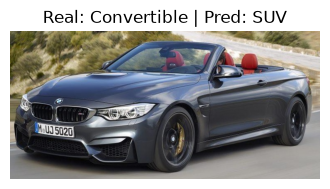

[Convertible] 183_jpg.rf.1cdee3f934256fbe0bde099dfb097a10.jpg → Predicción: SUV


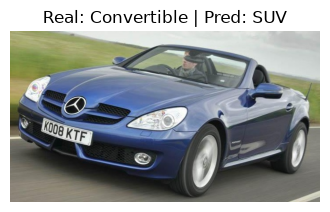

[Convertible] 186_jpg.rf.c6296f5e25a5236b862f260b8bb29dd3.jpg → Predicción: SUV


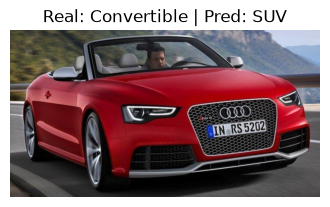

[Convertible] 18_jpg.rf.764e72fcf193170d740ac7865da9aa13.jpg → Predicción: SUV


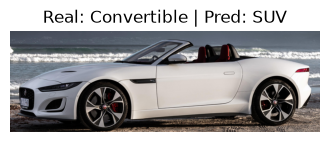

[Convertible] 191_jpg.rf.06c926cb4526132c3da05a5bd985cf56.jpg → Predicción: SUV


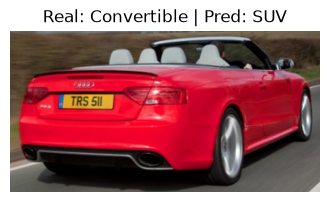

[Convertible] 193_jpg.rf.f2d23a89817ace46c43018640d51be8c.jpg → Predicción: SUV


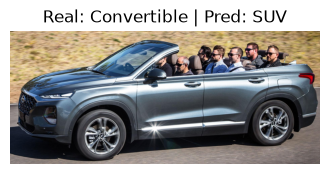

[Convertible] 198_jpg.rf.db3a2a52b6196a8d18fa18e021b13459.jpg → Predicción: SUV


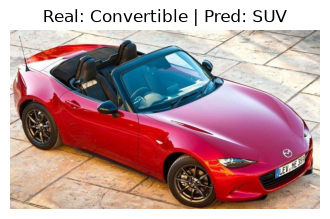

[Convertible] 224_jpg.rf.71fe490a822a298c2211e343daabbfc9.jpg → Predicción: SUV


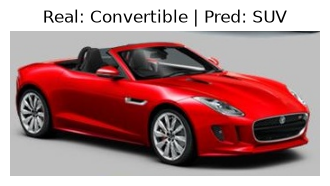

[Convertible] 239_jpg.rf.da32df2c5557a1598a855eb3469d515b.jpg → Predicción: SUV


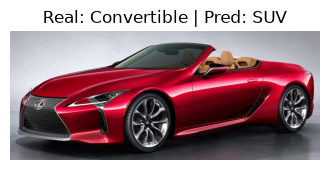

[Convertible] 240_jpg.rf.aab65e4cda3fb83a6f4af7b54416e467.jpg → Predicción: SUV


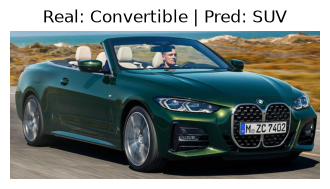

[Convertible] 242_jpg.rf.6ee97d8548a263045ef618b5acd8731f.jpg → Predicción: SUV


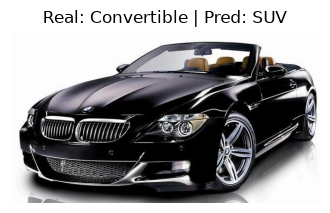

[Convertible] 247_jpg.rf.d6324e58c0e4c3f26ddb12d2f188b09f.jpg → Predicción: SUV


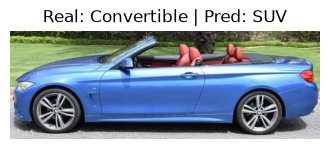

[Convertible] 249_jpg.rf.8aea960af12e68a5dab2a59db40f735d.jpg → Predicción: SUV


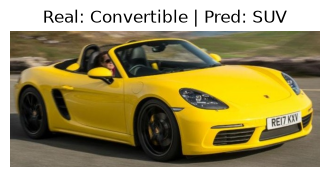

[Convertible] 251_jpg.rf.9b3b1f857a2ea2d3eca0fc08159510c9.jpg → Predicción: SUV


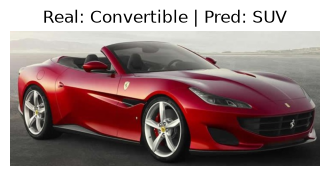

[Convertible] 252_jpg.rf.d00bb57ff477244cb4bd148765836e28.jpg → Predicción: SUV


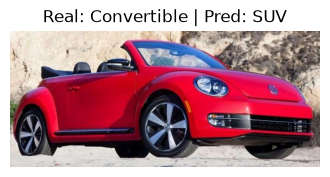

[Convertible] 258_jpg.rf.282ee9ec11ae1242e1bff996474b5066.jpg → Predicción: SUV


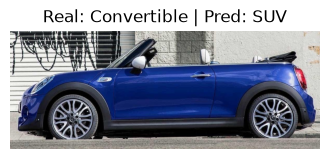

[Convertible] 265_jpg.rf.08dfaee150a1c7bf923aa7575caffa1c.jpg → Predicción: SUV


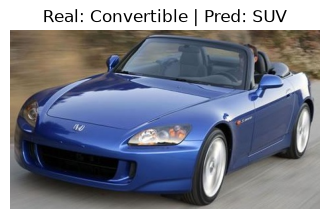

[Convertible] 26_jpg.rf.ad406659927faab4b44238f1cbb02e2e.jpg → Predicción: SUV


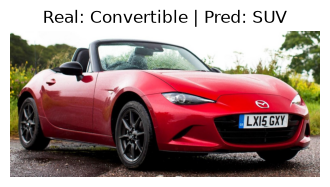

[Convertible] 278_jpg.rf.e4d00ef8bba553b48b8f799e74f64f82.jpg → Predicción: SUV


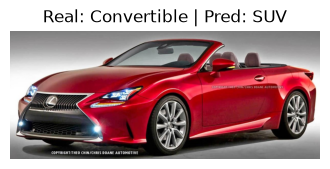

[Convertible] 292_jpg.rf.f610172d41911e57a6ecc8ddf4e39901.jpg → Predicción: SUV


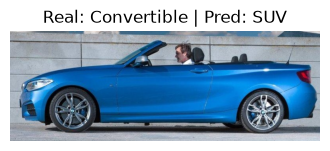

[Convertible] 296_jpg.rf.410fe9329e33ce746c0ad6f8cb1ccf93.jpg → Predicción: SUV


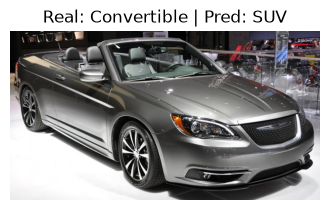

[Convertible] 305_jpg.rf.ff810cf9921ec0f0b27774c4906c5400.jpg → Predicción: SUV


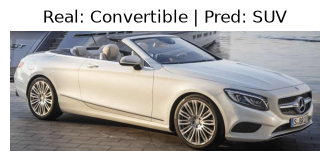

[Convertible] 312_jpg.rf.cc5920af81661f8b525c25802d6cde07.jpg → Predicción: SUV


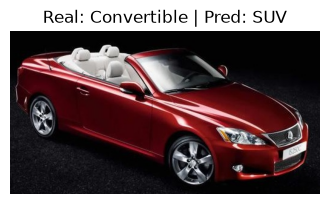

[Convertible] 328_jpg.rf.cac6afc0123db301c1da9be22fb52c4c.jpg → Predicción: SUV


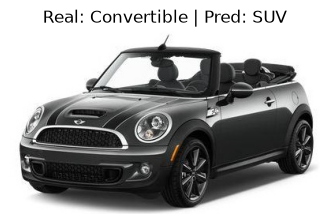

[Convertible] 32_jpg.rf.fa91c15a10aaae6a3c5fff95e91561f1.jpg → Predicción: SUV


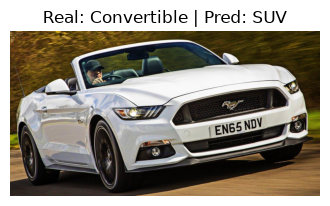

[Convertible] 35_jpg.rf.c743da7ac0c626d9de7e070b8d9d68fc.jpg → Predicción: SUV


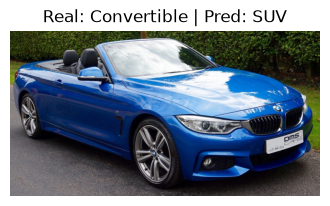

[Convertible] 36_jpg.rf.21b0ca3b18aa413a8f07123048ce6401.jpg → Predicción: SUV


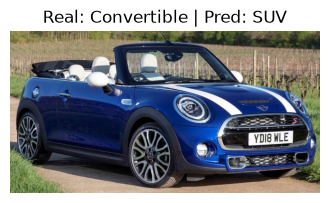

[Convertible] 44_jpg.rf.ec1bbc8fcb925eb05b1fa3be89a21a37.jpg → Predicción: SUV


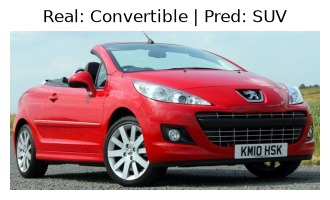

[Convertible] 54_jpg.rf.6bc6c6684059fcd5b26999d611d80595.jpg → Predicción: SUV


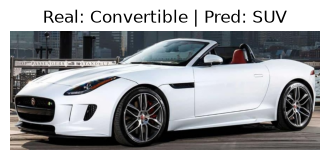

[Convertible] 64_jpg.rf.aa7e8b2ae70353fb6b37a6b525d6141d.jpg → Predicción: SUV


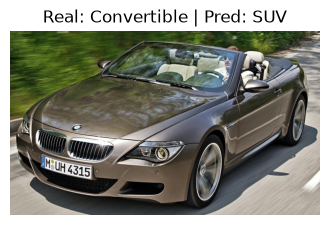

[Convertible] 81_jpg.rf.a059c9a41cf163ebddf0bb1fd6ded458.jpg → Predicción: SUV


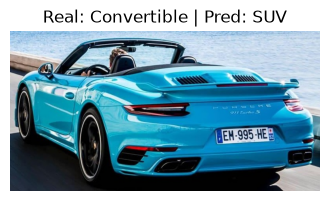

[Convertible] 83_jpg.rf.a66e3db9a6229ba8e9b231a3b9ee7e13.jpg → Predicción: SUV


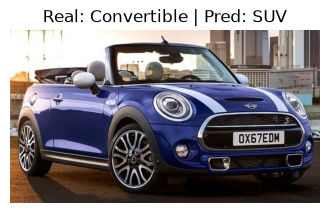

[Convertible] d812eb2f-66b6-11eb-9fba-8c164571e025_jpg.rf.9ec3081f802d4ae30935ae3ad3d3f708.jpg → Predicción: SUV


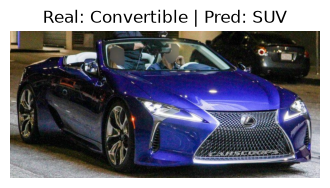

[Convertible] d8131228-66b6-11eb-a6fa-8c164571e025_jpg.rf.da6954ebc64285c0bfe2ae370cd8f766.jpg → Predicción: SUV


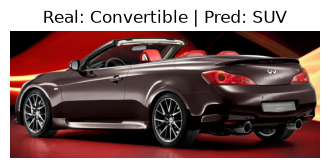

[Convertible] d8131231-66b6-11eb-be87-8c164571e025_jpg.rf.b2538053e2b8aac00577bade42934fc9.jpg → Predicción: SUV


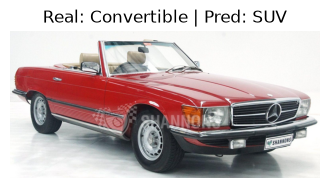

[Convertible] d8131234-66b6-11eb-b5bf-8c164571e025_jpg.rf.b4fccd5abab247272eda356490f93ef0.jpg → Predicción: SUV


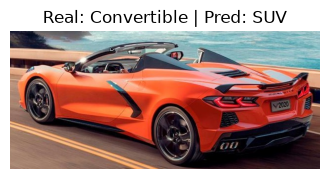

[Convertible] d813123d-66b6-11eb-bc66-8c164571e025_jpg.rf.c0d7976d647df7b7b7aa923f825a95f5.jpg → Predicción: SUV


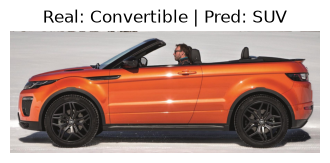

[Convertible] d813391d-66b6-11eb-9714-8c164571e025_jpg.rf.614a6c7d06297078ac0460dd7e4f1c2a.jpg → Predicción: SUV


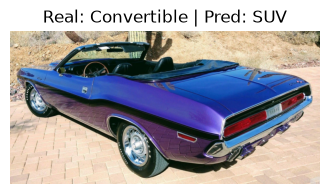

[Convertible] d8133923-66b6-11eb-ae53-8c164571e025_jpg.rf.b08eb487aa27a1295f77ec63dc3fd23c.jpg → Predicción: SUV


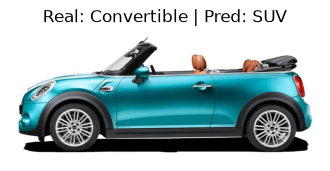

[Convertible] d8133934-66b6-11eb-a463-8c164571e025_jpg.rf.b12da4292adf8553a39f08890deed29f.jpg → Predicción: SUV


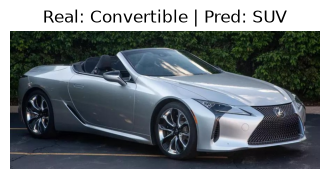

[Convertible] d8136013-66b6-11eb-b242-8c164571e025_jpg.rf.e70e7245d3c73371c16e0b05ea6400df.jpg → Predicción: SUV


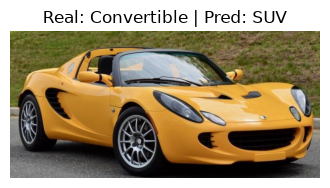

[Convertible] d8136029-66b6-11eb-9479-8c164571e025_jpg.rf.98966c552df1315ab6dbab7b49840736.jpg → Predicción: SUV


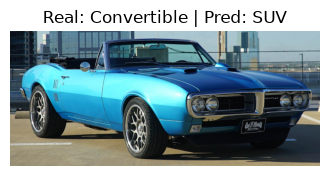

[Convertible] d813adfa-66b6-11eb-a497-8c164571e025_jpg.rf.baaf52b16702a9418d321a417bdace24.jpg → Predicción: SUV


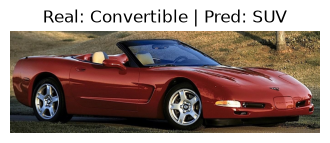

[Convertible] d813adfb-66b6-11eb-982b-8c164571e025_jpg.rf.3fb0b039751851c169731430ab5d368d.jpg → Predicción: SUV


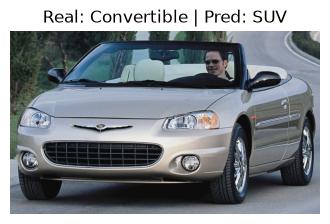

[Convertible] d813ae0b-66b6-11eb-956d-8c164571e025_jpg.rf.1ad4d0e0b508fc9906c0886d4ccfa8c8.jpg → Predicción: SUV


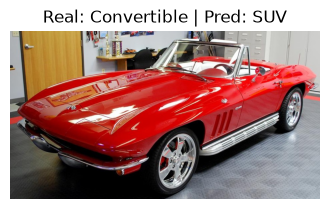

[Convertible] d813ae14-66b6-11eb-83e8-8c164571e025_jpg.rf.c82b05f3444a3d6210a676d749889257.jpg → Predicción: SUV


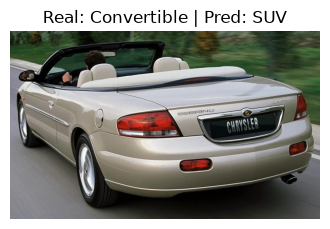

[Convertible] d813fc67-66b6-11eb-961e-8c164571e025_jpg.rf.721ccc129ce742ab564c8a1b3f907f53.jpg → Predicción: SUV


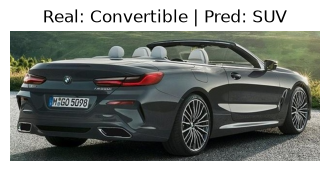

[Convertible] d813fc6f-66b6-11eb-8da7-8c164571e025_jpg.rf.05bfbf5c10c63a9ee8339cbb28b8c2bb.jpg → Predicción: SUV


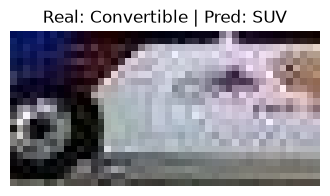

[Convertible] d8142320-66b6-11eb-8a47-8c164571e025_jpg.rf.b60900c3ce8ce175d6cbac10832521b5.jpg → Predicción: SUV


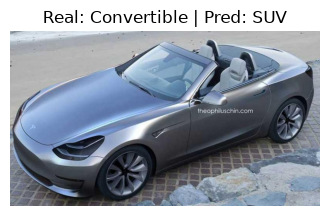

[Convertible] d8142324-66b6-11eb-b094-8c164571e025_jpg.rf.acbd5fcc30c00aab1a296bd9cab3dc25.jpg → Predicción: SUV


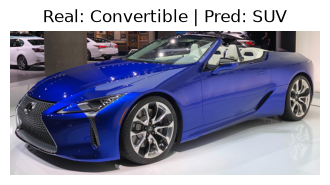

[Convertible] d8142329-66b6-11eb-8db3-8c164571e025_jpg.rf.d99424b4d7bbf02b7aedff8593be7e7b.jpg → Predicción: SUV


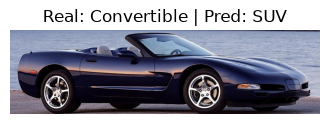

[Convertible] d8144a40-66b6-11eb-a28e-8c164571e025_jpg.rf.170846f19edd581694ab5c976e0141f6.jpg → Predicción: SUV


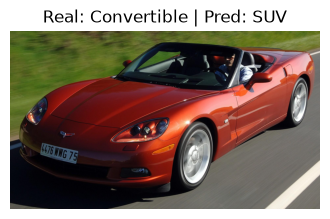

[Convertible] d814712a-66b6-11eb-a52d-8c164571e025_jpg.rf.fe14bffd52f329bac234475168d48b7f.jpg → Predicción: SUV


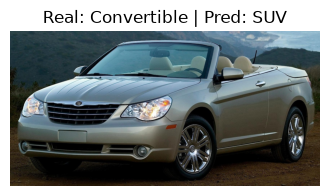

[Convertible] d8147132-66b6-11eb-af89-8c164571e025_jpg.rf.a8e906f628cb9ad08e09ee1c5acd25d5.jpg → Predicción: SUV


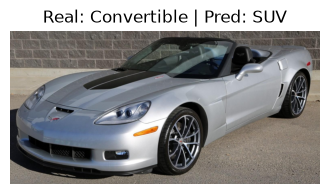

[Convertible] d8147136-66b6-11eb-8145-8c164571e025_jpg.rf.c420a77027442ed4b343c89764b17bcd.jpg → Predicción: SUV


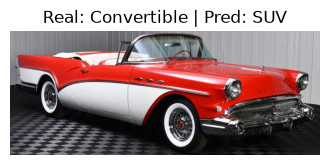

[Convertible] d8149822-66b6-11eb-b835-8c164571e025_jpg.rf.3c1bc58ef3da8aeefac898f7fc382d94.jpg → Predicción: SUV


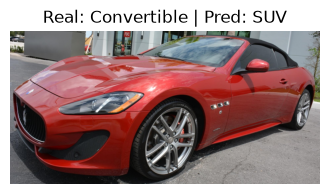

[Convertible] d8149837-66b6-11eb-b9e3-8c164571e025_jpg.rf.b29119e561c8c0b389091f0b12600e2d.jpg → Predicción: SUV


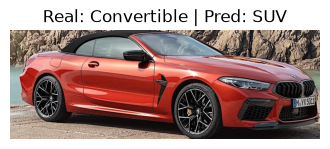

[Convertible] d814bf39-66b6-11eb-a4cb-8c164571e025_jpg.rf.d5ab471ffe435e78c827c476a1438d1f.jpg → Predicción: SUV


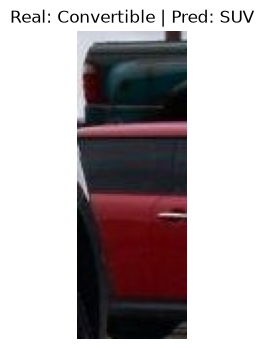

[Convertible] d814bf3a-66b6-11eb-8f56-8c164571e025_jpg.rf.60a6c16f11fde14f0457c45bbf02f4c6.jpg → Predicción: SUV


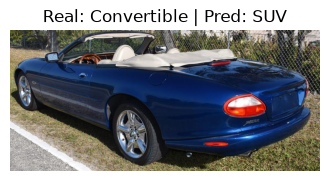

[Convertible] d814bf3b-66b6-11eb-8a69-8c164571e025_jpg.rf.ebee36db852b8144f46c5235cc864b8e.jpg → Predicción: SUV


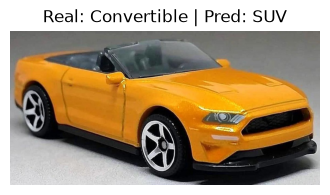

[Convertible] d814bf47-66b6-11eb-89f6-8c164571e025_jpg.rf.85fc9c17b4c05574b60938a0df95d2b0.jpg → Predicción: SUV


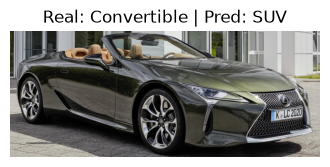

[Convertible] d814bf4e-66b6-11eb-9931-8c164571e025_jpg.rf.cd04af90c9f127d2e040d29fdfe67f5f.jpg → Predicción: SUV


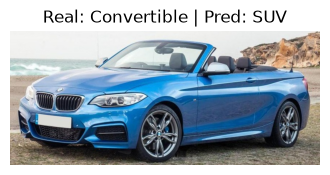

[Convertible] d814e62a-66b6-11eb-b4f1-8c164571e025_jpg.rf.66f7fc7d742632e86ee6210cdc1d02d9.jpg → Predicción: SUV


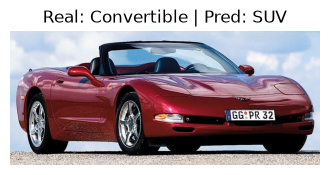

[Convertible] d814e634-66b6-11eb-80a8-8c164571e025_jpg.rf.ac1b689dc1e03881e86aab1b32385f9b.jpg → Predicción: SUV


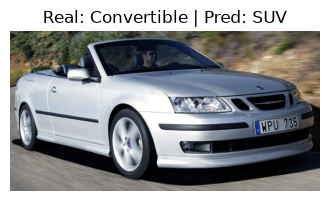

[Convertible] d8150d00-66b6-11eb-95a9-8c164571e025_jpg.rf.9af7c3d30f4f026f0f7d842bc20bffea.jpg → Predicción: SUV


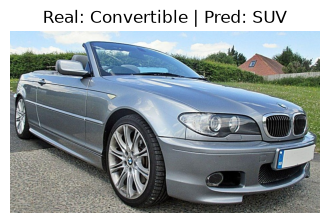

[Convertible] d8150d14-66b6-11eb-9cec-8c164571e025_jpg.rf.e1f06737c6e7a4663fe85f2a69b99094.jpg → Predicción: SUV


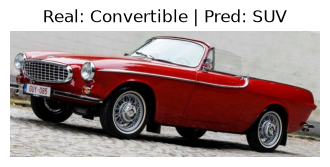

[Convertible] d8153414-66b6-11eb-acb4-8c164571e025_jpg.rf.5988f8aa99a4943fc6ca8ec710d833bd.jpg → Predicción: SUV


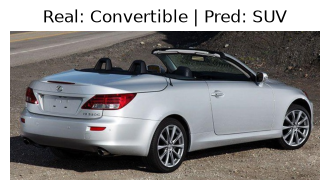

[Convertible] d8155ae1-66b6-11eb-9dc7-8c164571e025_jpg.rf.c047a180ba5b80c2bf7f18a55ed977c4.jpg → Predicción: SUV


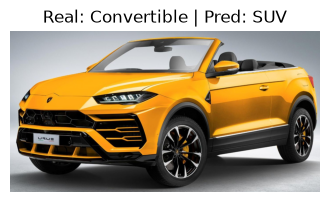

[Convertible] d81581e4-66b6-11eb-b8af-8c164571e025_jpg.rf.8f3e2751fad19dcc417ad73be6a790c8.jpg → Predicción: SUV


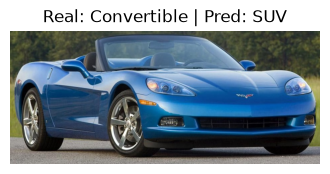

[Convertible] d815a8db-66b6-11eb-8ed2-8c164571e025_jpg.rf.08b387289cd85d7c0fefcaf710d133ed.jpg → Predicción: SUV


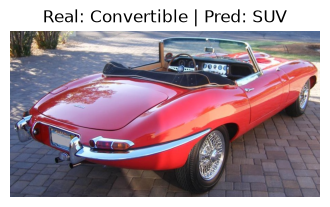

[Convertible] d815a8e4-66b6-11eb-8102-8c164571e025_jpg.rf.705b4b8f18869716e4991f57c3144835.jpg → Predicción: SUV


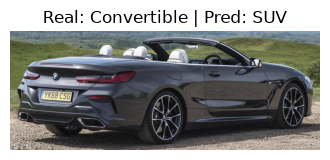

[Convertible] d815a8e5-66b6-11eb-be5f-8c164571e025_jpg.rf.49de9d71dcda7ac728c7286eb8fea738.jpg → Predicción: SUV


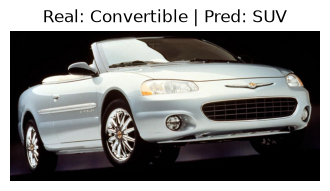

[Convertible] d815cfeb-66b6-11eb-881d-8c164571e025_jpg.rf.a1f0042ae6613b00528e946d989c07d5.jpg → Predicción: SUV


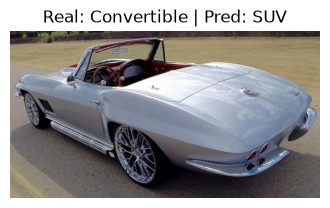

[Convertible] d815f6cc-66b6-11eb-9879-8c164571e025_jpg.rf.80232076b02eaed7a66790b172b57c8e.jpg → Predicción: SUV


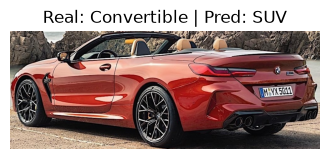

[Convertible] d8161de2-66b6-11eb-bd69-8c164571e025_jpg.rf.4dac1676476f6839049a4806d684e129.jpg → Predicción: SUV


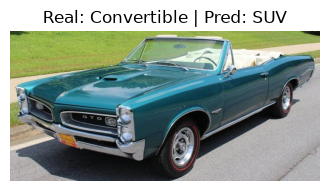

[Convertible] d81644b6-66b6-11eb-ba79-8c164571e025_jpg.rf.93f03da0cc6c6ee21e702526896e9c8e.jpg → Predicción: SUV


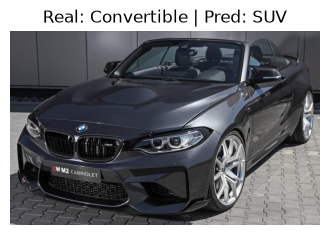

[Convertible] d81644be-66b6-11eb-957f-8c164571e025_jpg.rf.eb7c75ca4ffc7ece4244e5530c9216d8.jpg → Predicción: SUV


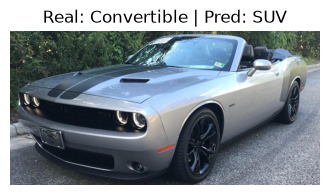

[Convertible] d8166bb9-66b6-11eb-b6cb-8c164571e025_jpg.rf.6a6b54984eca00b90d67388bff31bd58.jpg → Predicción: SUV


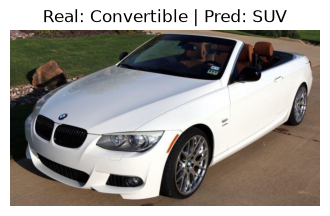

[Convertible] d8166bbd-66b6-11eb-980b-8c164571e025_jpg.rf.08557d466cc2a14c0456de356cb983ad.jpg → Predicción: SUV


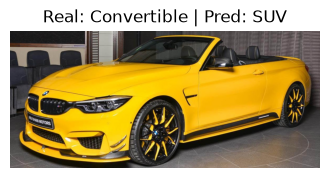

[Convertible] d8166bc7-66b6-11eb-93b9-8c164571e025_jpg.rf.490bcd4fb6865fdd3d95ced6159d0767.jpg → Predicción: SUV


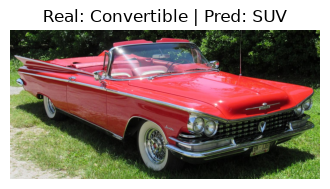

[Convertible] d8166bd1-66b6-11eb-8355-8c164571e025_jpg.rf.3bf7975a4fe7d1397b1a7d9ad25fe6e1.jpg → Predicción: SUV


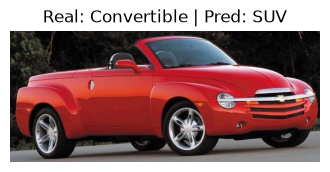

[Convertible] d8166bdb-66b6-11eb-ba90-8c164571e025_jpg.rf.f97b975905793c8bf3de0ee9f683e7a2.jpg → Predicción: SUV


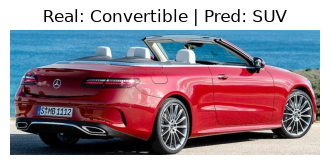

[Convertible] d8166be1-66b6-11eb-bd0b-8c164571e025_jpg.rf.03105c0db53157532cd6cf00c827cc2f.jpg → Predicción: SUV


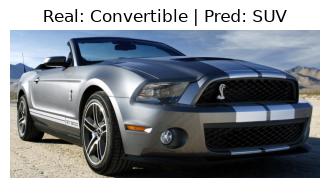

[Convertible] d8166be3-66b6-11eb-a8ca-8c164571e025_jpg.rf.4befa0d64bdaa9b93c75d16d69ab4a12.jpg → Predicción: SUV


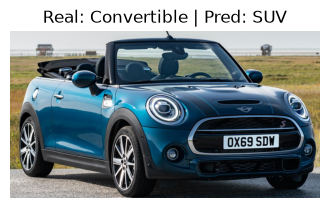

[Convertible] d816921f-66b6-11eb-90fc-8c164571e025_jpg.rf.bc5d05525dc0325f8795e8f4d1b274a8.jpg → Predicción: SUV


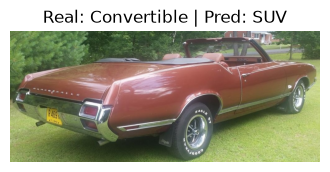

[Convertible] Image_103_jpg.rf.506f1fae6aa1e5418183a774a4829e65.jpg → Predicción: SUV


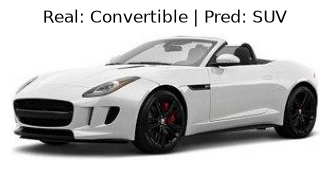

[Coupe] 00046_Audi-TT-RS-Coupe-2012_jpg.rf.b8e0ffd185039a5ed63a2a7dff9fb247.jpg → Predicción: SUV


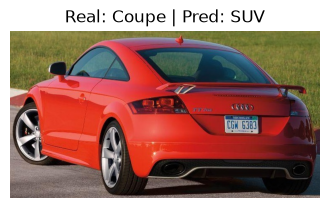

[Coupe] 00340_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.21a5e769ca9ae48ca267f7957082c9db.jpg → Predicción: SUV


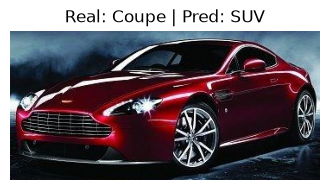

[Coupe] 00679_Ferrari-FF-Coupe-2012_jpg.rf.11ea3546edcc6ca0f5f0ad32d37dc50d.jpg → Predicción: SUV


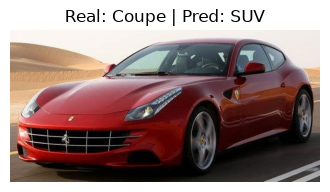

[Coupe] 00787_Infiniti-G-Coupe-IPL-2012_jpg.rf.e79fd1a3e1b7c52451090412ae574615.jpg → Predicción: SUV


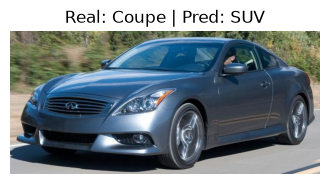

[Coupe] 01210_Audi-TTS-Coupe-2012_jpg.rf.2962286b0a5ccbe5970ff270f05cda3d.jpg → Predicción: SUV


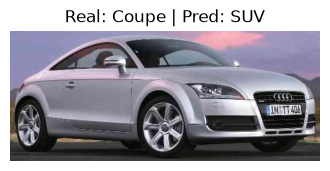

[Coupe] 01239_BMW-1-Series-Coupe-2012_jpg.rf.4a1f2b65c8503eaa40ae7881cb53df30.jpg → Predicción: SUV


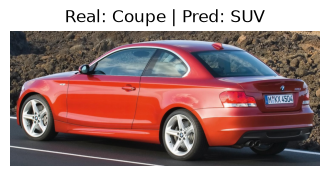

[Coupe] 01950_Mercedes-Benz-SL-Class-Coupe-2009_jpg.rf.fdf8866e6f1727688040443cab3cc102.jpg → Predicción: SUV


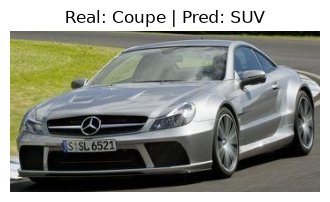

[Coupe] 02899_Audi-A5-Coupe-2012_jpg.rf.2b195e5290b2233f4544f13bc2581ac1.jpg → Predicción: SUV


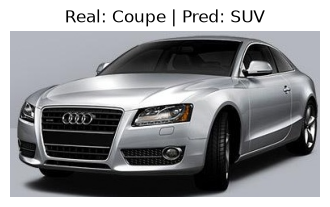

[Coupe] 03175_Bentley-Continental-GT-Coupe-2007_jpg.rf.f33e1f650856eaa3d2c84f03d4b50d72.jpg → Predicción: SUV


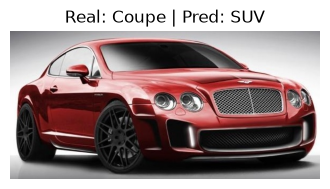

[Coupe] 03226_Audi-S5-Coupe-2012_jpg.rf.408ad8a6cf50fb9610fbde03b0b20ae4.jpg → Predicción: SUV


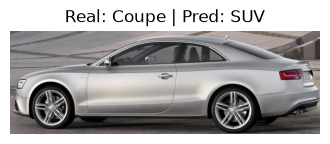

[Coupe] 03413_Bentley-Continental-GT-Coupe-2012_jpg.rf.58841583e789d00e8dbffe4c485dab13.jpg → Predicción: SUV


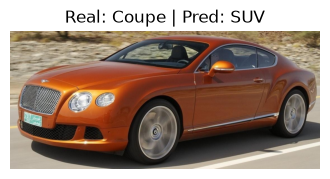

[Coupe] 04166_Aston-Martin-Virage-Coupe-2012_jpg.rf.ac0b8920650e33a26844523ec367859a.jpg → Predicción: SUV


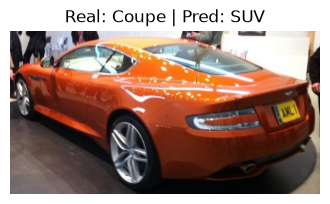

[Coupe] 04428_Audi-TTS-Coupe-2012_jpg.rf.0a3e062d1af241735eae80042466c20b.jpg → Predicción: SUV


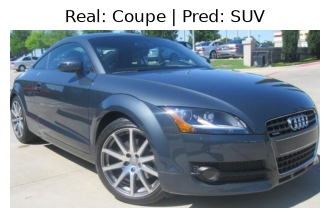

[Coupe] 04510_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.9b6422eac00afa2c67b43a6345a6feef.jpg → Predicción: SUV


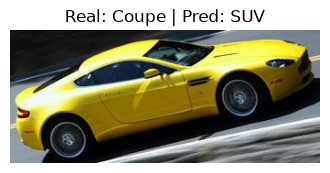

[Coupe] 04595_Audi-TTS-Coupe-2012_jpg.rf.01a2299034480a2f480e98989176f912.jpg → Predicción: SUV


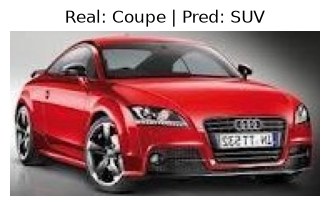

[Coupe] 04750_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.4fb389a5fdb3c56926351d3647f77080.jpg → Predicción: SUV


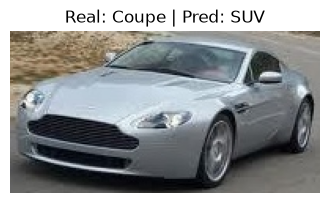

[Coupe] 04753_Audi-TTS-Coupe-2012_jpg.rf.377d982a44ae75f3fab25fb65a3af27d.jpg → Predicción: SUV


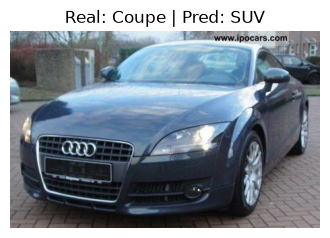

[Coupe] 05306_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.60c48d3f4a6388682f984c0d46f6b562.jpg → Predicción: SUV


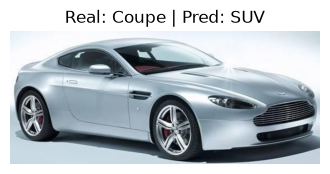

[Coupe] 06450_Audi-A5-Coupe-2012_jpg.rf.451a26aa9fcb7fde503a238bb5ff3d95.jpg → Predicción: SUV


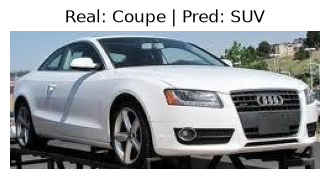

[Coupe] 06493_Honda-Accord-Coupe-2012_jpg.rf.7c2a8129792848cd89245a4e62fd4555.jpg → Predicción: SUV


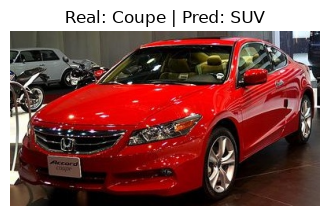

[Coupe] 06509_Audi-S5-Coupe-2012_jpg.rf.d75719d00f427e66e17ef9137126a8fb.jpg → Predicción: SUV


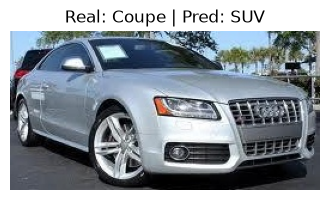

[Coupe] 06778_Audi-S5-Coupe-2012_jpg.rf.6bcb8989f303021cb2e146e432adeaa1.jpg → Predicción: SUV


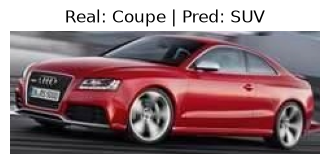

[Coupe] 06845_Audi-TTS-Coupe-2012_jpg.rf.b4ea1b949a092477d7f9d07bfe6c591c.jpg → Predicción: SUV


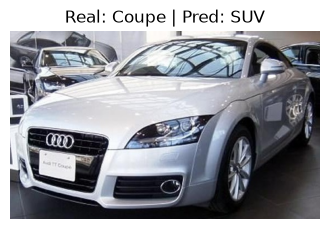

[Coupe] 06915_Bentley-Continental-GT-Coupe-2012_jpg.rf.fe9ced11c19214e921cd19569e910a52.jpg → Predicción: SUV


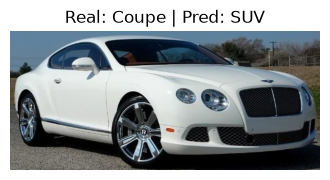

[Coupe] 07155_BMW-1-Series-Coupe-2012_jpg.rf.22b54a8b3945c371b3e13ee1bd16989f.jpg → Predicción: SUV


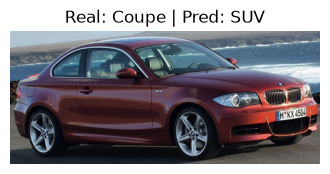

[Coupe] 07572_Audi-A5-Coupe-2012_jpg.rf.8f1c2526c3879f020be6f7a422091b83.jpg → Predicción: SUV


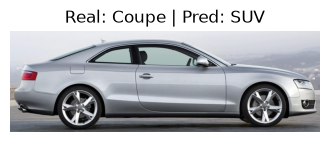

[Coupe] 07598_Bentley-Continental-GT-Coupe-2007_jpg.rf.59519b08ea50b66ce03e9fce6eda1c57.jpg → Predicción: SUV


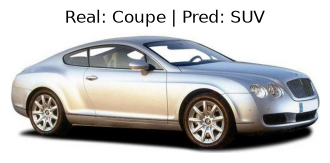

[Coupe] 07952_Honda-Accord-Coupe-2012_jpg.rf.9ed33a32cf1ca217c0c940877aacb120.jpg → Predicción: SUV


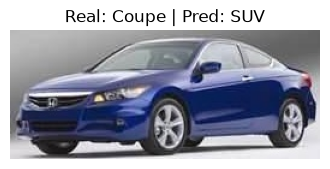

[Coupe] 07976_Audi-A5-Coupe-2012_jpg.rf.dfb4a212dbc036ccd293325cdd7c7d49.jpg → Predicción: SUV


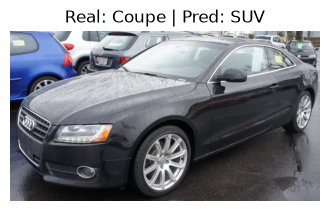

[Coupe] 0ab48d64-66b3-11eb-9141-8c164571e025_jpg.rf.8a42cb30b3b4a2f7b9e13fc793780f46.jpg → Predicción: SUV


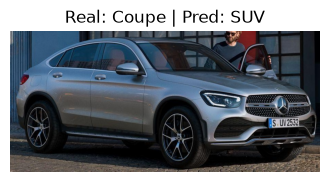

[Coupe] 0ab48d7b-66b3-11eb-b1ee-8c164571e025_jpg.rf.5e032c416d48944b9de54c19803c0b72.jpg → Predicción: SUV


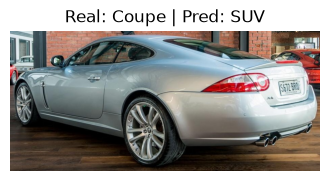

[Coupe] 0ab528d0-66b3-11eb-acea-8c164571e025_jpg.rf.2caac93858ebc6f8e605f4bb751f0b67.jpg → Predicción: SUV


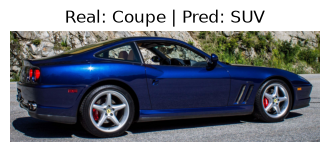

[Coupe] 0ab5c4f1-66b3-11eb-9307-8c164571e025_jpg.rf.e6eb0b5561d19cd57db65918555ec78b.jpg → Predicción: SUV


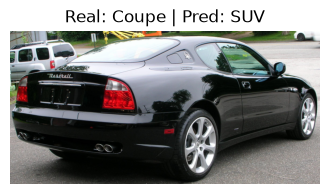

[Coupe] 108_jpg.rf.d0682a51eed6ca7520d937a73e95c1b5.jpg → Predicción: SUV


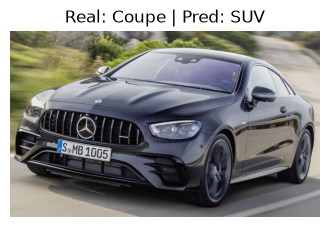

[Coupe] 10_jpg.rf.b3d662fe2d895e9cc20424b8f884a004.jpg → Predicción: SUV


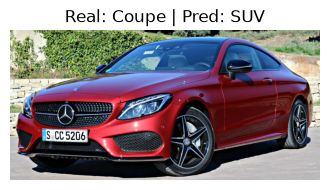

[Coupe] 114_jpg.rf.7fdc73ef1f60eab6ab983a08dcbbaaa8.jpg → Predicción: SUV


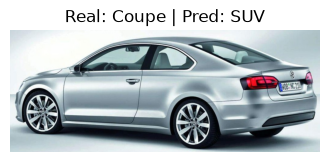

[Coupe] 122_jpg.rf.ff0337ff441cd4f238b6b581cfc58375.jpg → Predicción: SUV


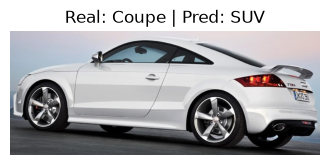

[Coupe] 130_jpg.rf.398203326b12bad82dc22886c7720917.jpg → Predicción: SUV


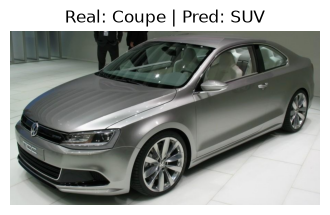

[Coupe] 131_jpg.rf.3e9030e6edd995e58ffe028f02aef995.jpg → Predicción: SUV


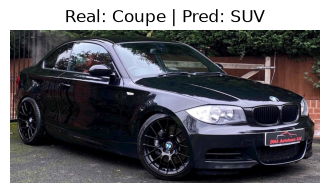

[Coupe] 13_jpg.rf.bced0c152631a3f19f0a2cb6c32815ea.jpg → Predicción: SUV


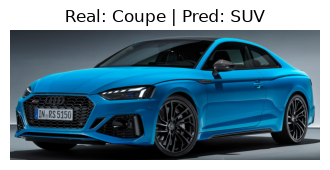

[Coupe] 148_jpg.rf.40cfaa3d6406e02d35a0f8aa54d1ff43.jpg → Predicción: SUV


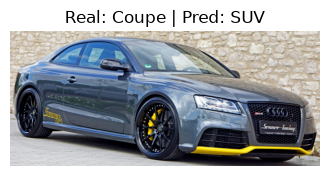

[Coupe] 161_jpg.rf.38a83a1b9c0d1544d31ffeb16c1b11c6.jpg → Predicción: SUV


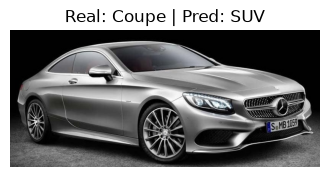

[Coupe] 163_jpg.rf.886eebe0e7291946d2ed0f7f7217e3b5.jpg → Predicción: SUV


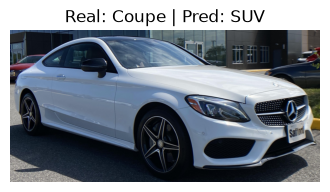

[Coupe] 16_jpg.rf.7f9259ad9348bba56a157c31da25d8a6.jpg → Predicción: SUV


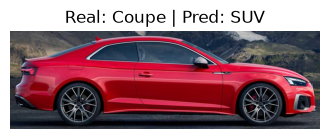

[Coupe] 171_jpg.rf.955b6ff796a4faa7a67a354d83704d52.jpg → Predicción: SUV


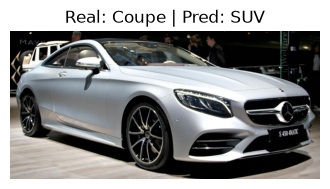

[Coupe] 172_jpg.rf.5fc9efa199832ace58289a42a4041876.jpg → Predicción: SUV


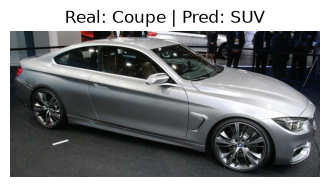

[Coupe] 173_jpg.rf.3f6d26bc2b3a933abfd57a0833704218.jpg → Predicción: SUV


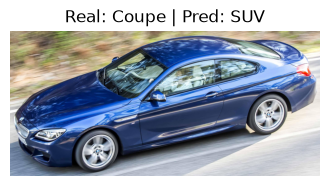

[Coupe] 177_jpg.rf.83ce31bd8f2de4f6df4e127ce5184fbd.jpg → Predicción: SUV


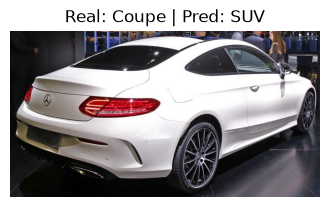

[Coupe] 211_jpg.rf.f832393accd6b477fb7ca1adba13a2cb.jpg → Predicción: SUV


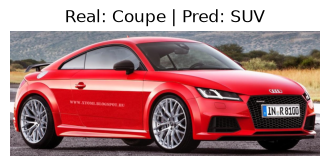

[Coupe] 218_jpg.rf.7abad589ec6b94389a02412526a6bc7a.jpg → Predicción: SUV


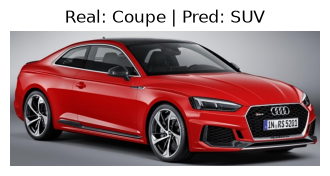

[Coupe] 239_jpg.rf.56dd2fbcf1e7b92548c9b3a06322be8f.jpg → Predicción: SUV


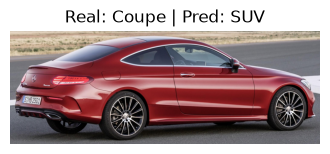

[Coupe] 244_jpg.rf.b7c18497d04263948babc6831a2654f8.jpg → Predicción: SUV


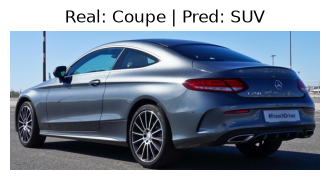

[Coupe] 248_jpg.rf.d6e38454e3460de246ccbfdbe8b818ec.jpg → Predicción: SUV


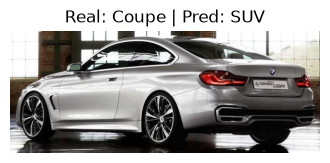

[Coupe] 24_jpg.rf.66a735b36957102bc94473aab314cc8e.jpg → Predicción: SUV


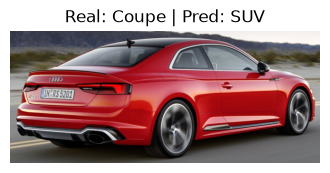

[Coupe] 24_jpg.rf.e4cdcd2bc3bc9eb81236ed30670db34a.jpg → Predicción: SUV


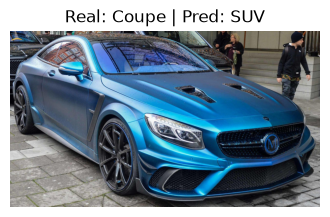

[Coupe] 262_jpg.rf.440940d07222a53069faef89a8d77730.jpg → Predicción: SUV


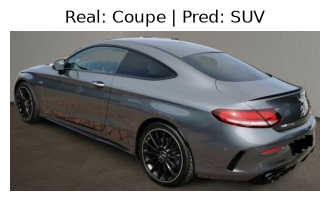

[Coupe] 266_jpg.rf.1be91f70dd478137aa068e06d522a8ed.jpg → Predicción: SUV


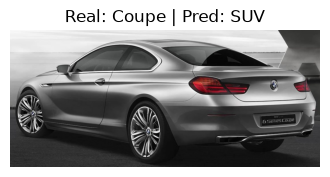

[Coupe] 266_jpg.rf.cceee4f98a08541d1d74d9661faef7b8.jpg → Predicción: SUV


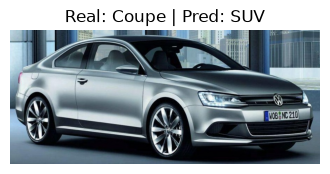

[Coupe] 286_jpg.rf.33c327ed7791e0a93d044b2eca942dc6.jpg → Predicción: SUV


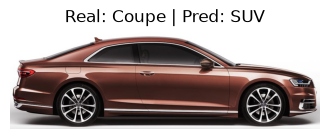

[Coupe] 30_jpg.rf.84d4c1df2cb547b7520a0c169bd74e9d.jpg → Predicción: SUV


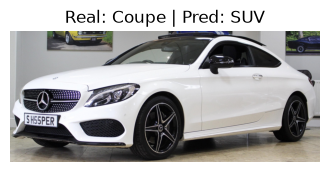

[Coupe] 313_jpg.rf.4d822638a4cf329273d6d1f53e9a649a.jpg → Predicción: SUV


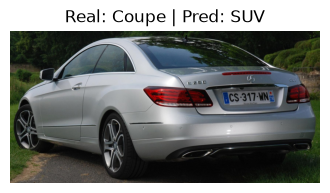

[Coupe] 354_jpg.rf.dc264edc6233f92d3909083cdf56dc91.jpg → Predicción: SUV


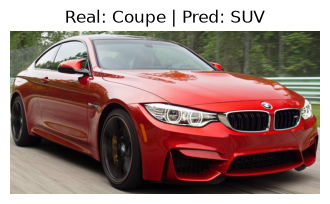

[Coupe] 356_jpg.rf.ee6c9089c6c63232b9e99807340b7acb.jpg → Predicción: SUV


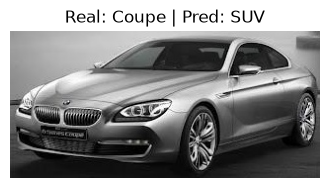

[Coupe] 377_jpg.rf.5bb847ad603920a1b1a457dcb1e912cf.jpg → Predicción: SUV


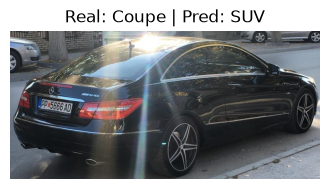

[Coupe] 392_jpg.rf.035f50121f19648528ca67b4cb79afa1.jpg → Predicción: SUV


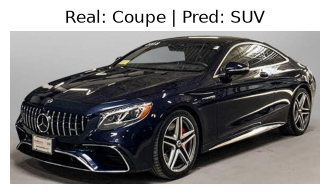

[Coupe] 39_jpg.rf.9cb392d0b5ef3b4668327fdfc7382931.jpg → Predicción: SUV


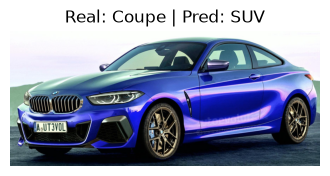

[Coupe] 3_jpg.rf.a85565a82b3c66899bcd417845be7c71.jpg → Predicción: SUV


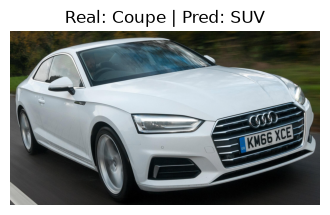

[Coupe] 463_jpg.rf.110eb785646de3a066447ef79da678ef.jpg → Predicción: SUV


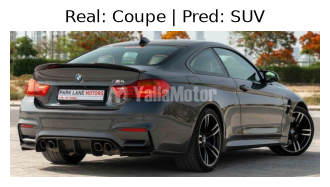

[Coupe] 520_jpg.rf.0f155f1ee67e8302fbe84eb10094a022.jpg → Predicción: SUV


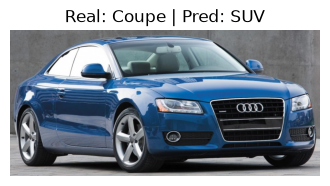

[Coupe] 55_jpg.rf.6bc3ef57ab5fe3e6ca75f1802b1d1dda.jpg → Predicción: SUV


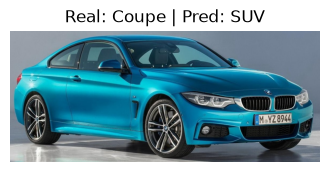

[Coupe] 60_jpg.rf.eb6d3eedf350ea492b5339ff4148e5d3.jpg → Predicción: SUV


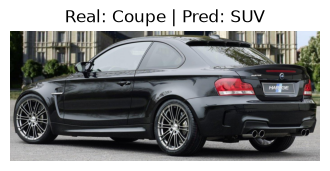

[Coupe] 77_jpg.rf.aee00019f0daef9fc545e1eae5bd81fa.jpg → Predicción: SUV


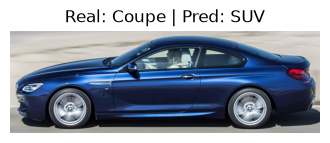

[Coupe] 7_jpg.rf.a5bbd690c24ef265f8c9328ee99655be.jpg → Predicción: SUV


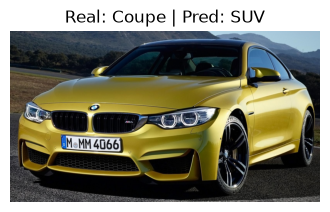

[Coupe] 80_jpg.rf.417fa09c95f9c12d09fee4cb6db4246c.jpg → Predicción: SUV


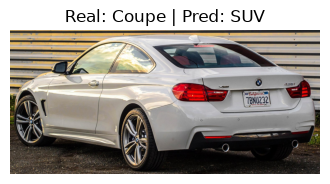

[Coupe] 80_jpg.rf.97f51660051c3398aafeb3d7e327da84.jpg → Predicción: SUV


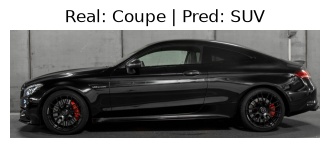

[Coupe] 82_jpg.rf.9bdb418bffcd945c6c43ad408ca5dc00.jpg → Predicción: SUV


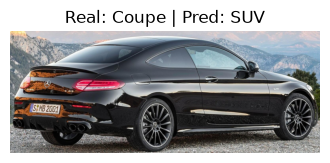

[Coupe] 8_jpg.rf.63f356ce8e54ec3ca4bc1763eb33eddc.jpg → Predicción: SUV


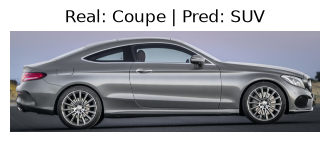

[Coupe] 95_jpg.rf.da919fc291c40525dfc431bdb5e41ac7.jpg → Predicción: SUV


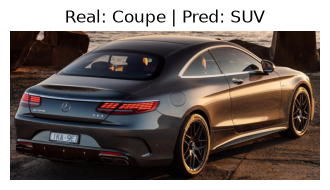

[Coupe] 9_jpg.rf.c8731f123ab11fa09661844f7648e149.jpg → Predicción: SUV


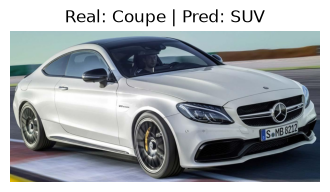

[Hatchback] 00042_Volkswagen-Golf-Hatchback-1991_jpg.rf.a9ca5d436eefa71d5842b1e825621cf7.jpg → Predicción: SUV


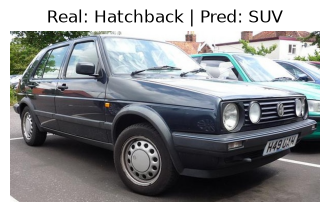

[Hatchback] 00199_Volkswagen-Golf-Hatchback-1991_jpg.rf.aa9abda4df4ba2878e4239d3151d6323.jpg → Predicción: SUV


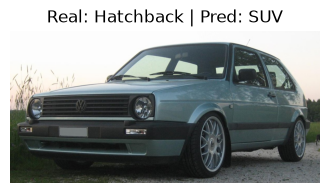

[Hatchback] 00442_Volkswagen-Golf-Hatchback-2012_jpg.rf.3875274cd997830c6fdf7d689419e48b.jpg → Predicción: SUV


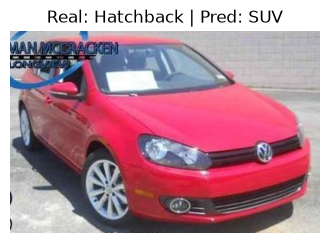

[Hatchback] 00992_Nissan-Leaf-Hatchback-2012_jpg.rf.df0af170eb76ea644c2237e1293c8636.jpg → Predicción: SUV


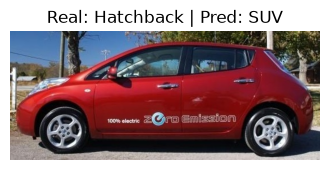

[Hatchback] 01080_Volkswagen-Beetle-Hatchback-2012_jpg.rf.64beb3905a0631859d6a9fdedc5f4ce5.jpg → Predicción: SUV


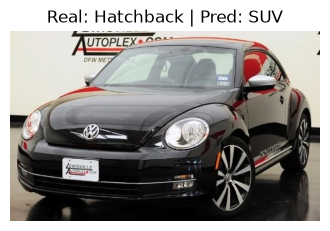

[Hatchback] 01587_Nissan-Juke-Hatchback-2012_jpg.rf.b98d6a1bf323df5a0313fc25e484bb5b.jpg → Predicción: SUV


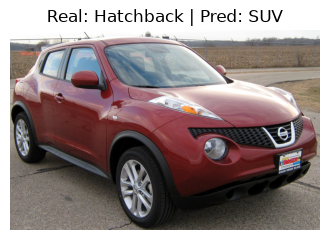

[Hatchback] 02061_Suzuki-SX4-Hatchback-2012_jpg.rf.30e0850d3624216deebf3ade74b0cb05.jpg → Predicción: SUV


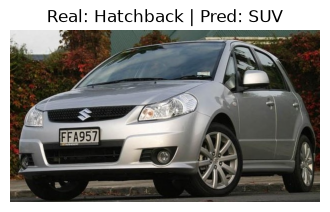

[Hatchback] 02629_Volkswagen-Beetle-Hatchback-2012_jpg.rf.d6b8808f397bb000e2348fb3dc25ad15.jpg → Predicción: SUV


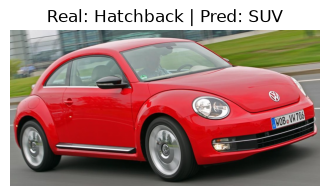

[Hatchback] 02814_Nissan-Leaf-Hatchback-2012_jpg.rf.3b14996c70c6aaecda58b7da3800d932.jpg → Predicción: SUV


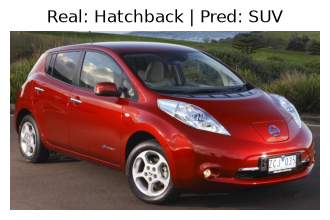

[Hatchback] 03300_Volkswagen-Golf-Hatchback-1991_jpg.rf.990a80b0bf0ca54cc125f8d6a6c2f59e.jpg → Predicción: SUV


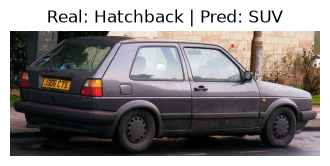

[Hatchback] 03582_Nissan-Leaf-Hatchback-2012_jpg.rf.9169cdc0ae532f91b9a3ece2b1d3846a.jpg → Predicción: SUV


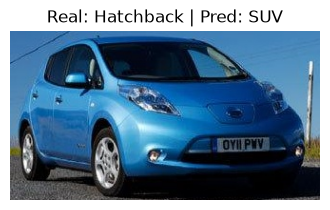

[Hatchback] 03642_Nissan-Juke-Hatchback-2012_jpg.rf.b3bce2dc909301f4d02bbe20155fe812.jpg → Predicción: SUV


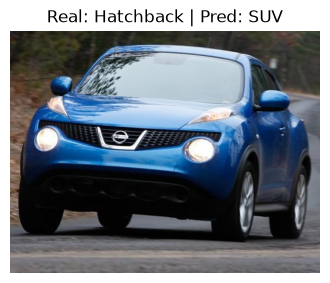

[Hatchback] 03922_Volkswagen-Golf-Hatchback-2012_jpg.rf.2e9ee3a8c1872cf6c360de7f7fa05cb9.jpg → Predicción: SUV


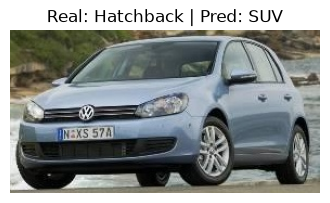

[Hatchback] 04004_Volkswagen-Golf-Hatchback-2012_jpg.rf.9c6c1c7ae0e4430a3b08657082f6c264.jpg → Predicción: SUV


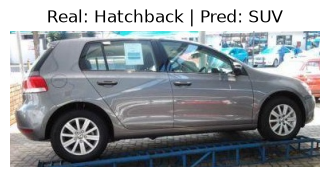

[Hatchback] 04599_Hyundai-Veloster-Hatchback-2012_jpg.rf.aa3004d36bfb03fef9a98781461ca1f1.jpg → Predicción: SUV


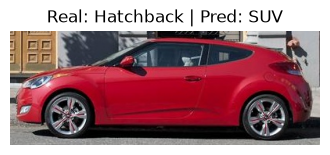

[Hatchback] 04663_Nissan-Juke-Hatchback-2012_jpg.rf.cfeee40cc7b27614e5272bbfda98f2a7.jpg → Predicción: SUV


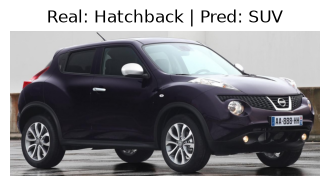

[Hatchback] 05037_Hyundai-Veloster-Hatchback-2012_jpg.rf.0879a1dabdfd459970ce5c8fb6af1c45.jpg → Predicción: SUV


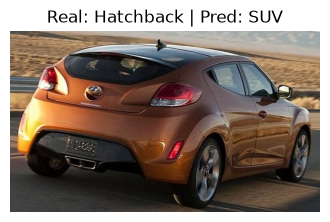

[Hatchback] 05234_Suzuki-SX4-Hatchback-2012_jpg.rf.3e82e9364278ad2a7aded40a5c5fb11f.jpg → Predicción: SUV


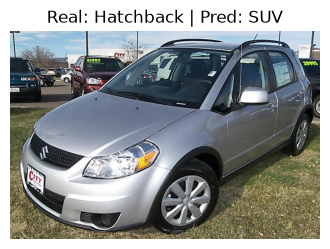

[Hatchback] 05414_Nissan-Leaf-Hatchback-2012_jpg.rf.333923e5b74451c34502e5481e503e4f.jpg → Predicción: SUV


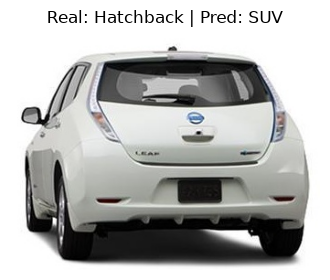

[Hatchback] 05766_Volkswagen-Golf-Hatchback-2012_jpg.rf.b70695e4a85fbcbceacc3abbf84b6e27.jpg → Predicción: SUV


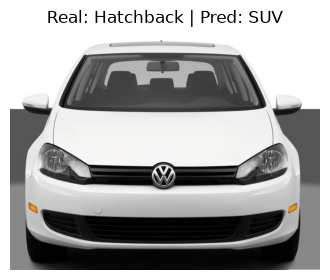

[Hatchback] 05849_Nissan-Juke-Hatchback-2012_jpg.rf.6a3a9a1f8d27f796714f4127d1a7a1c5.jpg → Predicción: SUV


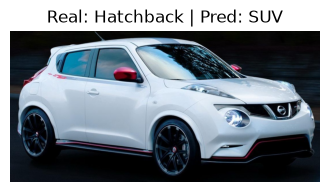

[Hatchback] 05931_Volkswagen-Golf-Hatchback-2012_jpg.rf.57d07b1fcfa4e3a1438a66daef16c5d3.jpg → Predicción: SUV


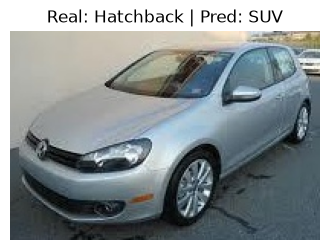

[Hatchback] 05939_Nissan-Juke-Hatchback-2012_jpg.rf.161fa5292b7c91bd3e90ca466672e382.jpg → Predicción: SUV


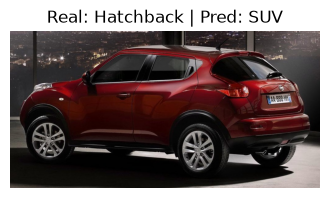

[Hatchback] 05941_Volkswagen-Golf-Hatchback-2012_jpg.rf.c2354c1785c175f863f908f5ae2adbe6.jpg → Predicción: SUV


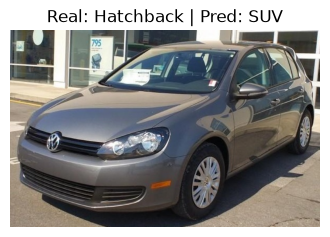

[Hatchback] 06059_Hyundai-Veloster-Hatchback-2012_jpg.rf.8dcf180365246abefa154445483c587e.jpg → Predicción: SUV


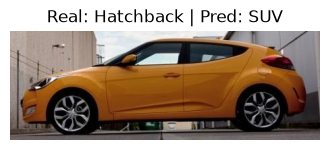

[Hatchback] 06092_Nissan-Leaf-Hatchback-2012_jpg.rf.180a47ac990b921b0e1c5934dcad73a9.jpg → Predicción: SUV


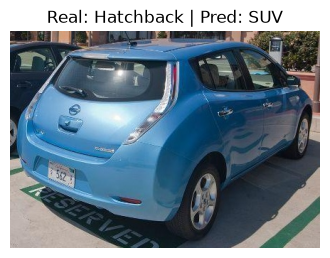

[Hatchback] 06393_Nissan-Juke-Hatchback-2012_jpg.rf.74175eead6fb7bf11421ce7815bb9a1a.jpg → Predicción: SUV


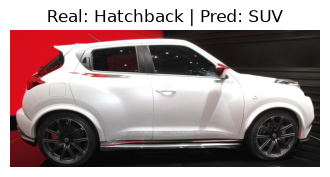

[Hatchback] 06483_Hyundai-Elantra-Touring-Hatchback-2012_jpg.rf.89bd15e949d721b0113b49dc9e4e57b8.jpg → Predicción: SUV


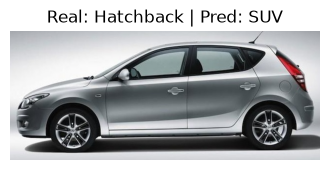

[Hatchback] 07788_Volkswagen-Beetle-Hatchback-2012_jpg.rf.b8169600cff1fadf8546705af7e1eb68.jpg → Predicción: SUV


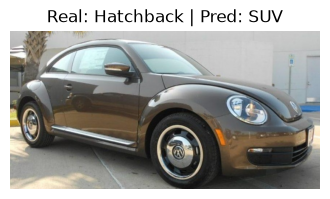

[Hatchback] 113_jpg.rf.5a83a9023ce38c86bdc3df8f9f1bf22c.jpg → Predicción: SUV


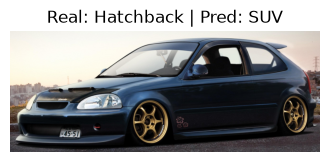

[Hatchback] 117_jpg.rf.711a9419cc6117abadbb3d6ca0a90766.jpg → Predicción: SUV


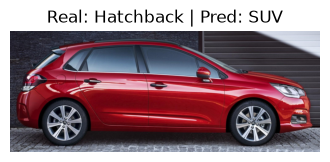

[Hatchback] 128_jpg.rf.f1a4f46969cc150dec414911b8d8d83b.jpg → Predicción: SUV


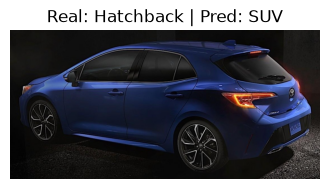

[Hatchback] 13_jpg.rf.af4b136c5e16ad9b57666f501e55bd06.jpg → Predicción: SUV


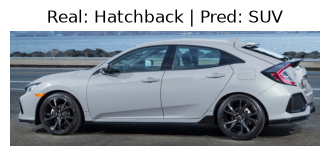

[Hatchback] 166_jpg.rf.c657e991ae89d385e702e38275289920.jpg → Predicción: SUV


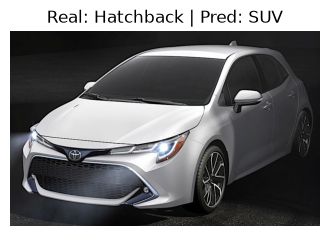

[Hatchback] 172_jpg.rf.c4edebe7300cbe7b5a0a26870be52d69.jpg → Predicción: SUV


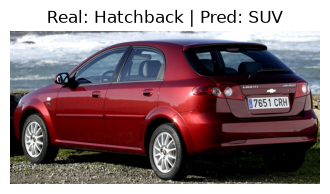

[Hatchback] 188_jpg.rf.4689039d5795586f022f288b85817a91.jpg → Predicción: SUV


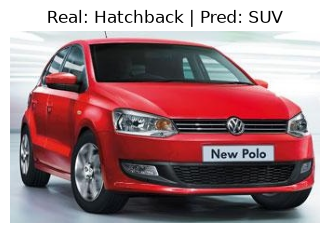

[Hatchback] 220_jpg.rf.9c6e5a64b2fbf658d81e235bac51c884.jpg → Predicción: SUV


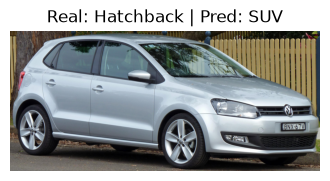

[Hatchback] 235_jpg.rf.8de3dff9822a573f5b580d2b5196dcb4.jpg → Predicción: SUV


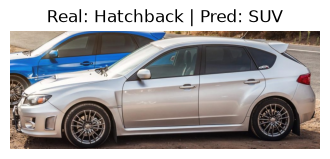

[Hatchback] 249_jpg.rf.5779744c66fb8e1ac44c6a706b0d11bf.jpg → Predicción: SUV


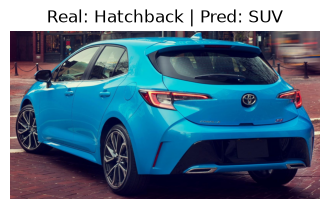

[Hatchback] 330_jpg.rf.49835e1ca8627b43a8017b4b2b548af2.jpg → Predicción: SUV


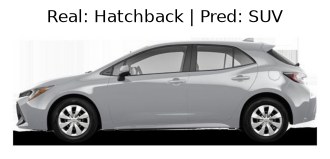

[Hatchback] 38_jpg.rf.4531936705b475be5bf2719377f792f7.jpg → Predicción: SUV


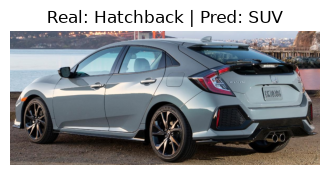

[Hatchback] 419_jpg.rf.263fba7263c4c0f6f3d55089c2220a72.jpg → Predicción: SUV


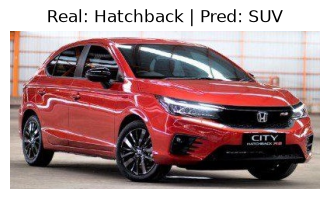

[Hatchback] 44_jpg.rf.c7d897cccfa9b0110eb835fd7355e65d.jpg → Predicción: SUV


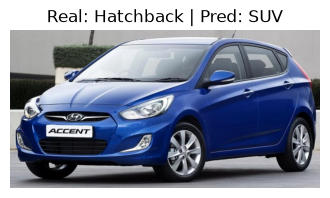

[Hatchback] 538_jpg.rf.6df0b0392afd3df23fc5928e20bdb92c.jpg → Predicción: SUV


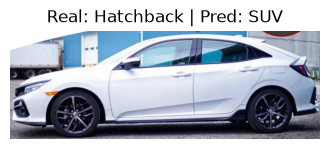

[Hatchback] 57_jpg.rf.b5034c07bdcfd67f64e96fc26d44b47b.jpg → Predicción: SUV


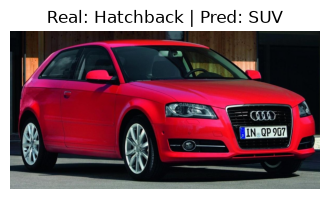

[Hatchback] 63_jpg.rf.888ded44d4de0c34ea95ee74ff094c97.jpg → Predicción: SUV


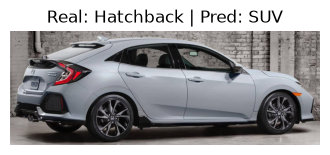

[Hatchback] 8_jpg.rf.c314c1d6777942876503fa1482c82240.jpg → Predicción: SUV


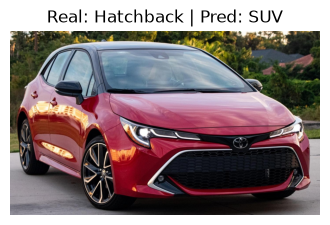

[Hatchback] d581b423-66ac-11eb-b517-8c164571e025_jpg.rf.1680a106fe52e6ab38b8eef86bcb1f91.jpg → Predicción: SUV


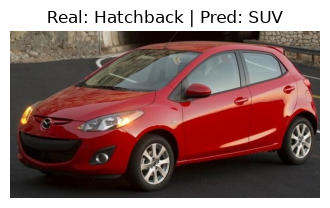

[Hatchback] d581b428-66ac-11eb-a20b-8c164571e025_jpg.rf.514cf7a98b71b84791a18bdfa353bb24.jpg → Predicción: SUV


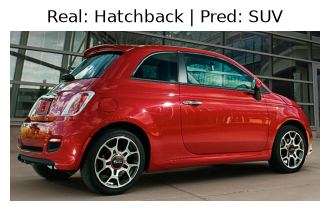

[Hatchback] d581b463-66ac-11eb-ae88-8c164571e025_jpg.rf.1fc9880685fd91f097abd3fe5c21cae0.jpg → Predicción: SUV


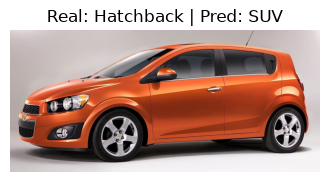

[Hatchback] d581b46b-66ac-11eb-90d3-8c164571e025_jpg.rf.a2734781da45dae15cc5acd5da3b9846.jpg → Predicción: SUV


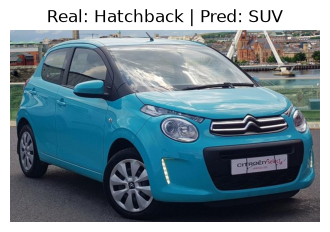

[Hatchback] d581b473-66ac-11eb-bb25-8c164571e025_jpg.rf.6cba7aece68d508854a9e09a88f236b8.jpg → Predicción: SUV


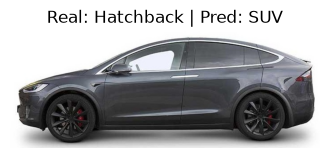

[Hatchback] d5824f2b-66ac-11eb-88a5-8c164571e025_jpg.rf.cbbcee01d0d0dc779674a727805c6eaa.jpg → Predicción: SUV


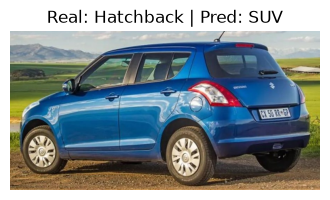

[Hatchback] d5824f38-66ac-11eb-a5e7-8c164571e025_jpg.rf.83730f316f0e3c1cbe022b6269701947.jpg → Predicción: SUV


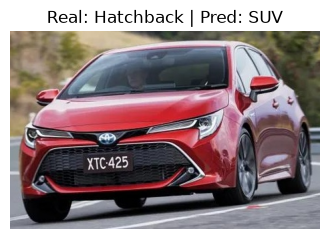

[Hatchback] d5824f4e-66ac-11eb-a9ce-8c164571e025_jpg.rf.93faba217857c0f069859df3740fd14a.jpg → Predicción: SUV


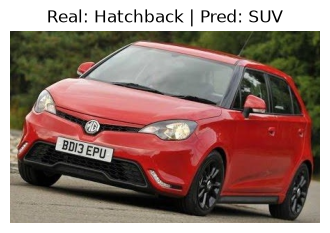

[Hatchback] d5824f75-66ac-11eb-9bb6-8c164571e025_jpg.rf.dca5310387c3f0329770eaa09ca48601.jpg → Predicción: SUV


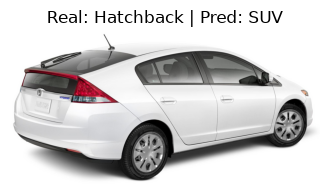

[Hatchback] d5824f77-66ac-11eb-9dcb-8c164571e025_jpg.rf.5eef9c5a5cd8ec2370da3685056db833.jpg → Predicción: SUV


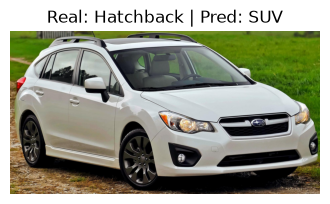

[Hatchback] d5824f90-66ac-11eb-818a-8c164571e025_jpg.rf.98b56f3dfc94f96462c142787d5c3ddd.jpg → Predicción: SUV


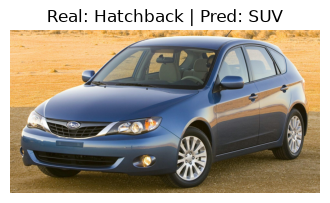

[Hatchback] d582eca8-66ac-11eb-a0f5-8c164571e025_jpg.rf.4356bab6ac306cabec10797ed1594480.jpg → Predicción: SUV


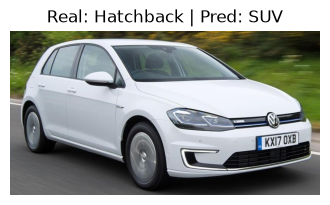

[Hatchback] d582ecd3-66ac-11eb-82dc-8c164571e025_jpg.rf.efa7b32d34fe12d2705051b9ee3150b3.jpg → Predicción: SUV


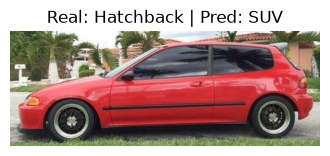

[Hatchback] d582ed00-66ac-11eb-af52-8c164571e025_jpg.rf.9ca7b3f424df1cfe869eae16e3b4ff27.jpg → Predicción: SUV


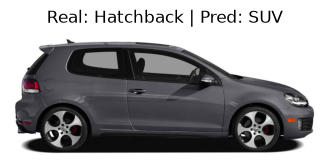

[Hatchback] d582ed0c-66ac-11eb-bb9d-8c164571e025_jpg.rf.2a8d2c7011904b89bcd2388ce75c552d.jpg → Predicción: SUV


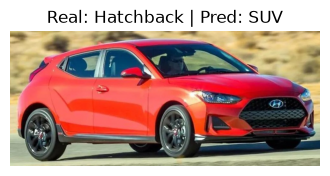

[Hatchback] d583896f-66ac-11eb-8f53-8c164571e025_jpg.rf.b573d1a78ffab3cb0afaf75ef132d449.jpg → Predicción: SUV


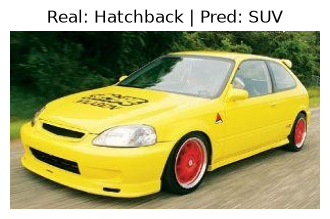

[Hatchback] d583898f-66ac-11eb-aa03-8c164571e025_jpg.rf.5af94cad5916775beb56e8ebad35a81a.jpg → Predicción: SUV


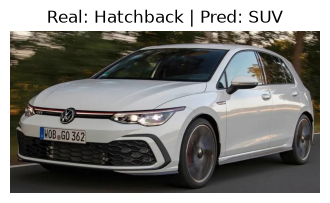

[Hatchback] d58389a7-66ac-11eb-bbdd-8c164571e025_jpg.rf.fa061ad97d47f4fbd7f59f612a98244c.jpg → Predicción: SUV


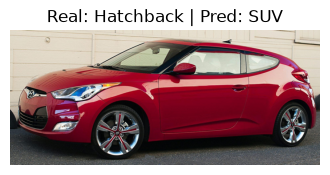

[Hatchback] d5842409-66ac-11eb-a12c-8c164571e025_jpg.rf.2f8c830e94d752e8d920ffc2dbcbe1a1.jpg → Predicción: SUV


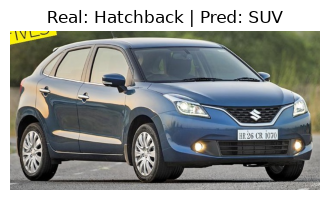

[Hatchback] d584243d-66ac-11eb-bd48-8c164571e025_jpg.rf.34cf4176f281337a005a2d2983c779e9.jpg → Predicción: SUV


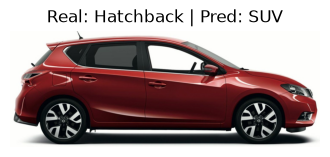

[Hatchback] d5842441-66ac-11eb-af73-8c164571e025_jpg.rf.d00cea3d9d2121ae59ffc50f7bf98def.jpg → Predicción: SUV


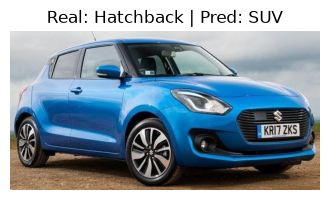

[Hatchback] d584244b-66ac-11eb-8ce2-8c164571e025_jpg.rf.1e0c9db43bdaf67d88a8ae647d840422.jpg → Predicción: SUV


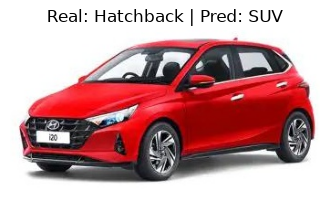

[Hatchback] d5842464-66ac-11eb-b974-8c164571e025_jpg.rf.ed9afd8702c4d273d72b6e412e97a25c.jpg → Predicción: SUV


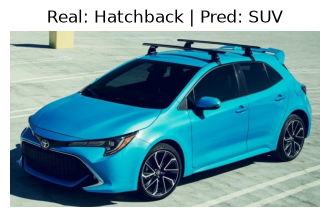

[Hatchback] d584e9be-66ac-11eb-88ce-8c164571e025_jpg.rf.d343ea3178e8f0b68bbe54416a8b05fb.jpg → Predicción: SUV


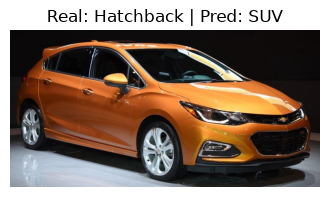

[Hatchback] d584e9d8-66ac-11eb-84e7-8c164571e025_jpg.rf.e2f77e8bc5db825a25f469ae58ee552f.jpg → Predicción: SUV


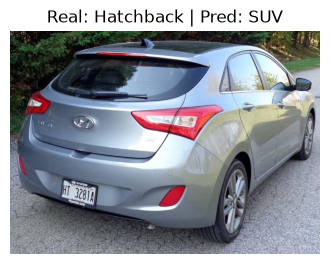

[Hatchback] d584e9fc-66ac-11eb-9223-8c164571e025_jpg.rf.f5423b9e7a42e6993439fd0ee8408903.jpg → Predicción: SUV


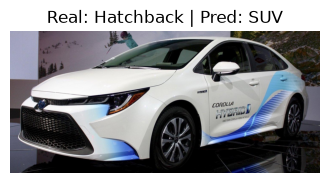

[Hatchback] d584ea0b-66ac-11eb-b956-8c164571e025_jpg.rf.3e0a480b29fb313031c39d496ba52697.jpg → Predicción: SUV


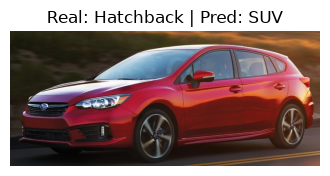

[Hatchback] d584ea22-66ac-11eb-8044-8c164571e025_jpg.rf.47945b11accee4a386875644ee7f26bf.jpg → Predicción: SUV


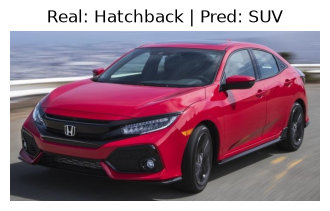

[Hatchback] d585843d-66ac-11eb-9a96-8c164571e025_jpg.rf.52f6feb96c607be2e65a10b12b5b8af3.jpg → Predicción: SUV


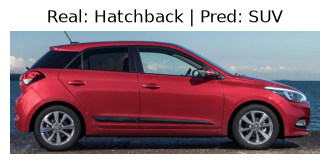

[Hatchback] d5858458-66ac-11eb-9db8-8c164571e025_jpg.rf.af458a9dd02ed156ffdb01c9c6bf7da2.jpg → Predicción: SUV


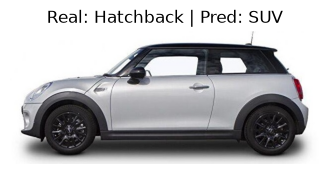

[Hatchback] d585845a-66ac-11eb-8c5d-8c164571e025_jpg.rf.bb4befed3d894acce5a913a63954e2ad.jpg → Predicción: SUV


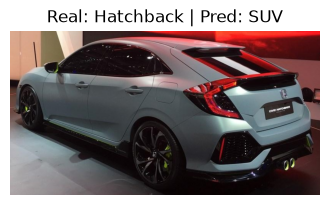

[Hatchback] d58584a2-66ac-11eb-960c-8c164571e025_jpg.rf.d03f0d53c535362539a7e4de0bf3eb5b.jpg → Predicción: SUV


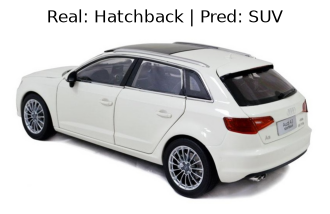

[Hatchback] d58584ac-66ac-11eb-a466-8c164571e025_jpg.rf.12c1b162939e0d79064b4696733171b5.jpg → Predicción: SUV


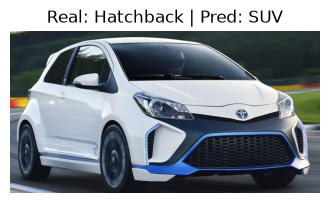

[Hatchback] d5862253-66ac-11eb-b688-8c164571e025_jpg.rf.681e1c01d13c3330dbaad5d484d97bb4.jpg → Predicción: SUV


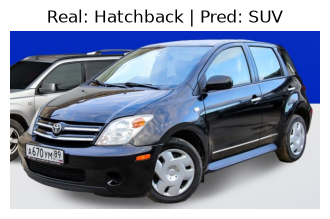

[Hatchback] d586225b-66ac-11eb-ad4a-8c164571e025_jpg.rf.8138952b7cfe72411fe58f45083f36c0.jpg → Predicción: SUV


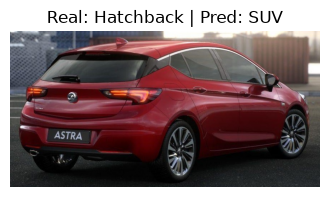

[Hatchback] d586225f-66ac-11eb-b731-8c164571e025_jpg.rf.3f3280bf4df50ce4024d219931f42224.jpg → Predicción: SUV


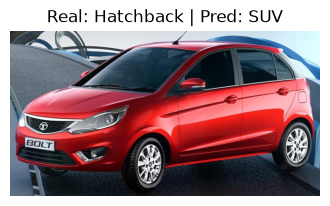

[Hatchback] d5862278-66ac-11eb-80ce-8c164571e025_jpg.rf.321d710f21ca2e267cd6b71b5b314d57.jpg → Predicción: SUV


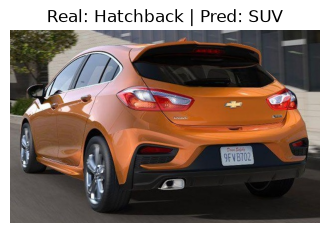

[Hatchback] d586227c-66ac-11eb-b36c-8c164571e025_jpg.rf.66f10d209c8b75a3e61fe0887fdb5087.jpg → Predicción: SUV


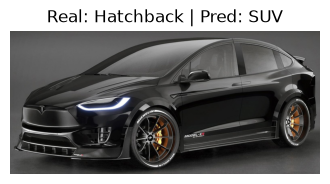

[Hatchback] d58622a5-66ac-11eb-aec9-8c164571e025_jpg.rf.7d46f577f2ce916f003fdd42e28ac0ba.jpg → Predicción: SUV


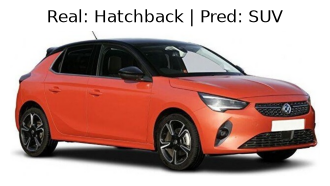

[Hatchback] d58622a9-66ac-11eb-88e3-8c164571e025_jpg.rf.6a032a17a1fd0a144c3e7f39ea7b5c38.jpg → Predicción: SUV


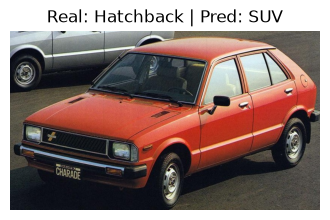

[Hatchback] Image_107_jpg.rf.b5cc44e31bc6124aab20f9d902c5a674.jpg → Predicción: SUV


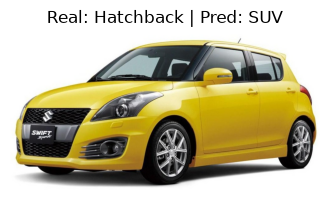

[Hatchback] Image_125_jpg.rf.87cc93f1bd97f1959f51cd86e971dac3.jpg → Predicción: SUV


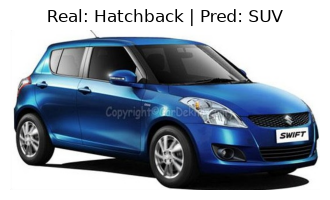

[Hatchback] Image_176_jpg.rf.cec2701b8df6969c6c772ba7332a8269.jpg → Predicción: SUV


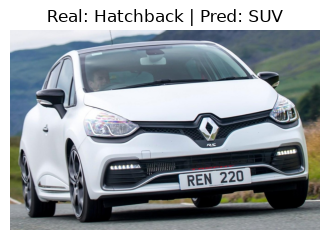

[Hatchback] Image_17_jpg.rf.732fb18815a60667bc883b453aac0ae8.jpg → Predicción: SUV


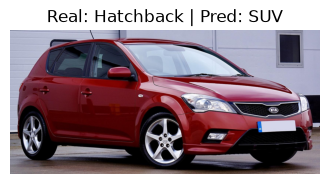

[Hatchback] Image_24_jpg.rf.8f4bd1e8531f105566a93253010ff8a2.jpg → Predicción: SUV


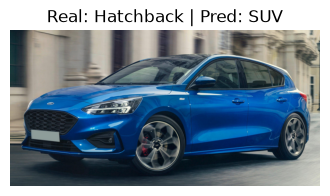

[Hatchback] Image_25_jpg.rf.3b9158298b99865f86f2a44a780f1e14.jpg → Predicción: SUV


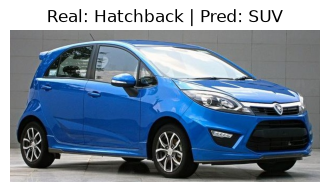

[Hatchback] Image_31_jpg.rf.8c6795212175e9c54d65c145620b9c6f.jpg → Predicción: SUV


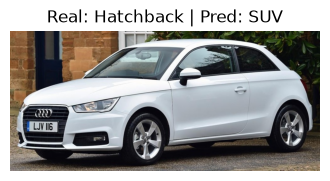

[Hatchback] Image_40_jpg.rf.253ed1d1e835d79451d05b6b9a390627.jpg → Predicción: SUV


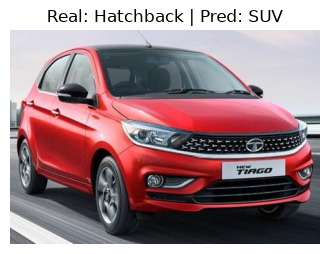

[Hatchback] Image_50_jpg.rf.8bc68692965dd888646da0c4772ee983.jpg → Predicción: SUV


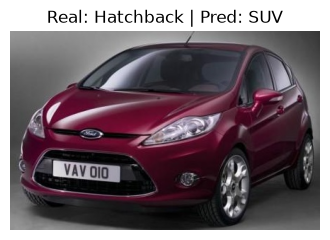

[Hatchback] Image_51_jpg.rf.b19e9ee22f3a0aa9de5b931bef875433.jpg → Predicción: SUV


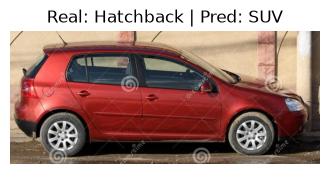

[Hatchback] Image_55_jpg.rf.5bcfc691696c1511f772a01c9944dd13.jpg → Predicción: SUV


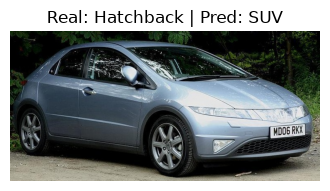

[Hatchback] Image_9_jpg.rf.e913a42863eae52b55afca61f05ac561.jpg → Predicción: SUV


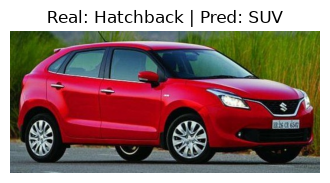

[Pick-Up] 00268_Chevrolet-Silverado-1500-Extended-Cab-2012_jpg.rf.e0cad67539bac187112b9fd6190b9190.jpg → Predicción: SUV


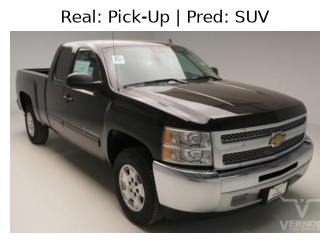

[Pick-Up] 00322_Chevrolet-Silverado-1500-Regular-Cab-2012_jpg.rf.f90e3530367175fad5f0d56bee75a7af.jpg → Predicción: SUV


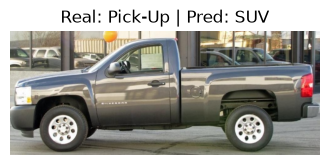

[Pick-Up] 00473_Chevrolet-Avalanche-Crew-Cab-2012_jpg.rf.045dbdccfdb65bc4e9415e08b2b621cf.jpg → Predicción: SUV


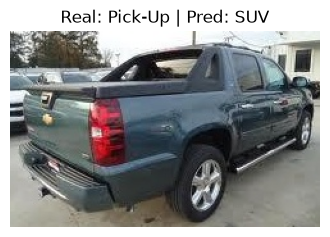

[Pick-Up] 00879_Dodge-Dakota-Club-Cab-2007_jpg.rf.1e648db8e3c7db9b9ca68085c29f9c3a.jpg → Predicción: SUV


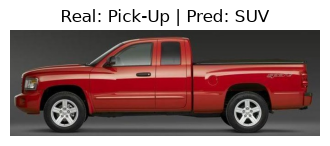

[Pick-Up] 01325_Chevrolet-Silverado-1500-Classic-Extended-Cab-2007_jpg.rf.02070f6f77ad41ce4e13244cce86d972.jpg → Predicción: SUV


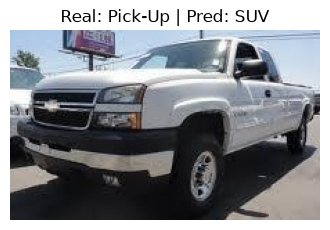

[Pick-Up] 01382_Cadillac-Escalade-EXT-Crew-Cab-2007_jpg.rf.e71d28e56904b5174c7155561b714715.jpg → Predicción: SUV


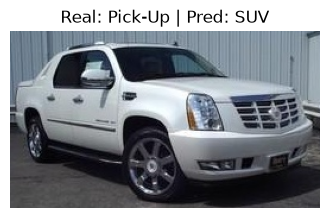

[Pick-Up] 01477_Chevrolet-Silverado-1500-Classic-Extended-Cab-2007_jpg.rf.fae049e28fd83c8e16744be8059934a1.jpg → Predicción: SUV


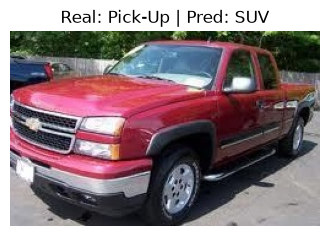

[Pick-Up] 01612_Chevrolet-Silverado-2500HD-Regular-Cab-2012_jpg.rf.86167d71d8387502f76b9a7700599eac.jpg → Predicción: SUV


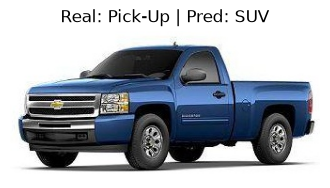

[Pick-Up] 01683_Dodge-Ram-Pickup-3500-Crew-Cab-2010_jpg.rf.a5accb6361694720f2583f8608a38d94.jpg → Predicción: SUV


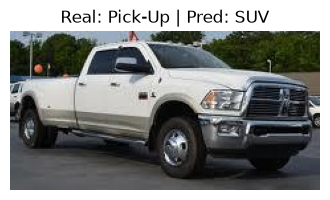

[Pick-Up] 01869_GMC-Canyon-Extended-Cab-2012_jpg.rf.26347d5cc18173eb5aa5273b6ca5863d.jpg → Predicción: SUV


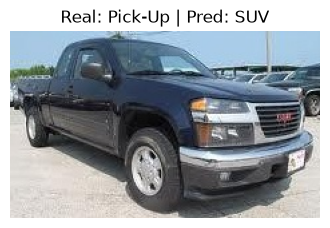

[Pick-Up] 01905_Chevrolet-Silverado-2500HD-Regular-Cab-2012_jpg.rf.e44148c3604b3f3928b9b7ff3995fab8.jpg → Predicción: SUV


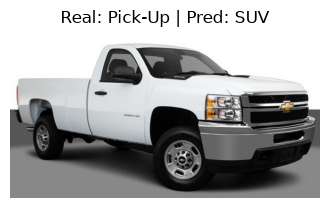

[Pick-Up] 02074_Dodge-Ram-Pickup-3500-Crew-Cab-2010_jpg.rf.eb2730702c07d43b7d3fa9b91ccd949a.jpg → Predicción: SUV


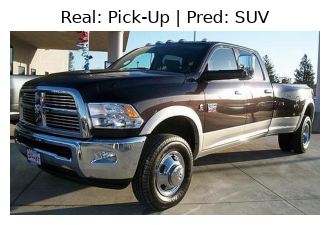

[Pick-Up] 02107_Chevrolet-Avalanche-Crew-Cab-2012_jpg.rf.ad930d146efc1584ae1c97438fdeb211.jpg → Predicción: SUV


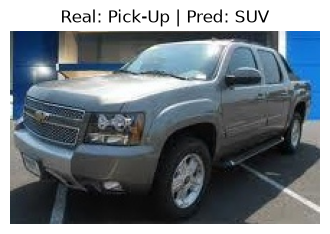

[Pick-Up] 02125_Chevrolet-Silverado-1500-Extended-Cab-2012_jpg.rf.ed0564720da9c7df6ee2565a65cd6f6e.jpg → Predicción: SUV


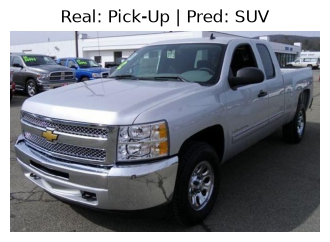

[Pick-Up] 02482_HUMMER-H2-SUT-Crew-Cab-2009_jpg.rf.2216c42a46747444afb9dc52e0729358.jpg → Predicción: SUV


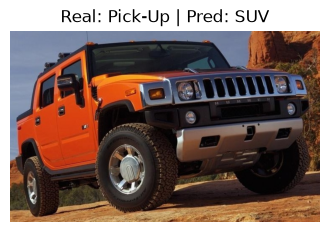

[Pick-Up] 02546_Chevrolet-Silverado-1500-Hybrid-Crew-Cab-2012_jpg.rf.a28b7ae90196abfe5ce4c6da56adcf1e.jpg → Predicción: SUV


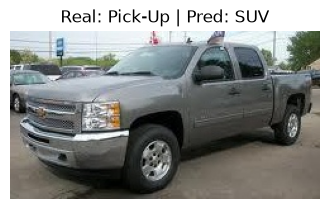

[Pick-Up] 02578_Ford-F-150-Regular-Cab-2007_jpg.rf.6ebfa00a7e265bb36ab530faab23c583.jpg → Predicción: SUV


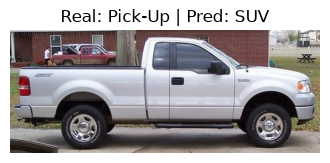

[Pick-Up] 02622_Dodge-Dakota-Crew-Cab-2010_jpg.rf.e71cef442dc126250c3ae4e2e24802e3.jpg → Predicción: SUV


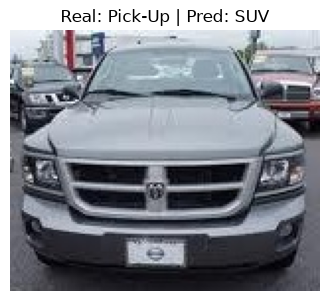

[Pick-Up] 02934_Chevrolet-Silverado-1500-Regular-Cab-2012_jpg.rf.9c3f6c8d351bad0d0fcd618f9fe89126.jpg → Predicción: SUV


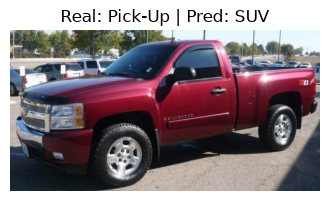

[Pick-Up] 03083_Chevrolet-Silverado-1500-Hybrid-Crew-Cab-2012_jpg.rf.86ccd3d93aa5a9a01d9b4b8edbf83829.jpg → Predicción: SUV


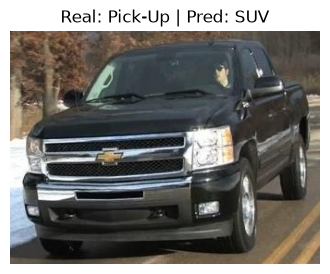

[Pick-Up] 03097_HUMMER-H2-SUT-Crew-Cab-2009_jpg.rf.14fef3d8fdca5dd3e33ecacaa54e0dd6.jpg → Predicción: SUV


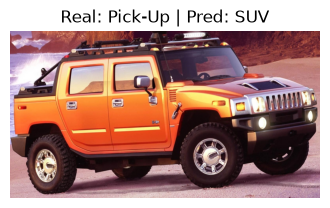

[Pick-Up] 03176_Ford-F-450-Super-Duty-Crew-Cab-2012_jpg.rf.863f56d37da2aefa09d580d20f65836c.jpg → Predicción: SUV


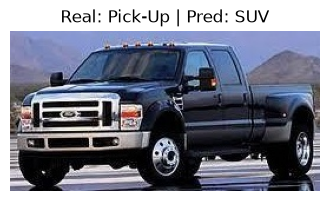

[Pick-Up] 03247_HUMMER-H2-SUT-Crew-Cab-2009_jpg.rf.2d0a4da895098ac18fde7d2c962eaf69.jpg → Predicción: SUV


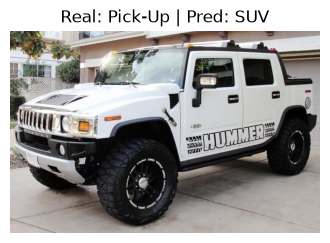

[Pick-Up] 03420_Dodge-Dakota-Crew-Cab-2010_jpg.rf.cbb86c42d6a9ad6b3a6d0e02ef21e6e3.jpg → Predicción: SUV


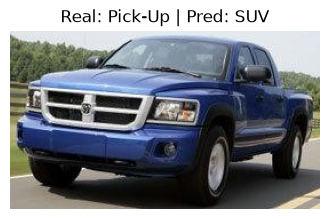

[Pick-Up] 03505_Dodge-Ram-Pickup-3500-Quad-Cab-2009_jpg.rf.5a140ba2b02dcbe5fa448e2d2dc4636c.jpg → Predicción: SUV


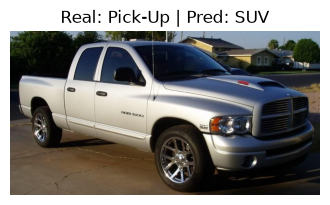

[Pick-Up] 03519_Ford-F-150-Regular-Cab-2012_jpg.rf.ff3a9c35a1e7ae60b06c56b60ca411c7.jpg → Predicción: SUV


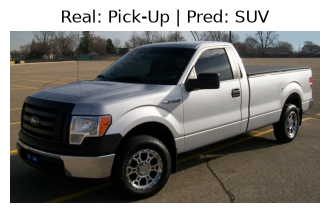

[Pick-Up] 03843_HUMMER-H2-SUT-Crew-Cab-2009_jpg.rf.273b52d9833daa1b1e7e388a61bee622.jpg → Predicción: SUV


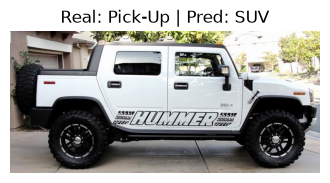

[Pick-Up] 04147_GMC-Canyon-Extended-Cab-2012_jpg.rf.c7d78f602831150c00a44da8d2359dbe.jpg → Predicción: SUV


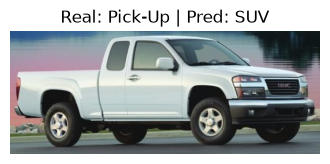

[Pick-Up] 04180_Chevrolet-Avalanche-Crew-Cab-2012_jpg.rf.f92a9097dc0993568dd42da3819a99c6.jpg → Predicción: SUV


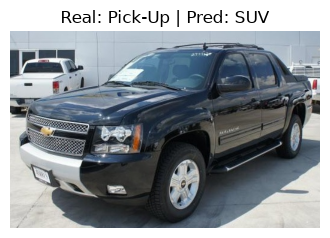

[Pick-Up] 04187_Chevrolet-Silverado-1500-Extended-Cab-2012_jpg.rf.9f89cc953116b7c126f6944d4774eae0.jpg → Predicción: SUV


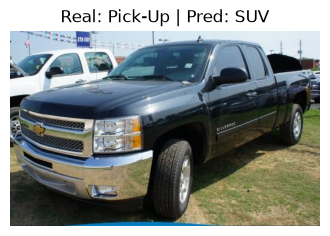

[Pick-Up] 04439_Chevrolet-Silverado-2500HD-Regular-Cab-2012_jpg.rf.ef403077c02f490eccae2b2ae767a1c5.jpg → Predicción: SUV


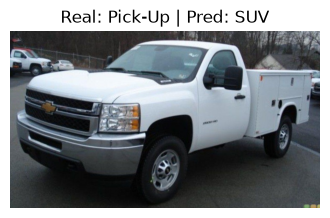

[Pick-Up] 04607_Ford-F-450-Super-Duty-Crew-Cab-2012_jpg.rf.13ac4e9c3094c7aaea51b24d91986f10.jpg → Predicción: SUV


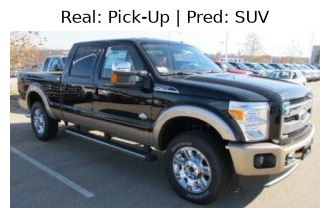

[Pick-Up] 04610_Chevrolet-Silverado-1500-Classic-Extended-Cab-2007_jpg.rf.423c6360b6647d1c3cd3b84a8375e763.jpg → Predicción: SUV


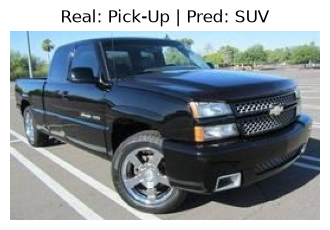

[Pick-Up] 04638_Chevrolet-Silverado-1500-Regular-Cab-2012_jpg.rf.f6542eda04f2a71dbde0fdd7375b84e9.jpg → Predicción: SUV


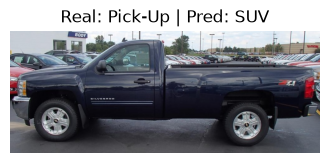

[Pick-Up] 04774_Chevrolet-Silverado-1500-Hybrid-Crew-Cab-2012_jpg.rf.21d4ff2fb32805931762d1d4935f943e.jpg → Predicción: SUV


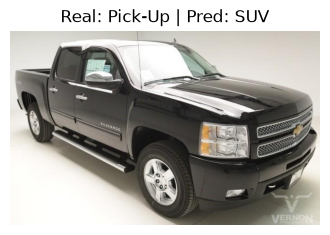

[Pick-Up] 04845_Chevrolet-Silverado-1500-Classic-Extended-Cab-2007_jpg.rf.456bdad8ee769177c8357ee0bd4cf5d8.jpg → Predicción: SUV


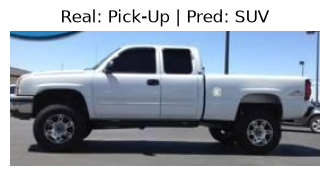

[Pick-Up] 04899_Chevrolet-Avalanche-Crew-Cab-2012_jpg.rf.c3be2a29fddae86015fd8f2e45015f3c.jpg → Predicción: SUV


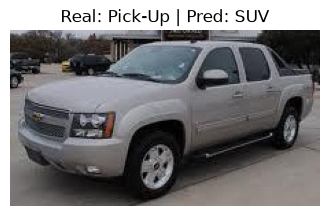

[Pick-Up] 05221_Chevrolet-Silverado-2500HD-Regular-Cab-2012_jpg.rf.99d0cc0e7e4d3b782b64a856a985168e.jpg → Predicción: SUV


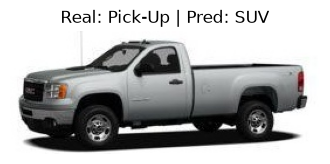

[Pick-Up] 05269_Chevrolet-Silverado-2500HD-Regular-Cab-2012_jpg.rf.d7e31dd52fe1ad556d221445b1df11aa.jpg → Predicción: SUV


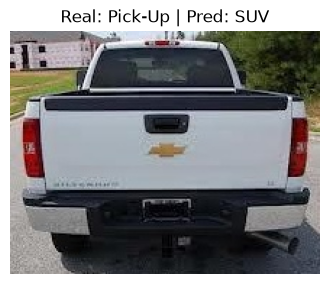

[Pick-Up] 05919_Ford-F-450-Super-Duty-Crew-Cab-2012_jpg.rf.391e0b5633f8925240fcac7f5a2e9b31.jpg → Predicción: SUV


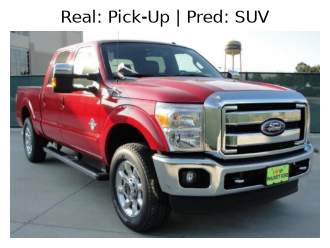

[Pick-Up] 05960_Dodge-Dakota-Crew-Cab-2010_jpg.rf.5567cb9101db8d7836abf856a539d0f7.jpg → Predicción: SUV


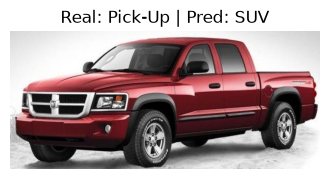

[Pick-Up] 05984_Chevrolet-Silverado-1500-Regular-Cab-2012_jpg.rf.e220b50fcd47f3e89bb7c785b96397a3.jpg → Predicción: SUV


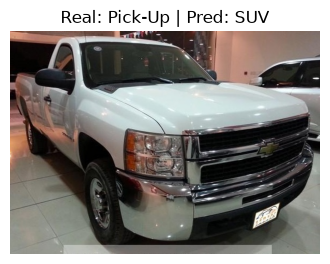

[Pick-Up] 06248_Dodge-Dakota-Crew-Cab-2010_jpg.rf.62498e882a4d826801cc7f0e1730c714.jpg → Predicción: SUV


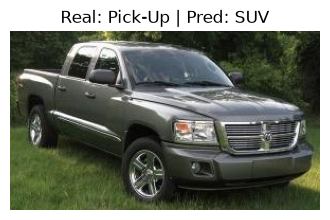

[Pick-Up] 06305_Chevrolet-Silverado-1500-Hybrid-Crew-Cab-2012_jpg.rf.385cae3d25e2eed0bbf768957af9bc10.jpg → Predicción: SUV


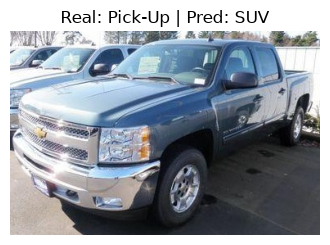

[Pick-Up] 06396_Chevrolet-Silverado-1500-Hybrid-Crew-Cab-2012_jpg.rf.41c658d45291f69d300f15df27c82338.jpg → Predicción: SUV


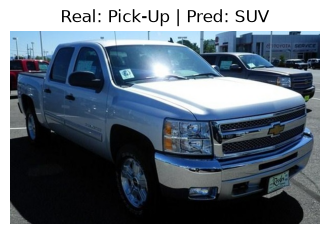

[Pick-Up] 06456_Chevrolet-Silverado-2500HD-Regular-Cab-2012_jpg.rf.028f13376e2167f405a4d3f9864b41b2.jpg → Predicción: SUV


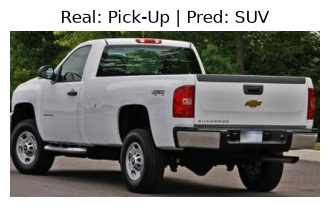

[Pick-Up] 06566_Cadillac-Escalade-EXT-Crew-Cab-2007_jpg.rf.d6988f887597bcc096437129804b555c.jpg → Predicción: SUV


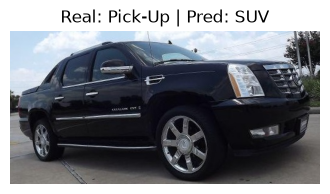

[Pick-Up] 06775_Ford-F-450-Super-Duty-Crew-Cab-2012_jpg.rf.cba0399e443e8f0cacde01cce0d16fa6.jpg → Predicción: SUV


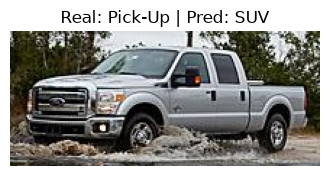

[Pick-Up] 06814_Ford-F-450-Super-Duty-Crew-Cab-2012_jpg.rf.f9121356d72aa84566bd20378357fdb2.jpg → Predicción: SUV


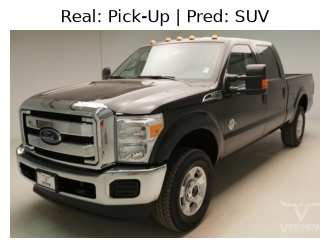

[Pick-Up] 06875_HUMMER-H2-SUT-Crew-Cab-2009_jpg.rf.b94055f60cfb809bb3c591a2488cf19e.jpg → Predicción: SUV


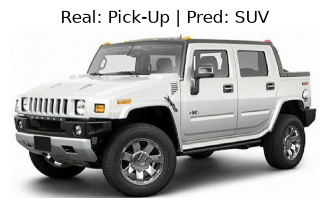

[Pick-Up] 06878_Ford-F-150-Regular-Cab-2007_jpg.rf.0d2299d3c769a9a61f9d0d9d1cfb3a19.jpg → Predicción: SUV


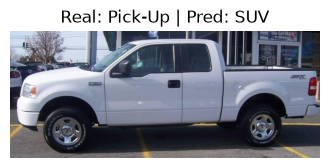

[Pick-Up] 06931_Dodge-Ram-Pickup-3500-Quad-Cab-2009_jpg.rf.d2ff93e7f862c441907b53e64b9c3393.jpg → Predicción: SUV


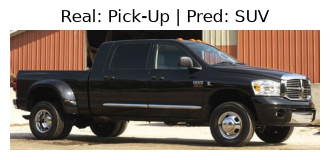

[Pick-Up] 06967_Ford-F-150-Regular-Cab-2012_jpg.rf.57bd87254b30f597d27fa38745b6dd25.jpg → Predicción: SUV


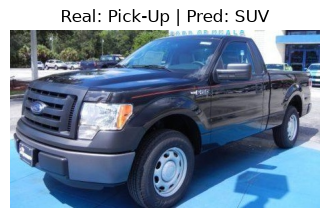

[Pick-Up] 07064_Dodge-Ram-Pickup-3500-Crew-Cab-2010_jpg.rf.1ee05bdeb7be9a4dcdbf6b483e40cf73.jpg → Predicción: SUV


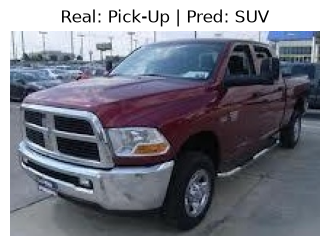

[Pick-Up] 07387_Chevrolet-Silverado-1500-Regular-Cab-2012_jpg.rf.1eeb7282c153d30ec174865af5d90689.jpg → Predicción: SUV


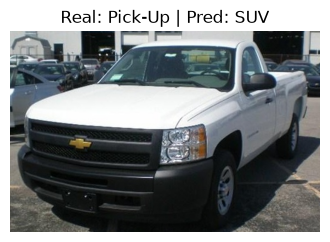

[Pick-Up] 07631_Dodge-Ram-Pickup-3500-Crew-Cab-2010_jpg.rf.30662e0ca9b7387ab17c6e83bee9515d.jpg → Predicción: SUV


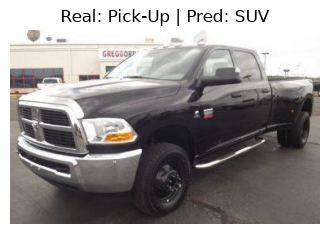

[Pick-Up] 07775_Ford-F-450-Super-Duty-Crew-Cab-2012_jpg.rf.45260e64900269254b862f4ad8729c52.jpg → Predicción: SUV


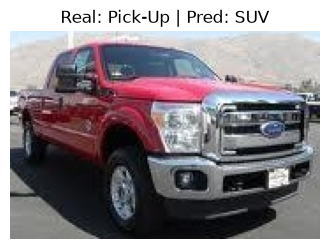

[Pick-Up] 08080_Chevrolet-Silverado-1500-Regular-Cab-2012_jpg.rf.b26a0fe1489323cfb847aa25cdd7c2c8.jpg → Predicción: SUV


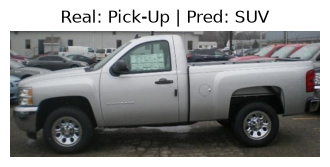

[Pick-Up] 08090_Dodge-Dakota-Crew-Cab-2010_jpg.rf.f6fcebfd9e247cdfabc61ea965473667.jpg → Predicción: SUV


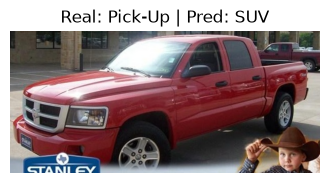

[Pick-Up] 109_jpg.rf.b6dd7cbacb42d03753f9bb386fbbb822.jpg → Predicción: SUV


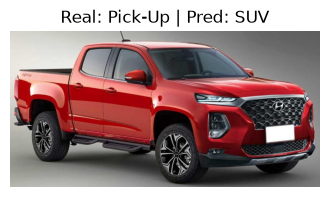

[Pick-Up] 117_jpg.rf.390e928ab0af2bb3932213e087010187.jpg → Predicción: SUV


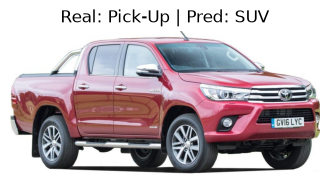

[Pick-Up] 126_jpg.rf.78364b893cc2684bb3b34ded9c0954ee.jpg → Predicción: SUV


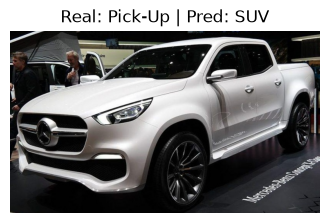

[Pick-Up] 141_jpg.rf.6f86321cf96c3494b0bd32b480b02d9f.jpg → Predicción: SUV


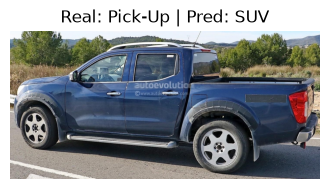

[Pick-Up] 163_jpg.rf.cca5405c5f6d989013375015e43670e9.jpg → Predicción: SUV


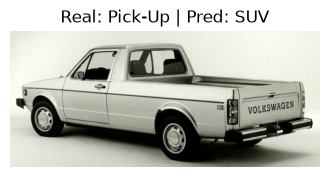

[Pick-Up] 201811052132212_jpg.rf.1118dbdaf22303ebdf5a11415be32afe.jpg → Predicción: SUV


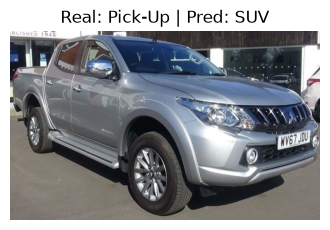

[Pick-Up] 202010094808444_jpg.rf.815c7928de690c1672fd4a49b88d090d.jpg → Predicción: SUV


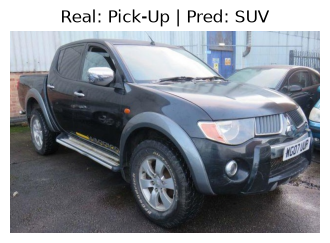

[Pick-Up] 202011075885589_jpg.rf.cb7a772d2c906d8600b5084271d1711f.jpg → Predicción: SUV


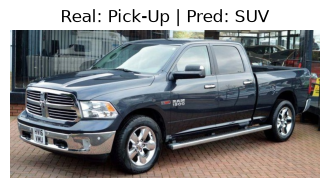

[Pick-Up] 202012076865092_jpg.rf.84c0b306dc5e9033e251c0303c85f8ef.jpg → Predicción: SUV


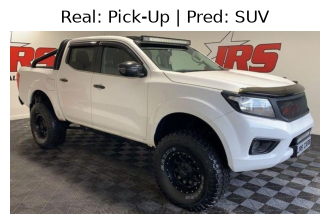

[Pick-Up] 202012237349121_jpg.rf.251480957a5d8565207a58022ae6046b.jpg → Predicción: SUV


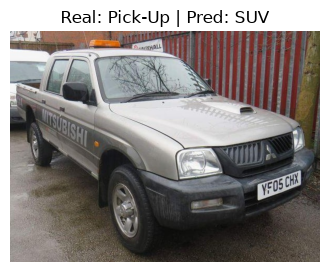

[Pick-Up] 202102038659071_jpg.rf.394d433af2f452dda8018e11d476a60a.jpg → Predicción: SUV


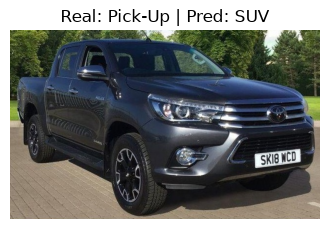

[Pick-Up] 202102098858148_jpg.rf.95706dd6ae7784a88d9e7f6468055778.jpg → Predicción: SUV


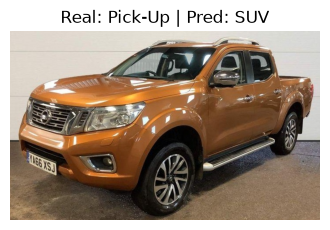

[Pick-Up] 202102219304680_jpg.rf.e1755a853ad10f2b8c5aec494b68ff2c.jpg → Predicción: SUV


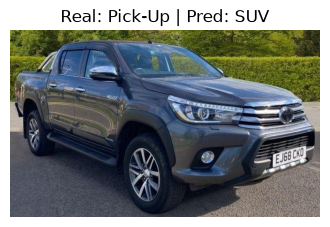

[Pick-Up] 202102279524622_jpg.rf.7751f09342ff631e5569cd1d37d4ddc8.jpg → Predicción: SUV


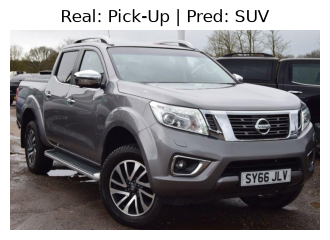

[Pick-Up] 202103109972347_jpg.rf.c3c9a23fdaec85088229a4af72f5ff1b.jpg → Predicción: SUV


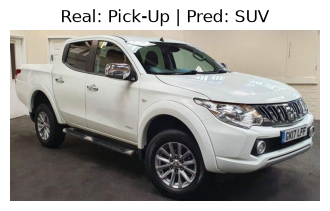

[Pick-Up] 202103160192445_jpg.rf.6a357365a34ab01cee19e72dd5b67ba1.jpg → Predicción: SUV


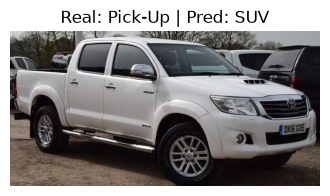

[Pick-Up] 202103160212048_jpg.rf.2c2264612b6dfda654026fa4008a49a6.jpg → Predicción: SUV


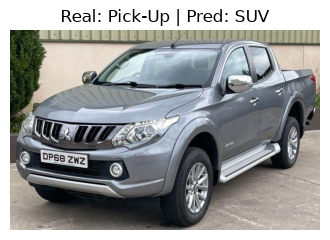

[Pick-Up] 202103170235456_jpg.rf.d159b7f40fed9ea0d1ba557c702513f4.jpg → Predicción: SUV


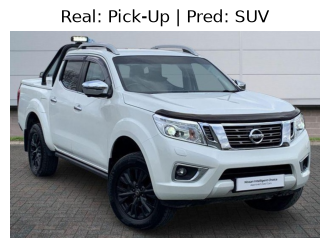

[Pick-Up] 202103170259809_jpg.rf.b288857eb9684960dc565cea2c627a94.jpg → Predicción: SUV


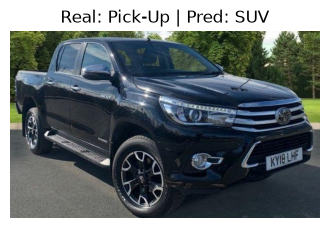

[Pick-Up] 202103190319831_jpg.rf.ab7b274dd513c31c44714d80b4037be3.jpg → Predicción: SUV


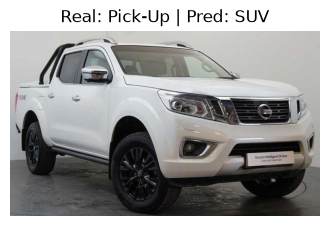

[Pick-Up] 202103210423203_jpg.rf.3e6d7b5bcae638e068e31b9cf39fafe5.jpg → Predicción: SUV


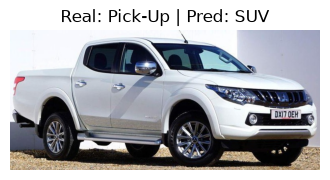

[Pick-Up] 202103240520601_jpg.rf.406751f5504027b7bea0480a5be0d8bf.jpg → Predicción: SUV


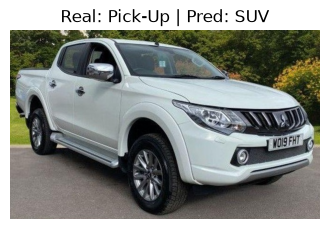

[Pick-Up] 202104131314584_jpg.rf.057459e0e8e21944a6d24d578ee76e32.jpg → Predicción: SUV


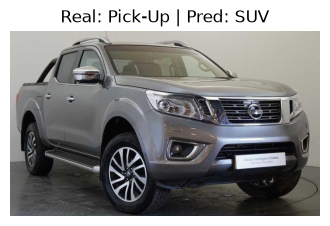

[Pick-Up] 202104181524156_jpg.rf.3ffd56c28dfbdbf3709ea25785d26d70.jpg → Predicción: SUV


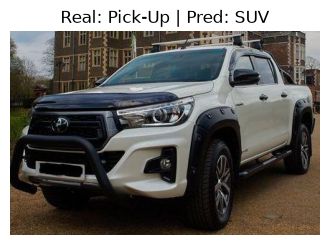

[Pick-Up] 202104201582222_jpg.rf.b2a21fc54bbbc662da71bfc48ae5682b.jpg → Predicción: SUV


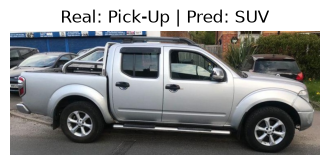

[Pick-Up] 202104241772153_jpg.rf.317f2c3e9df750f7e58867365929697d.jpg → Predicción: SUV


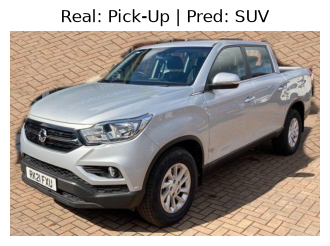

[Pick-Up] 202104271893373_jpg.rf.58dcb195f9422d4b767564e487d39804.jpg → Predicción: SUV


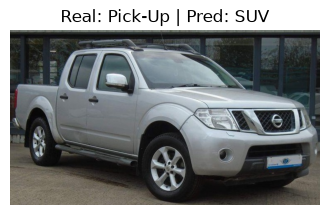

[Pick-Up] 202105062285557_jpg.rf.1d488de5eeedc9a3df13d0989dd2e831.jpg → Predicción: SUV


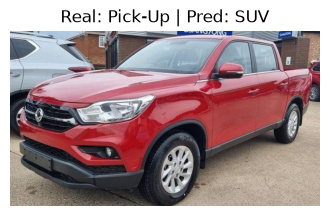

[Pick-Up] 202105273142426_jpg.rf.fdbb5b2d8be2e555df042bed0687d862.jpg → Predicción: SUV


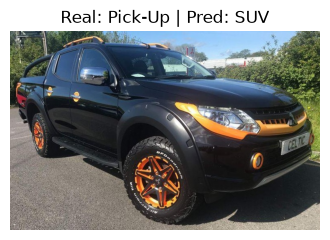

[Pick-Up] 202106033423614_jpg.rf.b97e51f76b730e74eb6c191cd62149ca.jpg → Predicción: SUV


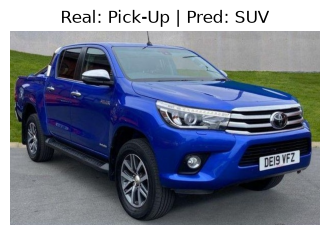

[Pick-Up] 202106043478103_jpg.rf.d395a38ea9eaf0f7debbbc7021b7e23e.jpg → Predicción: SUV


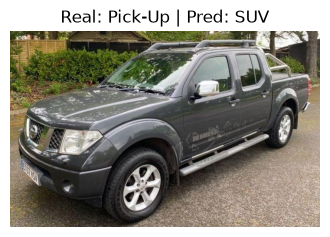

[Pick-Up] 202106093655170_jpg.rf.152ca46a2d5f81b55667bea0bb7f1421.jpg → Predicción: SUV


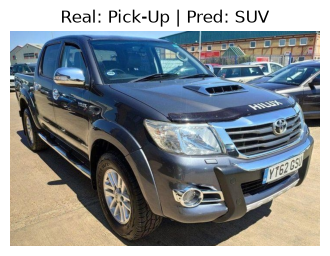

[Pick-Up] 202106103698582_jpg.rf.86222e6bf474bf413098763c14e03184.jpg → Predicción: SUV


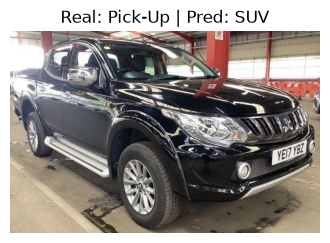

[Pick-Up] 202106103711086_jpg.rf.6273805d7ba20f3fcfbcc87759534dec.jpg → Predicción: SUV


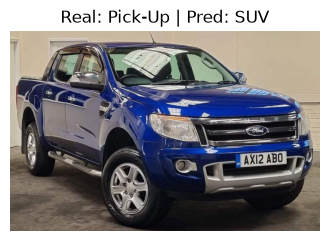

[Pick-Up] 202106113734149_jpg.rf.92b1819e82d0645cb03ef58e9645318f.jpg → Predicción: SUV


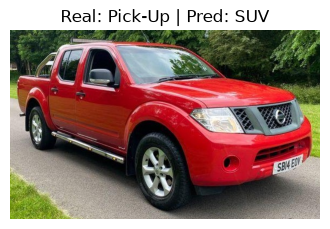

[Pick-Up] 20_jpg.rf.55932a977b8942ef61ead7a9d262e880.jpg → Predicción: SUV


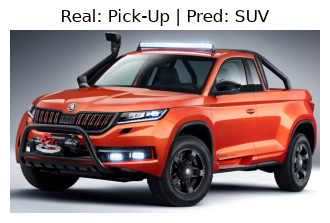

[Pick-Up] 40_jpg.rf.1d9a6a1d92fa7dddca9774acaec90a8a.jpg → Predicción: SUV


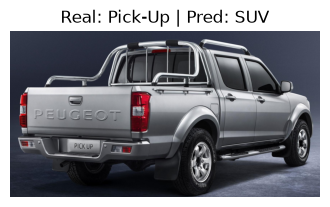

[Pick-Up] 4_jpg.rf.be8489fc136ff20a6432262dda6b3001.jpg → Predicción: SUV


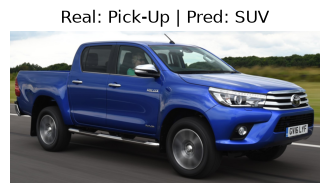

[Pick-Up] 78_jpg.rf.98762f743265e57acb684d0ad2c9a381.jpg → Predicción: SUV


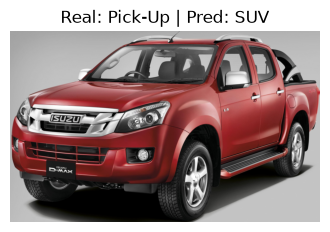

[Pick-Up] 81_jpg.rf.51ddffcd5145df4aa9b3957ddfbabf45.jpg → Predicción: SUV


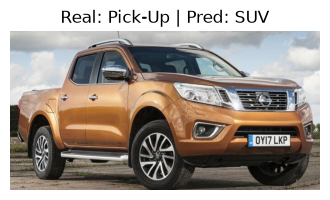

[Pick-Up] 87_jpg.rf.5897613d65664363db1c2c14f6fd7b52.jpg → Predicción: SUV


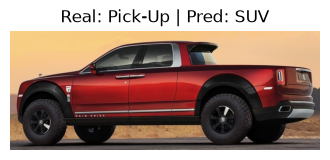

[Pick-Up] Image_123_jpg.rf.a147822042f234e2212a2589511fa2ce.jpg → Predicción: SUV


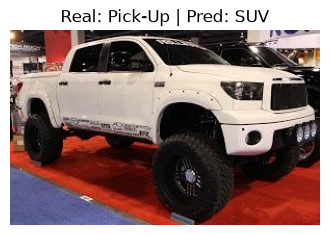

[Pick-Up] Image_131_jpg.rf.4c3c6ad5b4658532d0edc8ebb635f746.jpg → Predicción: SUV


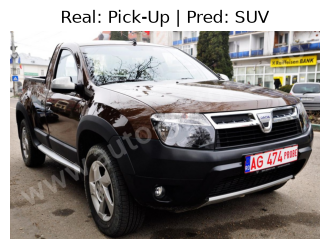

[Pick-Up] Image_137_jpg.rf.2291a2ae1c8f0c7bf466b9d9164cb4ae.jpg → Predicción: SUV


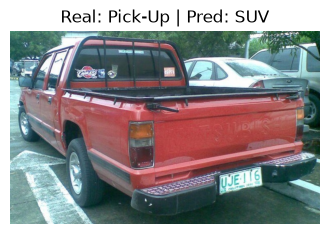

[Pick-Up] Image_13_jpg.rf.486ceab0dc10e91497144676e2f31fe0.jpg → Predicción: SUV


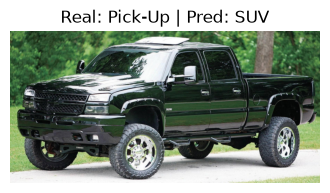

[Pick-Up] Image_149_jpg.rf.2508a92c370ed6e88275950af2943e1b.jpg → Predicción: SUV


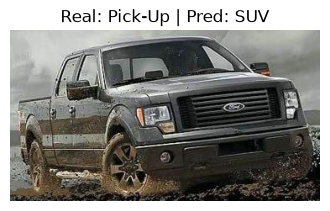

[Pick-Up] Image_152_jpg.rf.3023727205bec7c5f8685d540cbe5cf8.jpg → Predicción: SUV


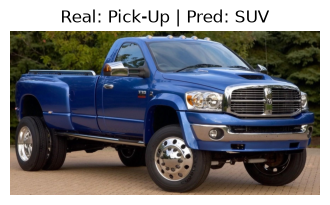

[Pick-Up] Image_27_jpg.rf.31e6e312b2e000e60788d4c4bde04b6d.jpg → Predicción: SUV


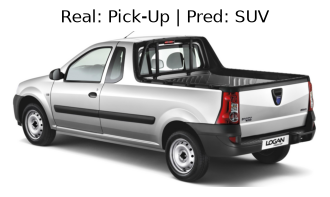

[Pick-Up] Image_64_jpg.rf.8ecda56f53c9d1da6f796868c4322dc0.jpg → Predicción: SUV


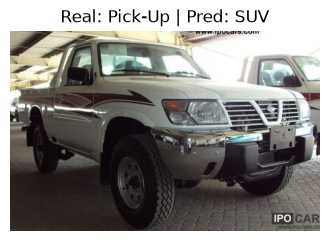

[Pick-Up] Image_66_jpg.rf.5e321eb912afd483a9c465dc6fb45d8c.jpg → Predicción: SUV


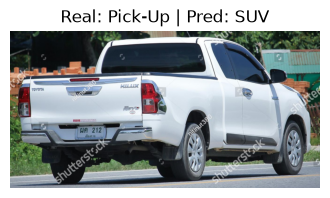

[Pick-Up] Image_95_jpg.rf.e14a8b0d1f6c7e415bb36c65a20fd96e.jpg → Predicción: SUV


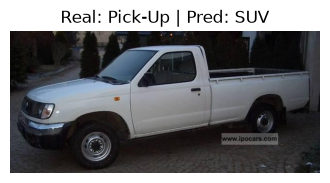

[Sedan] 00396_Mercedes-Benz-S-Class-Sedan-2012_jpg.rf.04a61fce50041d537ef643c2f473d6d3.jpg → Predicción: SUV


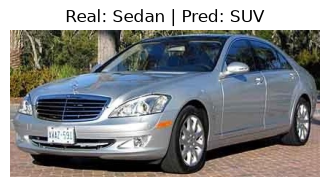

[Sedan] 00454_Buick-Verano-Sedan-2012_jpg.rf.af21e9d5ab272ef95cc4cc113bb8d438.jpg → Predicción: SUV


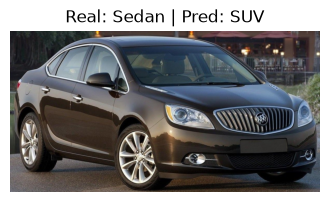

[Sedan] 00793_Audi-S4-Sedan-2007_jpg.rf.51cef7d5c5b02b4fb3f6b58e0b612dae.jpg → Predicción: SUV


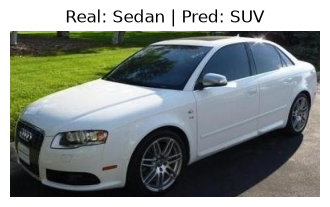

[Sedan] 00956_Audi-S6-Sedan-2011_jpg.rf.56897450afb9acdde4f77e1f0dc4cc4e.jpg → Predicción: SUV


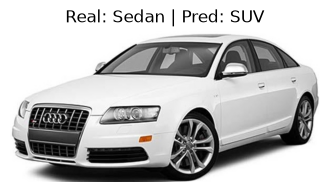

[Sedan] 01007_Hyundai-Genesis-Sedan-2012_jpg.rf.b272a1278028eac6ff664153e2d3337f.jpg → Predicción: SUV


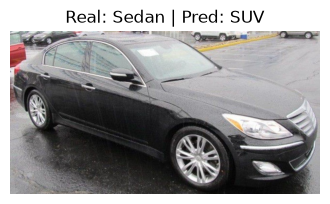

[Sedan] 01033_Chevrolet-Impala-Sedan-2007_jpg.rf.c499b796222091d4ff3d9c0d551f9b7b.jpg → Predicción: SUV


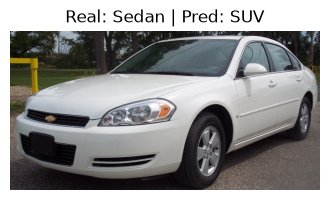

[Sedan] 01034_Acura-RL-Sedan-2012_jpg.rf.8ecafd09e129bc2c570a4ab509944692.jpg → Predicción: SUV


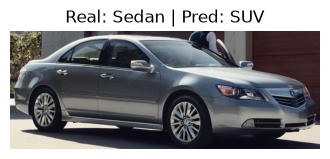

[Sedan] 01654_Chevrolet-Sonic-Sedan-2012_jpg.rf.97f56089d66eff802ac8232489420c36.jpg → Predicción: SUV


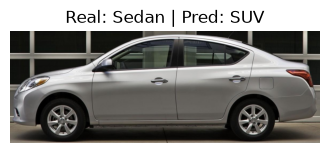

[Sedan] 01705_Acura-TL-Sedan-2012_jpg.rf.3037690dd2afcca2b96fd72222854cfc.jpg → Predicción: SUV


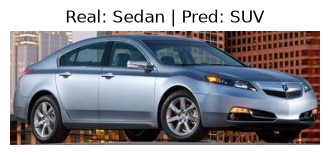

[Sedan] 01870_Acura-TL-Sedan-2012_jpg.rf.70606d47729abff212ef0e9aec0d555f.jpg → Predicción: SUV


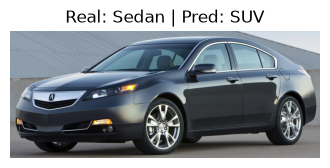

[Sedan] 01899_Hyundai-Elantra-Sedan-2007_jpg.rf.a97a0a0fc46868fdbf21186d41ccabb2.jpg → Predicción: SUV


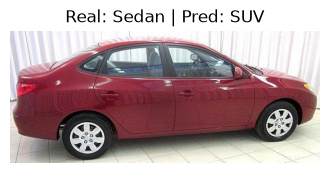

[Sedan] 01922_Suzuki-Kizashi-Sedan-2012_jpg.rf.6cdd0fa1bab29eb9ecfc909628a43a2c.jpg → Predicción: SUV


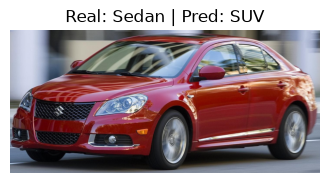

[Sedan] 02832_Acura-TL-Sedan-2012_jpg.rf.c53f38ec5e4e9f4cd67c52c42371c2a8.jpg → Predicción: SUV


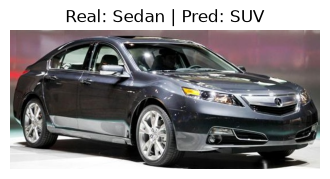

[Sedan] 03256_Hyundai-Azera-Sedan-2012_jpg.rf.bf1d76ed4c8c371e2c67d6a51cf8c2d7.jpg → Predicción: SUV


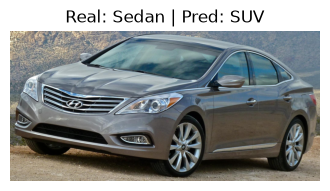

[Sedan] 03367_Audi-S6-Sedan-2011_jpg.rf.adae9cffd9ec959ca6f1b2a573ab2f62.jpg → Predicción: SUV


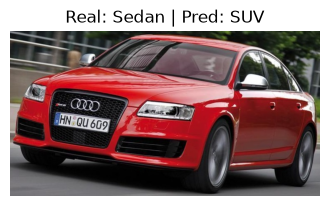

[Sedan] 03543_Audi-S6-Sedan-2011_jpg.rf.d4285cdfe7c46b6662bfe7114f3d2eea.jpg → Predicción: SUV


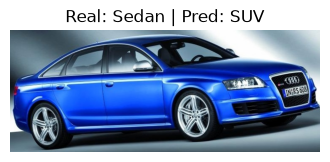

[Sedan] 03663_Hyundai-Genesis-Sedan-2012_jpg.rf.0dbde9b9e986fe8529570d27ccc05d3b.jpg → Predicción: SUV


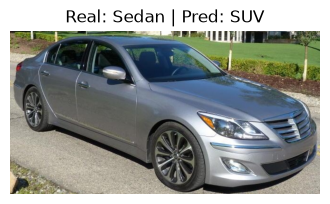

[Sedan] 03824_Audi-S4-Sedan-2012_jpg.rf.b20c83ea944150b99be19598874b8880.jpg → Predicción: SUV


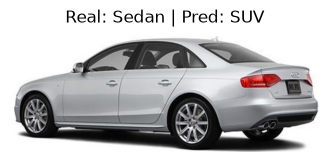

[Sedan] 03855_Audi-S4-Sedan-2007_jpg.rf.6c85dc03a752a0b23bdf227bbcb2e3be.jpg → Predicción: SUV


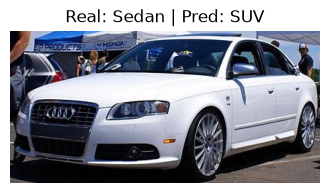

[Sedan] 03998_Chevrolet-Malibu-Hybrid-Sedan-2010_jpg.rf.8ba8ef99eecc4065806674f595a206cb.jpg → Predicción: SUV


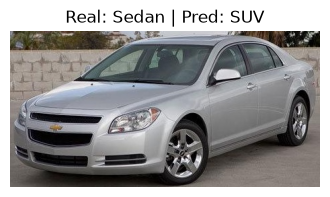

[Sedan] 05293_Hyundai-Sonata-Sedan-2012_jpg.rf.ffa7de42b8b8822ea5c48c29cea75f85.jpg → Predicción: SUV


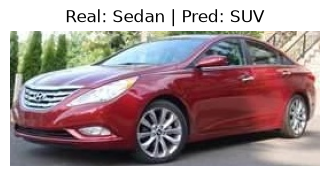

[Sedan] 06669_Hyundai-Sonata-Hybrid-Sedan-2012_jpg.rf.5879a51c2a418c1bc598ae80be09292c.jpg → Predicción: SUV


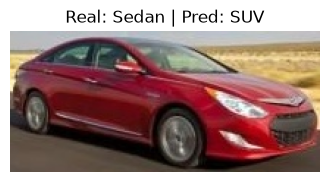

[Sedan] 06686_Hyundai-Azera-Sedan-2012_jpg.rf.44479eba7bfa2be9d26171b6a493a152.jpg → Predicción: SUV


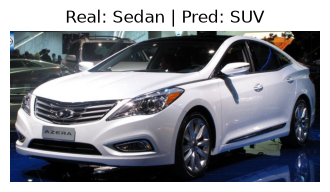

[Sedan] 06745_Hyundai-Genesis-Sedan-2012_jpg.rf.ee51e21b37d5f932af32aae612f20e03.jpg → Predicción: SUV


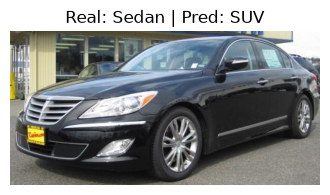

[Sedan] 06852_Audi-S4-Sedan-2007_jpg.rf.7301e1ccb758e5bd688901a7c48bbac0.jpg → Predicción: SUV


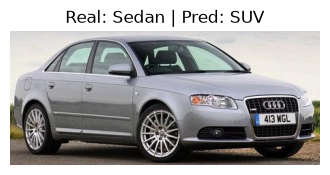

[Sedan] 07078_Hyundai-Azera-Sedan-2012_jpg.rf.881274c2ba4e3a1959cc271f32dc6eb1.jpg → Predicción: SUV


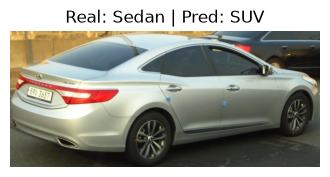

[Sedan] 07140_Mercedes-Benz-C-Class-Sedan-2012_jpg.rf.da9f42d4cd082ec4c69b3e86cf5cd681.jpg → Predicción: SUV


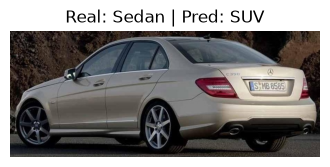

[Sedan] 07348_Hyundai-Azera-Sedan-2012_jpg.rf.b6734a4e7fed3736037160a0a8a18699.jpg → Predicción: SUV


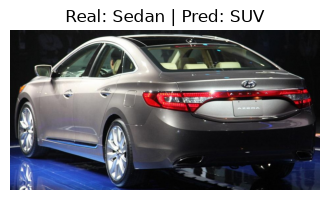

[Sedan] 07357_Hyundai-Sonata-Sedan-2012_jpg.rf.27d4f2e81008ed94e0d7dc3f49089091.jpg → Predicción: SUV


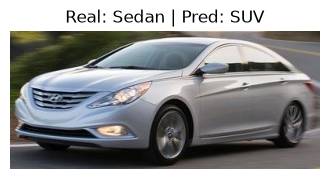

[Sedan] 07501_BMW-ActiveHybrid-5-Sedan-2012_jpg.rf.6ef4512a007ee244c003e66e1bc1375f.jpg → Predicción: SUV


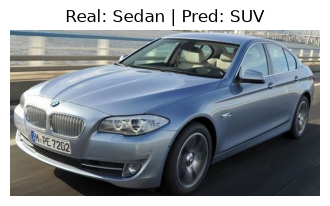

[Sedan] 07606_Mercedes-Benz-E-Class-Sedan-2012_jpg.rf.14e7a1c36683293d1f109087d2957073.jpg → Predicción: SUV


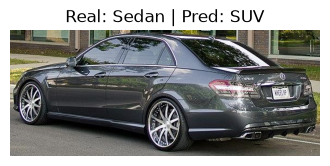

[Sedan] 07612_Ford-Fiesta-Sedan-2012_jpg.rf.c087d37731d53313276e1e15a5f3ed4d.jpg → Predicción: SUV


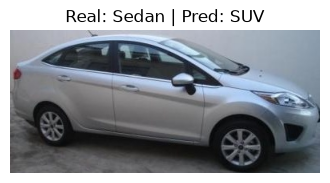

[Sedan] 07614_Chevrolet-Sonic-Sedan-2012_jpg.rf.201dac9d157eebfa747ee375925d25d5.jpg → Predicción: SUV


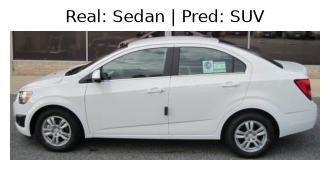

[Sedan] 07888_Mercedes-Benz-E-Class-Sedan-2012_jpg.rf.6485fad6958eee4699092f2411adb65e.jpg → Predicción: SUV


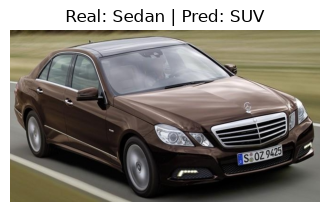

[Sedan] 07908_Buick-Verano-Sedan-2012_jpg.rf.0e87207290a2375dd1735cb65e16e073.jpg → Predicción: SUV


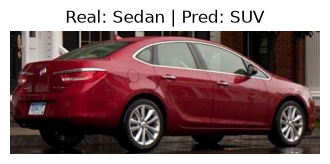

[Sedan] 07948_Bentley-Continental-Flying-Spur-Sedan-2007_jpg.rf.7521bb8b0e39abdef85569b672df8254.jpg → Predicción: SUV


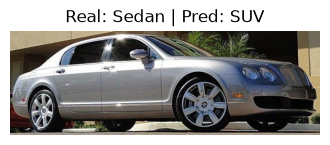

[Sedan] 103_jpg.rf.dc12662883198e3d5952c75f7feef9ef.jpg → Predicción: SUV


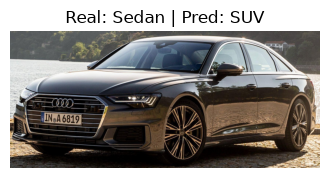

[Sedan] 106_jpg.rf.07ac69a7325e421d101cc6ddea947f44.jpg → Predicción: SUV


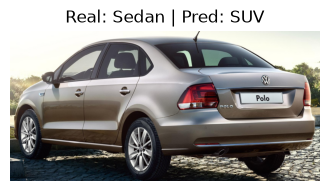

[Sedan] 10_jpg.rf.3d784d442fa046b2ec60e8e0a205320f.jpg → Predicción: SUV


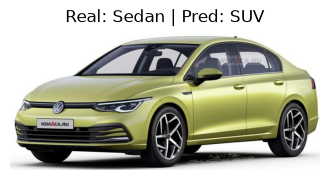

[Sedan] 141_jpg.rf.ce158ba94da69e8f6978809064c843ff.jpg → Predicción: SUV


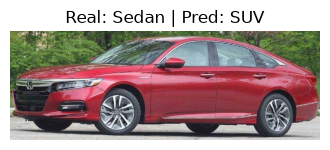

[Sedan] 159_jpg.rf.e2696477cb56cb90d905e141fc3758bf.jpg → Predicción: SUV


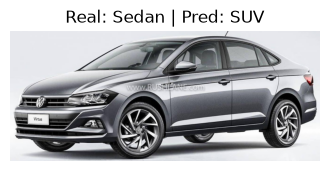

[Sedan] 162_jpg.rf.2205d967e53b1ecadc9061e903c1bab8.jpg → Predicción: SUV


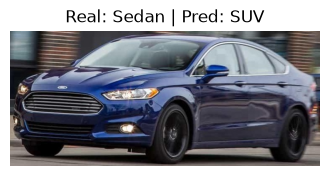

[Sedan] 162_jpg.rf.d16ea492ed4573b2dbe1b1a6878f3bc9.jpg → Predicción: SUV


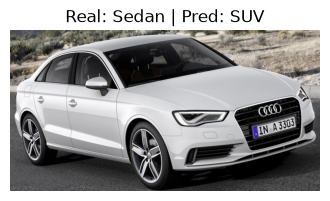

[Sedan] 179_jpg.rf.82f73ff61e4276b6e9c85c47564c82c8.jpg → Predicción: SUV


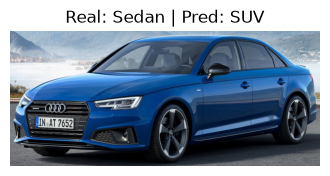

[Sedan] 18_jpg.rf.4369c2e7aa675ad1e098619e3eb7c34d.jpg → Predicción: SUV


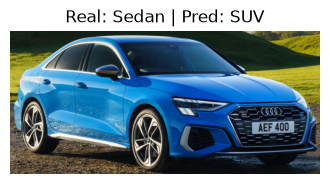

[Sedan] 193_jpg.rf.87db46f37852576c8c2729fe18930986.jpg → Predicción: SUV


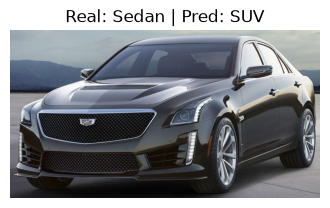

[Sedan] 203_jpg.rf.36c857e44dc09aef1a969219c31fbeec.jpg → Predicción: SUV


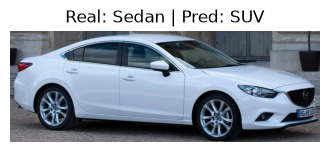

[Sedan] 206_jpg.rf.010ce14b03056b4d98554b8083712f3f.jpg → Predicción: SUV


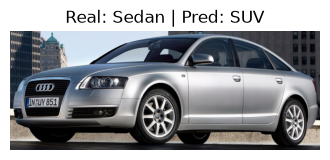

[Sedan] 207_jpg.rf.2e79ae2383f1791eb1aecbabd41f2b91.jpg → Predicción: SUV


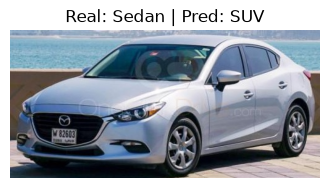

[Sedan] 213_jpg.rf.08e42570ec7a3db1504e86806e9b714f.jpg → Predicción: SUV


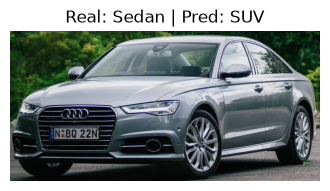

[Sedan] 21_jpg.rf.e6a6ed9f9e3754653b2ee0acfd73b598.jpg → Predicción: SUV


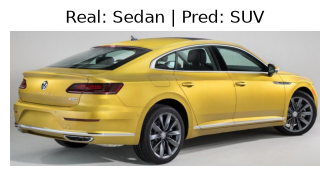

[Sedan] 220_jpg.rf.38ed535dc665e71dc4d2c30c5f99e02b.jpg → Predicción: SUV


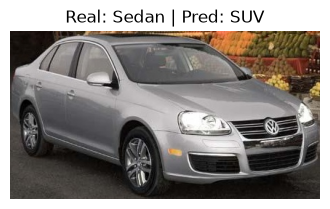

[Sedan] 222_jpg.rf.63606edd78f764cc7686f098731d5b42.jpg → Predicción: SUV


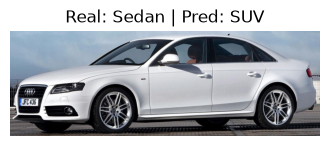

[Sedan] 229_jpg.rf.d450fd448c0911e2df1a4335469213cb.jpg → Predicción: SUV


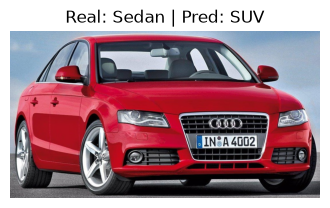

[Sedan] 232_jpg.rf.fb1306d0ae2b3b9b1bda087017593237.jpg → Predicción: SUV


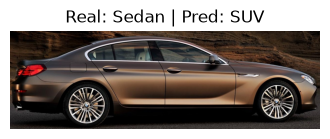

[Sedan] 235_jpg.rf.1cdbb1fd6640a46c3a82834fe7df1ef1.jpg → Predicción: SUV


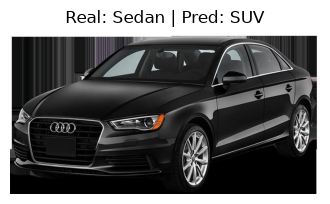

[Sedan] 236_jpg.rf.de3f1e9f6fe00c166c8e15dac4449edb.jpg → Predicción: SUV


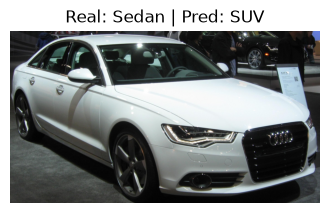

[Sedan] 241_jpg.rf.7ef9151632c874f7d1f09d945d521189.jpg → Predicción: SUV


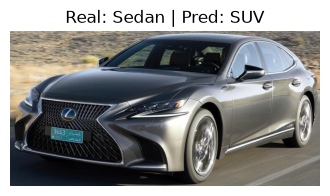

[Sedan] 244_jpg.rf.45b065b1486c93d9f336c646be4e3c6a.jpg → Predicción: SUV


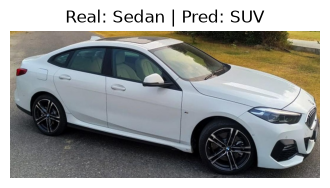

[Sedan] 255_jpg.rf.e81ede617fff104162d8542279d3e8ef.jpg → Predicción: SUV


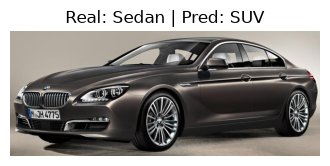

[Sedan] 264_jpg.rf.8736a2617db1a4198160c51ceff0e9f2.jpg → Predicción: SUV


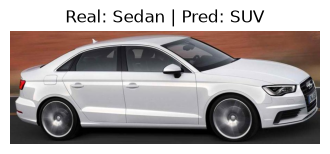

[Sedan] 267_jpg.rf.46faff617b00ec546413f797b01b4a6a.jpg → Predicción: SUV


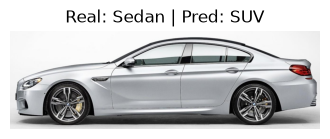

[Sedan] 276_jpg.rf.b3a7e08f7438af7bde53d95c6bcc105a.jpg → Predicción: SUV


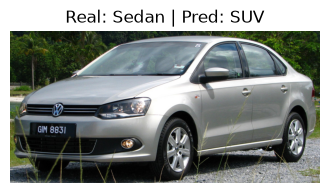

[Sedan] 277_jpg.rf.cd41fa620db323d95571cb52f07ab9ba.jpg → Predicción: SUV


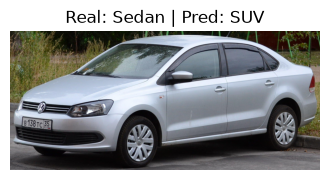

[Sedan] 290_jpg.rf.207cd9f62116bf2c77448c154e7f2b26.jpg → Predicción: SUV


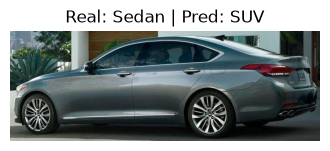

[Sedan] 294_jpg.rf.9e5ed9853fd402eb08473345a04f0a3a.jpg → Predicción: SUV


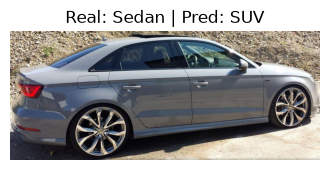

[Sedan] 363_jpg.rf.673328c428ef5ba78eeabe25803178d4.jpg → Predicción: SUV


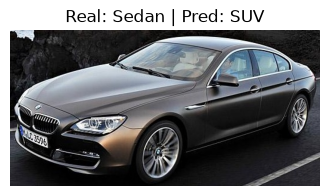

[Sedan] 38_jpg.rf.952f621894cab166f6ffd36eec1d251d.jpg → Predicción: SUV


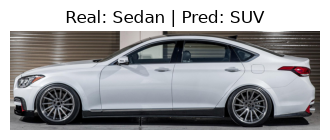

[Sedan] 392_jpg.rf.10c39b1a1164dc3fbaa8a164f16756f0.jpg → Predicción: SUV


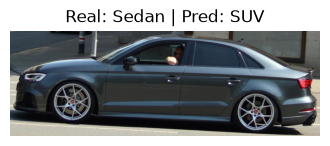

[Sedan] 393_jpg.rf.39782abf76779088ad2b8f4a10583302.jpg → Predicción: SUV


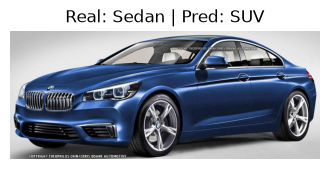

[Sedan] 404_jpg.rf.2c3003296b554e21c0c7eb19d33e6430.jpg → Predicción: SUV


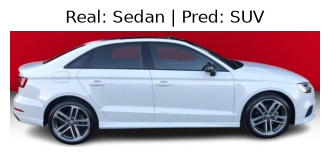

[Sedan] 40_jpg.rf.25bea7dbc6aa4bcc948fabfe7562a1d6.jpg → Predicción: SUV


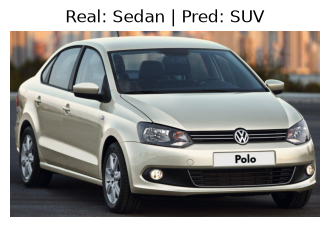

[Sedan] 44_jpg.rf.23b9e70b373e3ef5baf027fa4f0cfdc3.jpg → Predicción: SUV


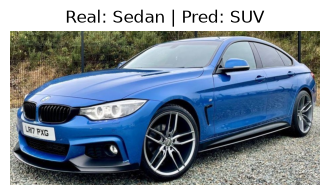

[Sedan] 466_jpg.rf.8d8a381b018b0b99d6acfb500da704fa.jpg → Predicción: SUV


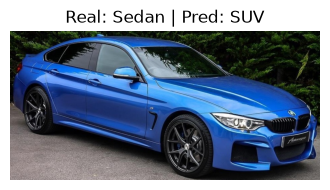

[Sedan] 48_jpg.rf.a5c7fb0cd961f095c022fe41fdab3eb1.jpg → Predicción: SUV


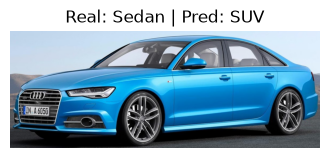

[Sedan] 4_jpg.rf.19f5b4b24bc1501547daef28dbb26683.jpg → Predicción: SUV


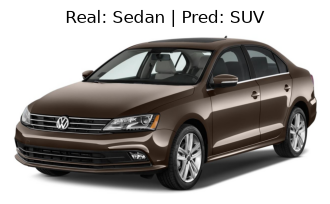

[Sedan] 538_jpg.rf.bfec0034a4bbf231f535d07a04ce2f9e.jpg → Predicción: SUV


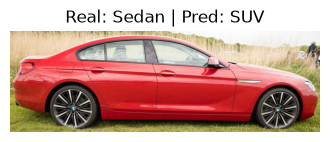

[Sedan] 69_jpg.rf.22e8686799ce62d9c7963ba5c0e6de9c.jpg → Predicción: SUV


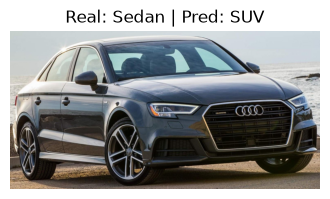

[Sedan] 7_jpg.rf.4d53b770270ca0719adeaa46805af140.jpg → Predicción: SUV


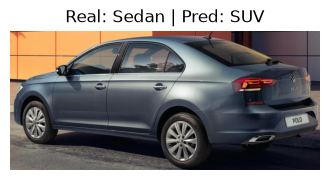

[Sedan] 83_jpg.rf.b2c233a9871e2acf989ff7bc55f4c109.jpg → Predicción: SUV


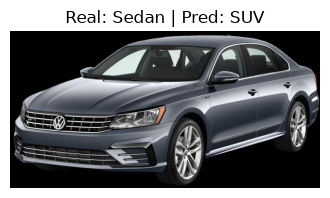

[Sedan] 8678256b-66b6-11eb-88a8-8c164571e025_jpg.rf.0d93553ac7238cfe3551702d0cf51c0d.jpg → Predicción: SUV


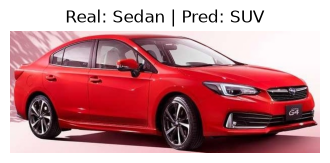

[Sedan] 8678256e-66b6-11eb-b13b-8c164571e025_jpg.rf.263cc23679234619bb16a0390f9ec77f.jpg → Predicción: SUV


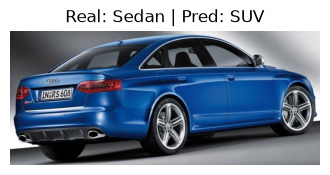

[Sedan] 8678c12f-66b6-11eb-89ea-8c164571e025_jpg.rf.2c29af50a4b25d6153f69abbb8837a88.jpg → Predicción: SUV


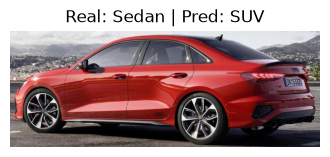

[Sedan] 8678c141-66b6-11eb-831c-8c164571e025_jpg.rf.e586bc07273746cef45c7e34fdc6af7c.jpg → Predicción: SUV


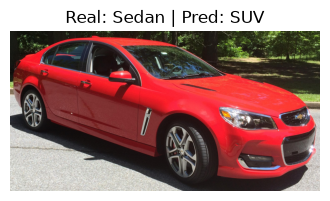

[Sedan] 8678c143-66b6-11eb-bf44-8c164571e025_jpg.rf.c9d5478c73521b7db230ff7b097917be.jpg → Predicción: SUV


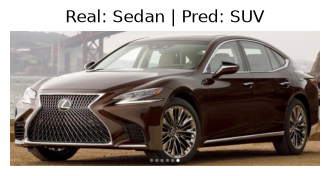

[Sedan] 8678e82e-66b6-11eb-a8a3-8c164571e025_jpg.rf.961a968024f05712f7aea473d80a5f11.jpg → Predicción: SUV


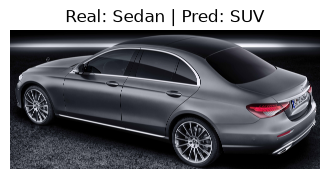

[Sedan] 86790f18-66b6-11eb-a977-8c164571e025_jpg.rf.b2509ee971ca8645e27912f6e5661b8c.jpg → Predicción: SUV


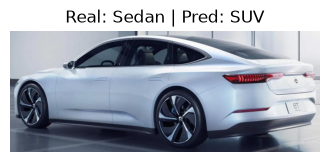

[Sedan] 86790f28-66b6-11eb-9818-8c164571e025_jpg.rf.c68e9a9a3472efc8b70fa60c6d0f5855.jpg → Predicción: SUV


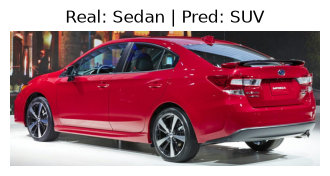

[Sedan] 86795d0a-66b6-11eb-a532-8c164571e025_jpg.rf.f2c4569392e31af7908bfabe23c535d9.jpg → Predicción: SUV


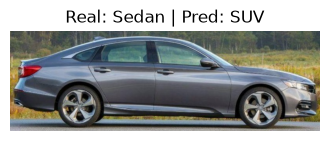

[Sedan] 867983f8-66b6-11eb-a86a-8c164571e025_jpg.rf.ab139fbd8dd0576b540074f81b8267ec.jpg → Predicción: SUV


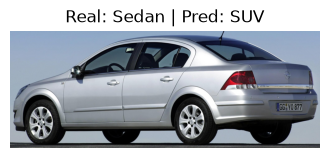

[Sedan] 867983fa-66b6-11eb-9dd5-8c164571e025_jpg.rf.cd52a3838e5153a3f2769b84c6d6bf37.jpg → Predicción: SUV


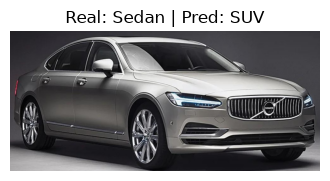

[Sedan] 867983fb-66b6-11eb-a13d-8c164571e025_jpg.rf.e11dfb0416e8ae95dab925fa13bf5d89.jpg → Predicción: SUV


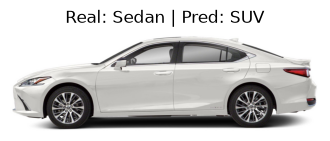

[Sedan] 8679aae8-66b6-11eb-8e28-8c164571e025_jpg.rf.53e097d5325432cbba1b258d73ecaad2.jpg → Predicción: SUV


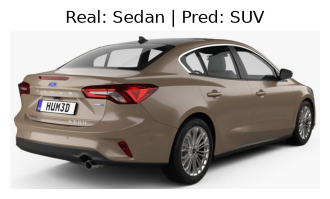

[Sedan] 8679f8e1-66b6-11eb-83f9-8c164571e025_jpg.rf.366fc1c9afce2a5698bf78ff04d5f286.jpg → Predicción: SUV


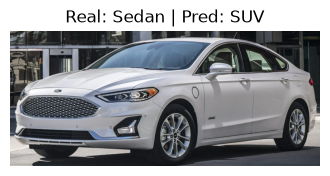

[Sedan] 867a1fce-66b6-11eb-bc11-8c164571e025_jpg.rf.2659c531f5bc07dee9eb873df99d233a.jpg → Predicción: SUV


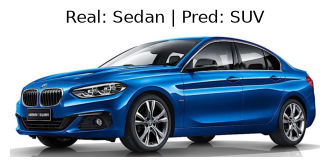

[Sedan] 867a46bd-66b6-11eb-967a-8c164571e025_jpg.rf.938027d4500811afbbba15cf300016a5.jpg → Predicción: SUV


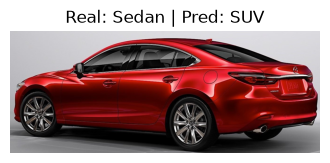

[Sedan] 867a46c9-66b6-11eb-9df8-8c164571e025_jpg.rf.4647140f3460a9d9e88ac0a90c10b269.jpg → Predicción: SUV


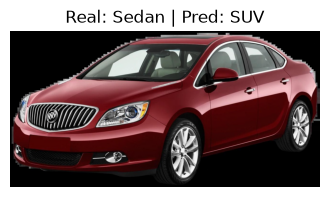

[Sedan] 867a6dbf-66b6-11eb-8bbb-8c164571e025_jpg.rf.46c576c446cd4a45b4e0da0dd0aabc3b.jpg → Predicción: SUV


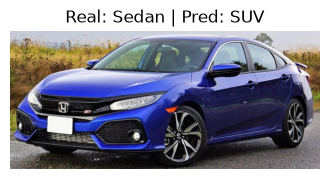

[Sedan] 867a6dc3-66b6-11eb-89d5-8c164571e025_jpg.rf.634a7d0eea02e5dbccfe0249c9492c72.jpg → Predicción: SUV


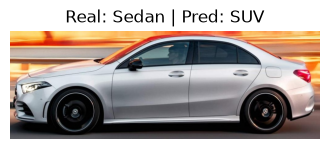

[Sedan] 867a6dd1-66b6-11eb-8987-8c164571e025_jpg.rf.f0a3134304d6832c3ce57940f7411c74.jpg → Predicción: SUV


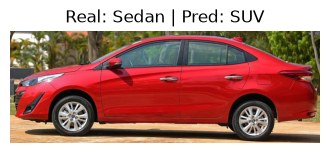

[Sedan] 867a94af-66b6-11eb-b3bd-8c164571e025_jpg.rf.08f34401f990aca0b1424f48317b326c.jpg → Predicción: SUV


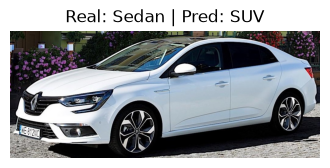

[Sedan] 867abb8f-66b6-11eb-9ccc-8c164571e025_jpg.rf.7575b566e2bed14f51f7f11a29a2e7ae.jpg → Predicción: SUV


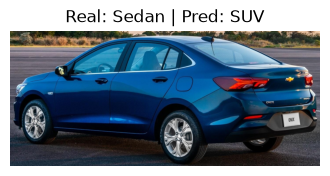

[Sedan] 867b097d-66b6-11eb-bd18-8c164571e025_jpg.rf.97e0df9d8534e8456f3002459343be3e.jpg → Predicción: SUV


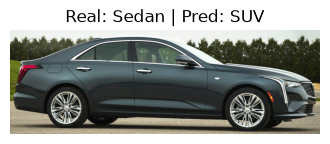

[Sedan] 86_jpg.rf.9d473bccbf8fce7c6ec1eab0c128e6b2.jpg → Predicción: SUV


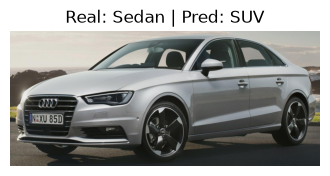

[Sedan] 87_jpg.rf.3f61a225af1fdc9f108f7a29ec0dbd77.jpg → Predicción: SUV


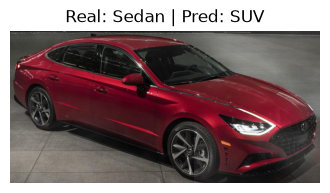

[Sedan] 91_jpg.rf.7b5e54bfbd87f407a8603b648a97cc33.jpg → Predicción: SUV


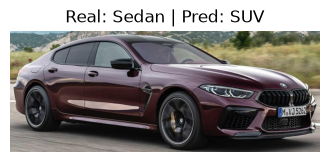

[Sedan] 92_jpg.rf.cd424036195ba8dec8a10ff82b068ad8.jpg → Predicción: SUV


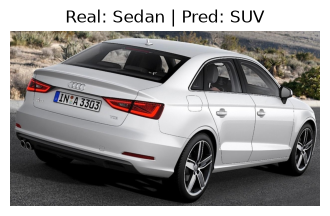

[Sedan] Image_110_jpg.rf.c29ffc6edcaa305d22d67caa698daa13.jpg → Predicción: SUV


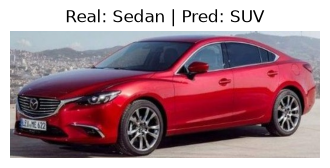

[Sedan] Image_23_jpg.rf.d6aac8697fde7d6ef4b314c18acc8046.jpg → Predicción: SUV


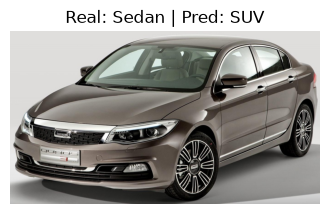

[SUV] 00052_Jeep-Grand-Cherokee-SUV-2012_jpg.rf.6b3708abf89a8ab22604b5c0e9bf0e30.jpg → Predicción: SUV


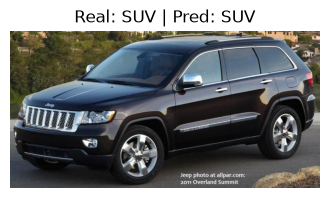

[SUV] 00077_Ford-Edge-SUV-2012_jpg.rf.850daa7251d5299e7f73e92e5ca95c6e.jpg → Predicción: SUV


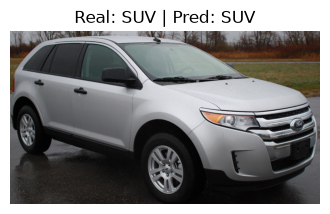

[SUV] 00121_Ford-Expedition-EL-SUV-2009_jpg.rf.565610de07fc2bd3d88eb131ba37938d.jpg → Predicción: SUV


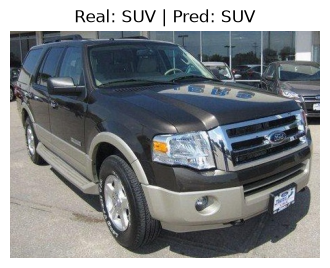

[SUV] 00254_Hyundai-Santa-Fe-SUV-2012_jpg.rf.0cfbf7b0bbbbe6ae83f67f4e53c20038.jpg → Predicción: SUV


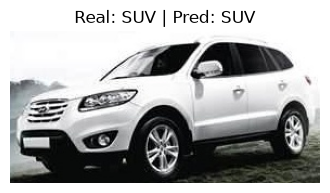

[SUV] 00409_Toyota-4Runner-SUV-2012_jpg.rf.559007d37c351113a72105daebc7a78a.jpg → Predicción: SUV


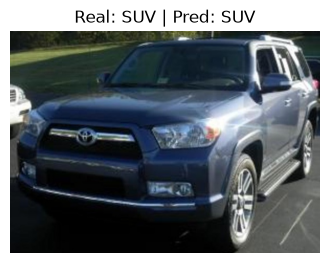

[SUV] 00417_Buick-Enclave-SUV-2012_jpg.rf.5133b5af4558efcb95dc333cca03b1f7.jpg → Predicción: SUV


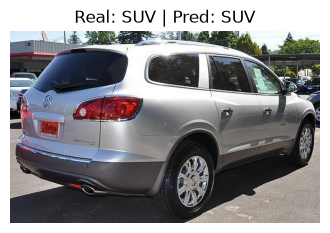

[SUV] 00525_Chrysler-Aspen-SUV-2009_jpg.rf.d3a21e6c57d8227870ad03cb8066a480.jpg → Predicción: SUV


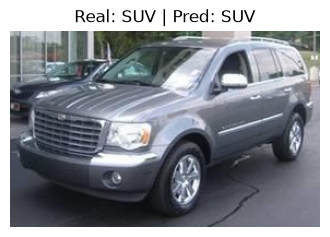

[SUV] 00843_Mazda-Tribute-SUV-2011_jpg.rf.7641d341e63328bfdb10878952bcea52.jpg → Predicción: SUV


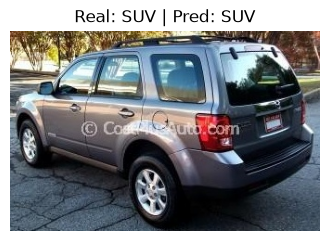

[SUV] 00978_Chevrolet-Tahoe-Hybrid-SUV-2012_jpg.rf.1d87fd25d15ce8d2a7c73cf0aba760fb.jpg → Predicción: SUV


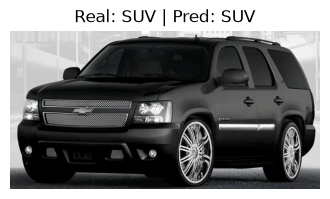

[SUV] 01027_Buick-Enclave-SUV-2012_jpg.rf.97b409e9bb40cd6904c2b2b0402dddee.jpg → Predicción: SUV


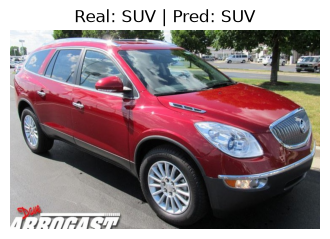

[SUV] 01030_Isuzu-Ascender-SUV-2008_jpg.rf.8f4605293b776f89f4fde37c06ff4dde.jpg → Predicción: SUV


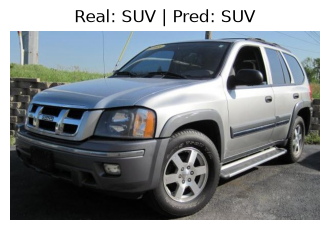

[SUV] 01050_Hyundai-Tucson-SUV-2012_jpg.rf.efc8c378a65a71b17cc75d405d3342f8.jpg → Predicción: SUV


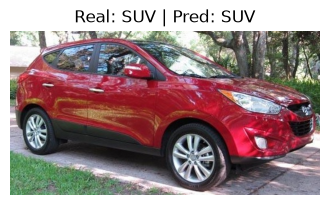

[SUV] 01064_BMW-X3-SUV-2012_jpg.rf.b2e0fdbbdfb7b94012b0be365959ee02.jpg → Predicción: SUV


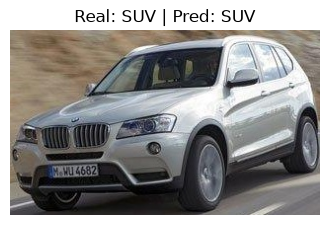

[SUV] 01088_Mazda-Tribute-SUV-2011_jpg.rf.b74527afefa39fa172a7fc227dd98b3f.jpg → Predicción: SUV


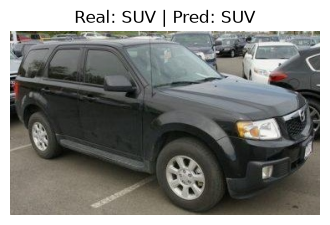

[SUV] 01118_GMC-Terrain-SUV-2012_jpg.rf.7197bf6bb5754dd9364aed4c08d7d85a.jpg → Predicción: SUV


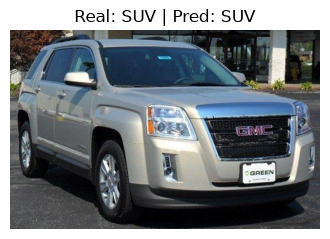

[SUV] 01136_Cadillac-SRX-SUV-2012_jpg.rf.aa46f655681613557c082ab245335016.jpg → Predicción: SUV


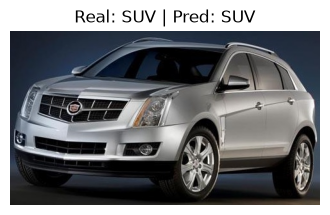

[SUV] 01199_Chevrolet-Tahoe-Hybrid-SUV-2012_jpg.rf.c264dcbd353edca2455fb4c9f33ff1cf.jpg → Predicción: SUV


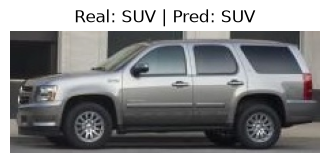

[SUV] 01279_Hyundai-Santa-Fe-SUV-2012_jpg.rf.024ad1a9945e55bb4e80df3779af24d2.jpg → Predicción: SUV


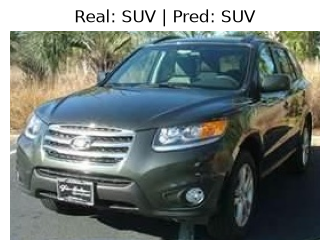

[SUV] 01435_Toyota-4Runner-SUV-2012_jpg.rf.d73a05d29d0d5ed8a2fba218f6ed3bd0.jpg → Predicción: SUV


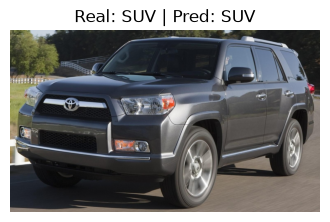

[SUV] 01444_Cadillac-SRX-SUV-2012_jpg.rf.0ec5df7173950320a33080fbe792a1c8.jpg → Predicción: SUV


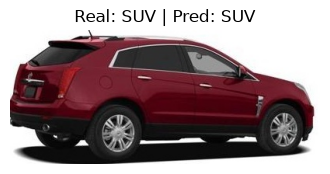

[SUV] 01539_Volvo-XC90-SUV-2007_jpg.rf.e0de08051938e93319a5d6dea3c9c411.jpg → Predicción: SUV


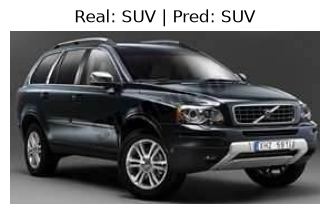

[SUV] 01613_BMW-X5-SUV-2007_jpg.rf.475add750a53ae6da806a4ddad145e7f.jpg → Predicción: SUV


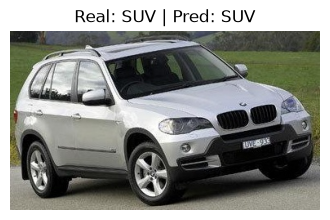

[SUV] 01718_Jeep-Compass-SUV-2012_jpg.rf.cd778d2fbaeb7953cfb9748d8c976787.jpg → Predicción: SUV


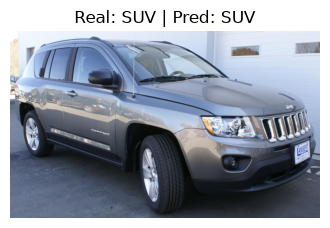

[SUV] 01797_Land-Rover-Range-Rover-SUV-2012_jpg.rf.782b4075f5a2fa3ed1183455b5c51b84.jpg → Predicción: SUV


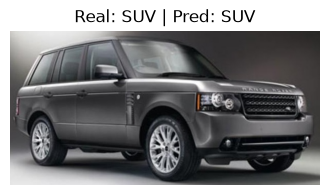

[SUV] 01896_Land-Rover-LR2-SUV-2012_jpg.rf.60b9a9943de29c9b533d17e99a4787e6.jpg → Predicción: SUV


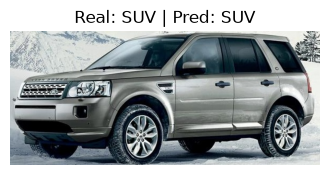

[SUV] 01924_Mazda-Tribute-SUV-2011_jpg.rf.656cf79eb83f003861fc9b7ab9160c6c.jpg → Predicción: SUV


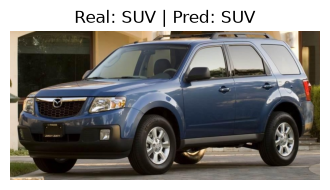

[SUV] 01927_Ford-Expedition-EL-SUV-2009_jpg.rf.8c08d9dbb706bbbce94fc8ca15b6db7b.jpg → Predicción: SUV


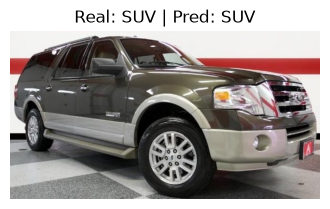

[SUV] 02120_Infiniti-QX56-SUV-2011_jpg.rf.1f8216641e8cca117d17bafaaa0940b0.jpg → Predicción: SUV


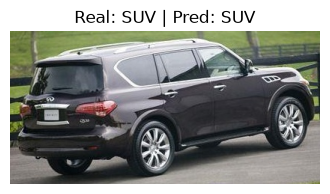

[SUV] 02291_Dodge-Durango-SUV-2012_jpg.rf.5a553ecba7a38471fc6cdc70cf005412.jpg → Predicción: SUV


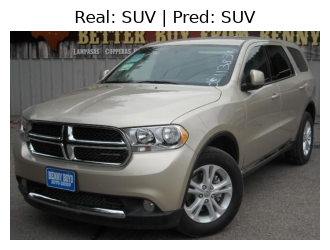

[SUV] 02297_GMC-Yukon-Hybrid-SUV-2012_jpg.rf.655e2babf5b33b5606439f7ce693ccd6.jpg → Predicción: SUV


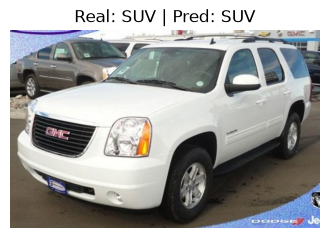

[SUV] 02319_Chevrolet-Tahoe-Hybrid-SUV-2012_jpg.rf.d6f6e9c25adfcf7498a4debabb46db87.jpg → Predicción: SUV


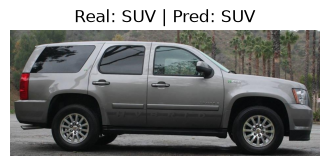

[SUV] 02460_GMC-Terrain-SUV-2012_jpg.rf.1be5f0b2c49e8a78e3118d719503d432.jpg → Predicción: SUV


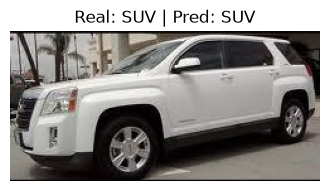

[SUV] 02499_GMC-Terrain-SUV-2012_jpg.rf.d989779f2444b3dc3f353c969987d785.jpg → Predicción: SUV


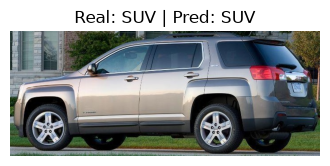

[SUV] 02522_Dodge-Journey-SUV-2012_jpg.rf.4d20d84288a89c8cee5b7f9f279b5e19.jpg → Predicción: SUV


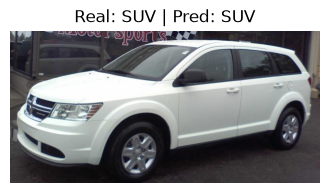

[SUV] 02690_GMC-Yukon-Hybrid-SUV-2012_jpg.rf.9c65185d0055e6eb6ba7bfd984fd30f9.jpg → Predicción: SUV


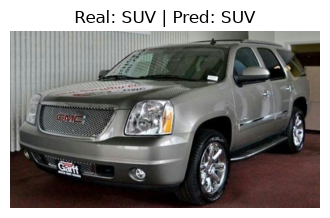

[SUV] 02795_Chevrolet-Traverse-SUV-2012_jpg.rf.4d6da68ac59e11492709a1c6a263c1d8.jpg → Predicción: SUV


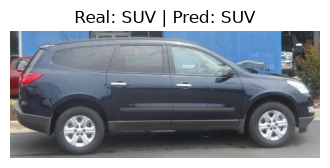

[SUV] 02963_Dodge-Journey-SUV-2012_jpg.rf.7604effcb23f08cb1c090c17b3c77c0a.jpg → Predicción: SUV


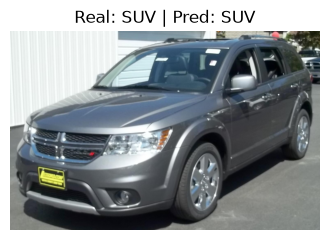

[SUV] 03017_Dodge-Durango-SUV-2007_jpg.rf.98816efbcc611301bbf8b6579f215110.jpg → Predicción: SUV


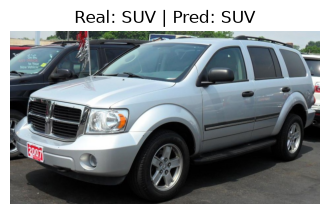

[SUV] 03093_Land-Rover-Range-Rover-SUV-2012_jpg.rf.1a176b4aadc0fbd444923c0f7cc8e26d.jpg → Predicción: SUV


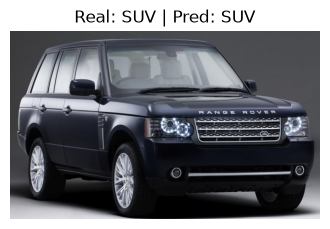

[SUV] 03126_Infiniti-QX56-SUV-2011_jpg.rf.0256dfebc0435683b68892b72c536f47.jpg → Predicción: SUV


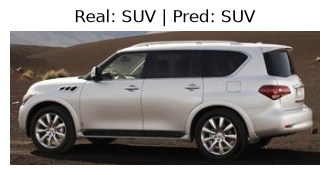

[SUV] 03260_Hyundai-Veracruz-SUV-2012_jpg.rf.305f09938fcb103c5471c95033abf294.jpg → Predicción: SUV


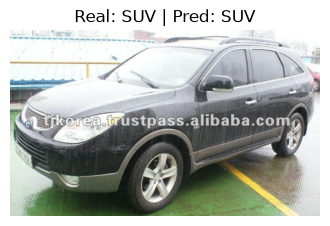

[SUV] 03275_Isuzu-Ascender-SUV-2008_jpg.rf.6606ac71074067870afc7efc230fc366.jpg → Predicción: SUV


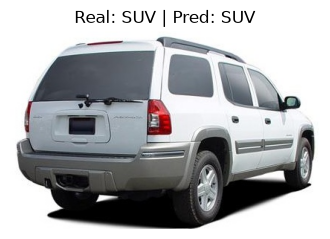

[SUV] 03385_Toyota-Sequoia-SUV-2012_jpg.rf.c5aec3eda6021e67d97fd562be33a37a.jpg → Predicción: SUV


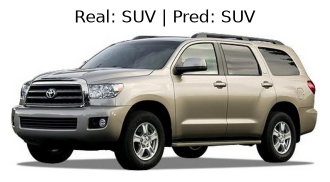

[SUV] 03617_BMW-X5-SUV-2007_jpg.rf.93f9ee9e00f88ed2f955d611d912a41a.jpg → Predicción: SUV


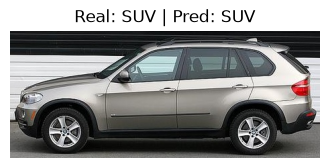

[SUV] 03630_Dodge-Journey-SUV-2012_jpg.rf.8989128dd20faa9d19c58e8be34f507b.jpg → Predicción: SUV


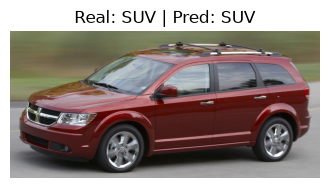

[SUV] 03648_Jeep-Compass-SUV-2012_jpg.rf.98e10d66cc0a82f8024c70a69415605f.jpg → Predicción: SUV


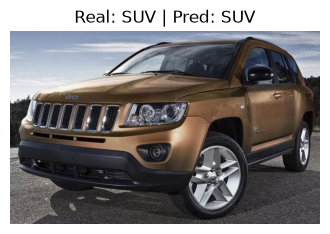

[SUV] 03731_Isuzu-Ascender-SUV-2008_jpg.rf.05e57278db227184f60a8e4e3d6697a3.jpg → Predicción: SUV


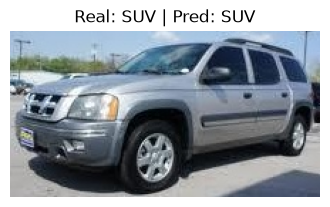

[SUV] 03837_Dodge-Journey-SUV-2012_jpg.rf.7524ece4819b9b98e7185a10749bbf1b.jpg → Predicción: SUV


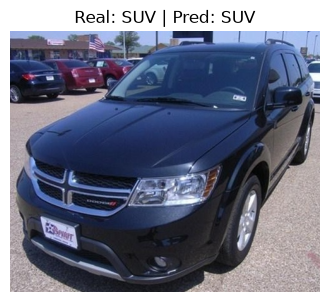

[SUV] 03916_Toyota-Sequoia-SUV-2012_jpg.rf.32d8e6872ee7677b7f27ac97c090c95a.jpg → Predicción: SUV


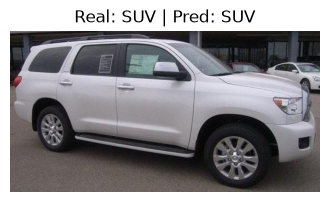

[SUV] 03923_Buick-Rainier-SUV-2007_jpg.rf.14eca4025eb025c9c55732ebc25f15be.jpg → Predicción: SUV


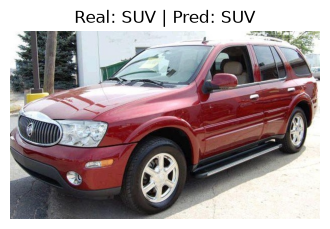

[SUV] 03935_BMW-X5-SUV-2007_jpg.rf.41d82581b31e9c2f7b6de2338e310c7c.jpg → Predicción: SUV


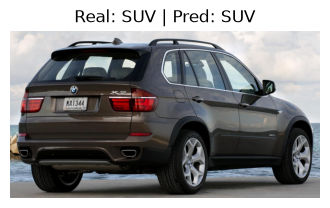

[SUV] 03967_GMC-Terrain-SUV-2012_jpg.rf.0b5e9e90d58ae31f7d01839deb34e1e9.jpg → Predicción: SUV


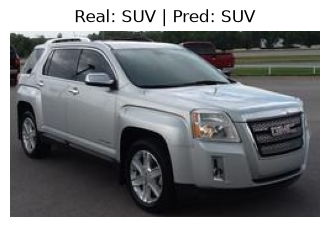

[SUV] 04466_Isuzu-Ascender-SUV-2008_jpg.rf.f48befcc3f105c717c89b8e857c029cd.jpg → Predicción: SUV


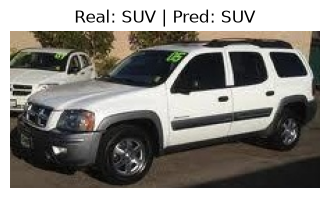

[SUV] 04499_Hyundai-Tucson-SUV-2012_jpg.rf.d723a47a0485ad2c2f74ac70db2df222.jpg → Predicción: SUV


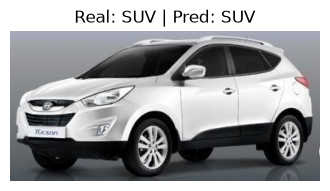

[SUV] 04763_Jeep-Liberty-SUV-2012_jpg.rf.9a8bd10b43598d0e347ee80b04bf47fb.jpg → Predicción: SUV


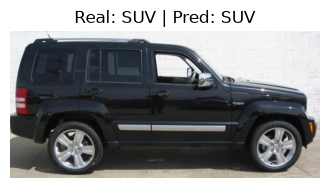

[SUV] 04919_Dodge-Journey-SUV-2012_jpg.rf.9aa21040922330a80b17b1c3559b5f16.jpg → Predicción: SUV


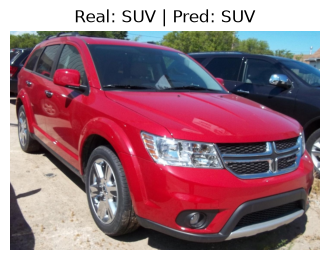

[SUV] 04947_Ford-Edge-SUV-2012_jpg.rf.6c1b3285ba356951dcba52c46fc404ca.jpg → Predicción: SUV


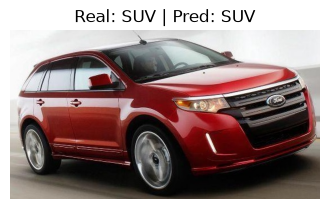

[SUV] 05071_Cadillac-SRX-SUV-2012_jpg.rf.8230d4fd2b82ba7777485d1a3f8dccc2.jpg → Predicción: SUV


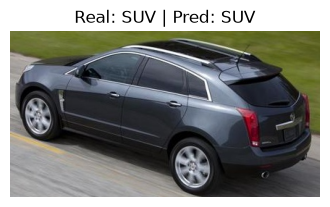

[SUV] 05124_Buick-Enclave-SUV-2012_jpg.rf.b47143d918d7136820ffb6a96d140800.jpg → Predicción: SUV


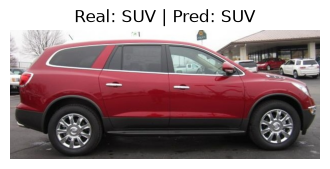

[SUV] 05132_BMW-X5-SUV-2007_jpg.rf.d7a8626e7a2f5dd5e5dbaded28a703f4.jpg → Predicción: SUV


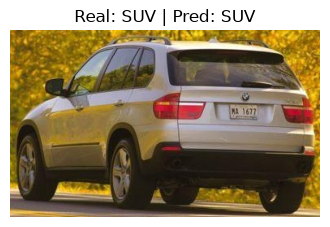

[SUV] 05171_Volvo-XC90-SUV-2007_jpg.rf.4b856099404b296dca00a682cc7fb276.jpg → Predicción: SUV


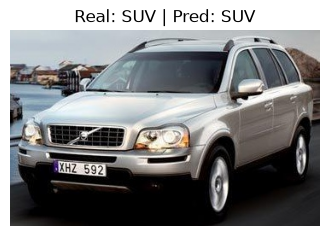

[SUV] 05279_Infiniti-QX56-SUV-2011_jpg.rf.b83ac65afe8d9603797fa0aa641b30a7.jpg → Predicción: SUV


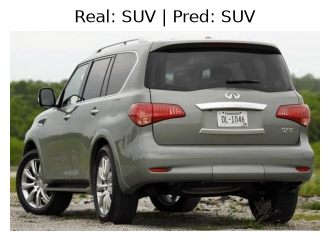

[SUV] 05291_Dodge-Journey-SUV-2012_jpg.rf.08d6b8c75dcf07a35c2805f8e08ae853.jpg → Predicción: SUV


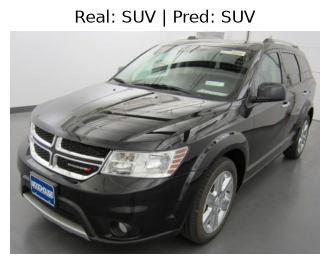

[SUV] 05358_GMC-Yukon-Hybrid-SUV-2012_jpg.rf.81fae73e55479fb4a191d503a20fa96b.jpg → Predicción: SUV


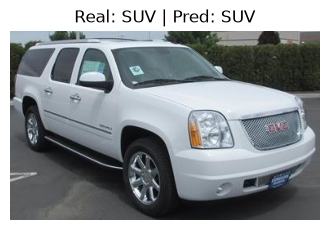

[SUV] 05484_Toyota-4Runner-SUV-2012_jpg.rf.726ab5e85025ca32fc234b96be1aaa43.jpg → Predicción: SUV


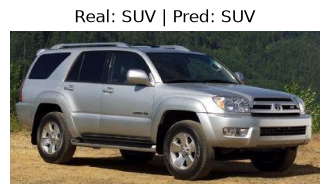

[SUV] 05544_Chrysler-Aspen-SUV-2009_jpg.rf.c72f3c3860b71116c056488d1e878e6c.jpg → Predicción: SUV


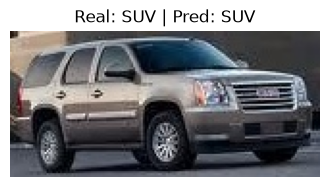

[SUV] 05784_Dodge-Journey-SUV-2012_jpg.rf.650ceea0169ac7dc641292e5c01866b7.jpg → Predicción: SUV


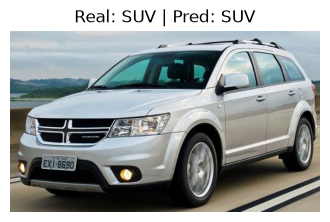

[SUV] 05796_Land-Rover-LR2-SUV-2012_jpg.rf.d0ee291f1fbf3fd9faa36639fa5518f5.jpg → Predicción: SUV


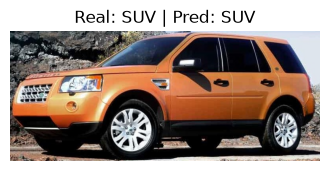

[SUV] 05847_Dodge-Durango-SUV-2012_jpg.rf.6ee53fa90dd957865f13bbbc3cf80ba3.jpg → Predicción: SUV


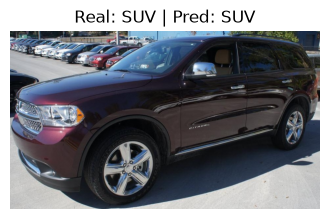

[SUV] 05880_Land-Rover-LR2-SUV-2012_jpg.rf.e6f89d022a2d1da7c875e457273c71bc.jpg → Predicción: SUV


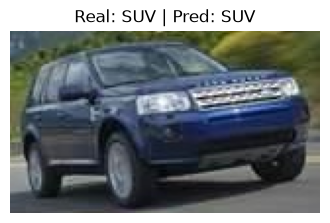

[SUV] 05881_Cadillac-SRX-SUV-2012_jpg.rf.c3afff9e787b1ed075bd4ec30b8ca047.jpg → Predicción: SUV


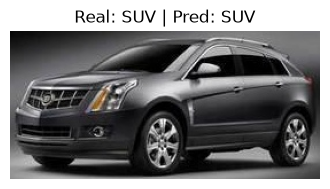

[SUV] 06027_BMW-X5-SUV-2007_jpg.rf.6901528deb86bef10c8c11db1476ffce.jpg → Predicción: SUV


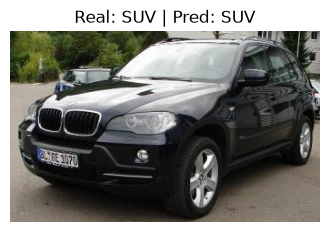

[SUV] 06100_Jeep-Grand-Cherokee-SUV-2012_jpg.rf.b65b49c7ad2d2950ecf27b7d57ed05dc.jpg → Predicción: SUV


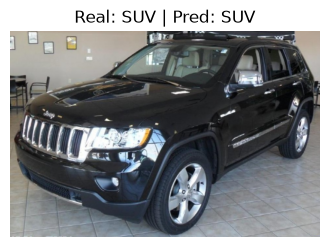

[SUV] 06192_Hyundai-Veracruz-SUV-2012_jpg.rf.65691eb772caf03747eb3e13e7a0ebc1.jpg → Predicción: SUV


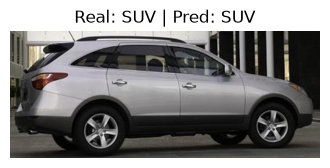

[SUV] 06278_BMW-X3-SUV-2012_jpg.rf.3411bc6a56a29e8809b7a2c9197b0c83.jpg → Predicción: SUV


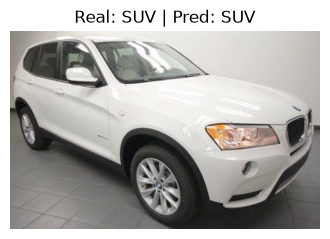

[SUV] 06319_Dodge-Durango-SUV-2007_jpg.rf.f2fabeb187b4fec7e65a4b02cf5dc040.jpg → Predicción: SUV


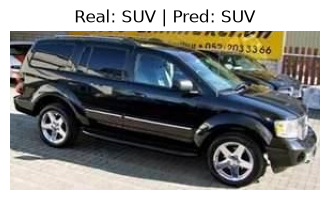

[SUV] 06390_Toyota-4Runner-SUV-2012_jpg.rf.4cee440a71ff5d3c7b028892824bc194.jpg → Predicción: SUV


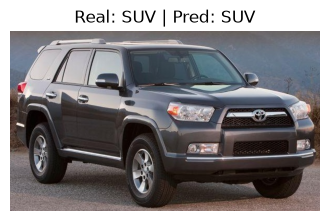

[SUV] 06471_Volvo-XC90-SUV-2007_jpg.rf.f1a4eca26854acc892df067e839e3cc7.jpg → Predicción: SUV


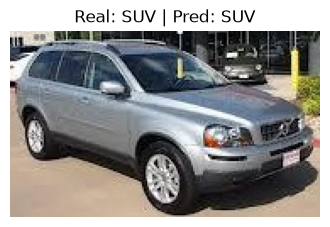

[SUV] 06590_Chrysler-Aspen-SUV-2009_jpg.rf.e4aace7181471e91864232b8f47b1603.jpg → Predicción: SUV


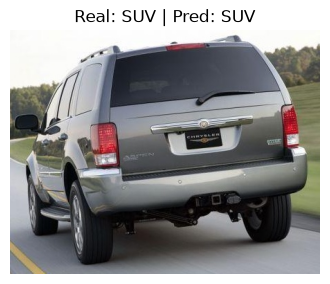

[SUV] 06662_BMW-X5-SUV-2007_jpg.rf.d586f58c4f960dca3f676bcfdee5f4ee.jpg → Predicción: SUV


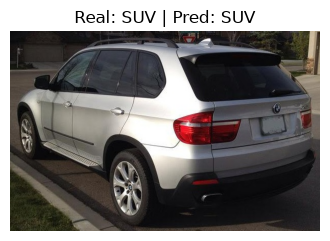

[SUV] 06736_Jeep-Grand-Cherokee-SUV-2012_jpg.rf.0b6fc3daf5ab8ca2ccdfb8569942476b.jpg → Predicción: SUV


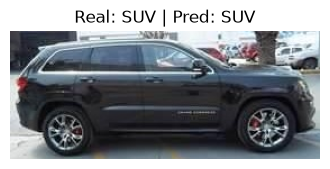

[SUV] 06884_Land-Rover-LR2-SUV-2012_jpg.rf.89e016ec8c32af3f7721b40bc2a3e717.jpg → Predicción: SUV


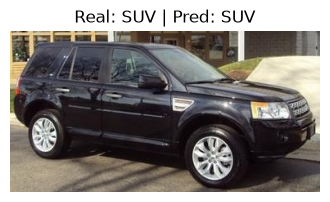

[SUV] 06899_Jeep-Grand-Cherokee-SUV-2012_jpg.rf.c14ab91688f40f83adb06fb3e5e0ac7b.jpg → Predicción: SUV


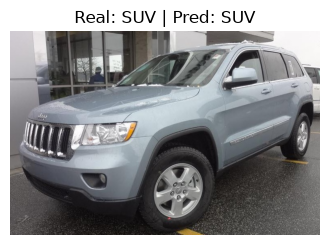

[SUV] 06929_Ford-Edge-SUV-2012_jpg.rf.daba0a505c88d68d88ff41758297bbd2.jpg → Predicción: SUV


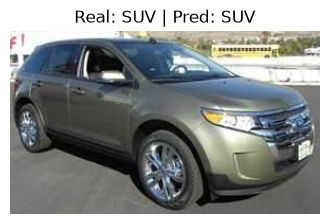

[SUV] 06933_Jeep-Patriot-SUV-2012_jpg.rf.9dff577c35983b3c84d4d37f8d8adeda.jpg → Predicción: SUV


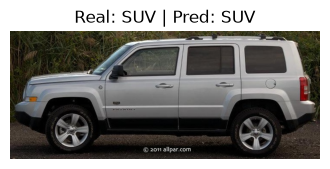

[SUV] 06955_Infiniti-QX56-SUV-2011_jpg.rf.71ab6027c1a4253759d029e868573af6.jpg → Predicción: SUV


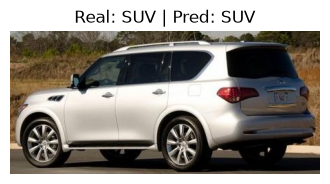

[SUV] 07134_BMW-X5-SUV-2007_jpg.rf.f4ada1e68febb83a104323759bfcb698.jpg → Predicción: SUV


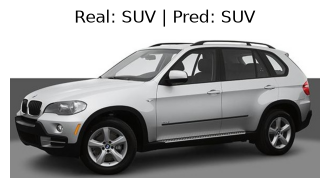

[SUV] 07145_Jeep-Compass-SUV-2012_jpg.rf.dc7671b0b9d33788fa33acde94dc1eea.jpg → Predicción: SUV


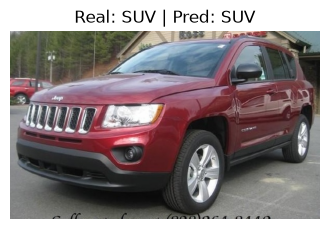

[SUV] 07179_Hyundai-Veracruz-SUV-2012_jpg.rf.70a7f6d3d2040501a3af7da440be8eec.jpg → Predicción: SUV


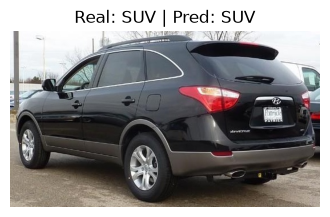

[SUV] 07266_GMC-Acadia-SUV-2012_jpg.rf.045fe4afbccf3af344553894c4fb9cf9.jpg → Predicción: SUV


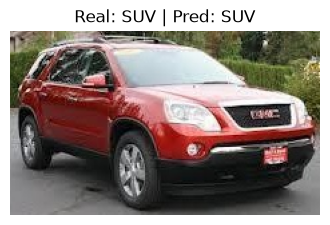

[SUV] 07554_Chrysler-Aspen-SUV-2009_jpg.rf.0dee5f83bfbbfddc28ce664c94b269e8.jpg → Predicción: SUV


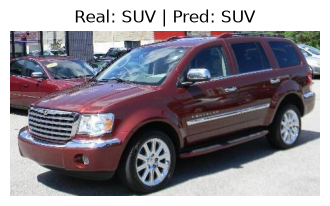

[SUV] 07585_Buick-Enclave-SUV-2012_jpg.rf.960b629900e88574b82fb6f94c33f8fb.jpg → Predicción: SUV


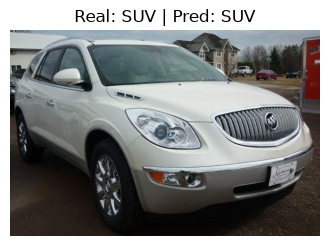

[SUV] 07595_Infiniti-QX56-SUV-2011_jpg.rf.e0f1337ace39f00cd81a10da915e490c.jpg → Predicción: SUV


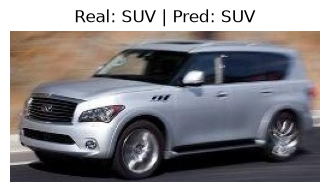

[SUV] 07997_Infiniti-QX56-SUV-2011_jpg.rf.9075edbd8d5a026ba1572b85fe286bd2.jpg → Predicción: SUV


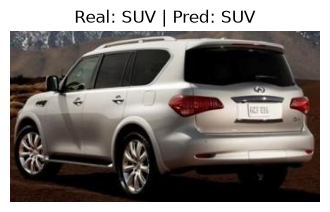

[SUV] 106_jpg.rf.3f876f0d95b54823eed10e9a5cc81a81.jpg → Predicción: SUV


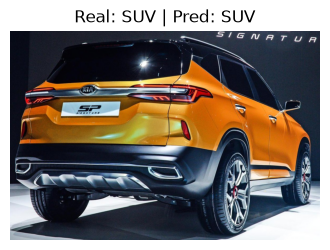

[SUV] 111_jpg.rf.82fe73ad502cca4909af19ebddd66e93.jpg → Predicción: SUV


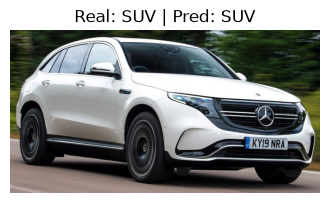

[SUV] 153_jpg.rf.b8ff38656b9b7906aeb71530831d8b07.jpg → Predicción: SUV


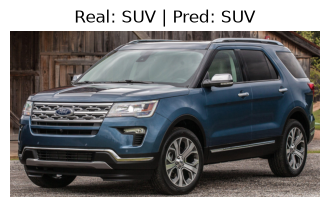

[SUV] 156_jpg.rf.b0411704494e65a1e50aedc142a15078.jpg → Predicción: SUV


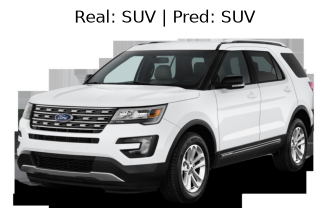

[SUV] 161_jpg.rf.af01205d2e47cdef215ef24b4fe6fc21.jpg → Predicción: SUV


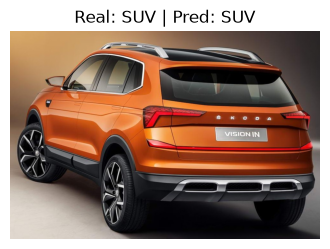

[SUV] 166_jpg.rf.efa3518ca3e50562108ee03a123d499e.jpg → Predicción: SUV


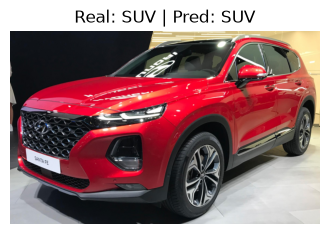

[SUV] 21_jpg.rf.e1647e763286259ed790e93695cb5125.jpg → Predicción: SUV


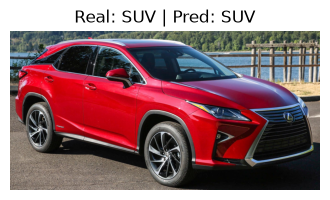

[SUV] 221_jpg.rf.db0bd180ea54713b7df1be1524a86955.jpg → Predicción: SUV


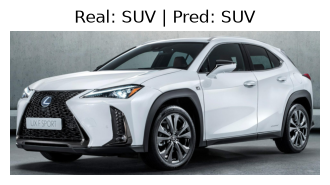

[SUV] 234_jpg.rf.f284506ec281b32532bf7d4623954db5.jpg → Predicción: SUV


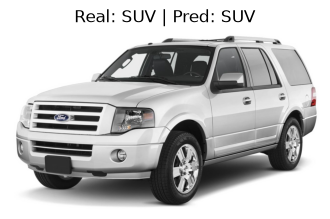

[SUV] 24_jpg.rf.49bbb634d8c10331c7ed2015dc4505ce.jpg → Predicción: SUV


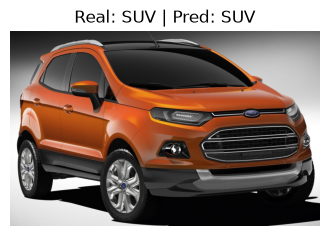

[SUV] 266_jpg.rf.0399e09b1488c5b306b08bcadc407f09.jpg → Predicción: SUV


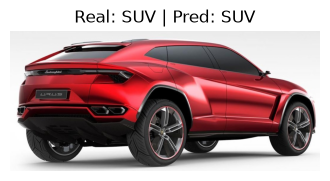

[SUV] 328_jpg.rf.392100df4ba953954ee343973cbfa00a.jpg → Predicción: SUV


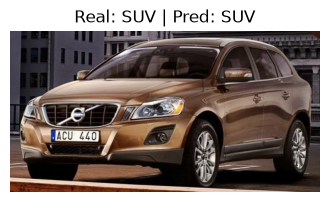

[SUV] 332_jpg.rf.253f1ffd3745f0b29d06308d3b433bca.jpg → Predicción: SUV


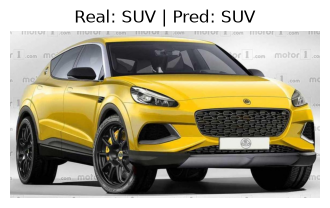

[SUV] 33_jpg.rf.5c8cf13f5e721d376fb978b6968e883b.jpg → Predicción: SUV


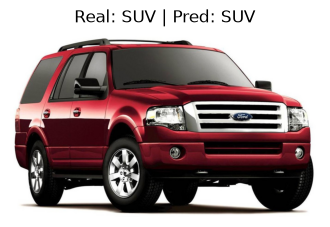

[SUV] 349_jpg.rf.401a8d6b4d2e5921f85e4c0fb64807ac.jpg → Predicción: SUV


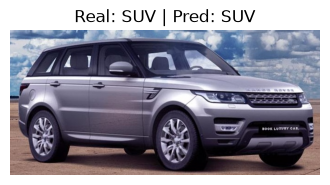

[SUV] 359_jpg.rf.925127e09cbc861044b0988e1c64a28c.jpg → Predicción: SUV


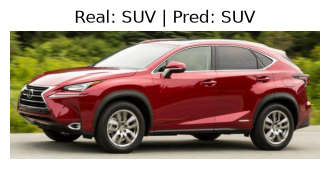

[SUV] 377_jpg.rf.4d00ae50c9ee18dc3982618a6dfb5e9e.jpg → Predicción: SUV


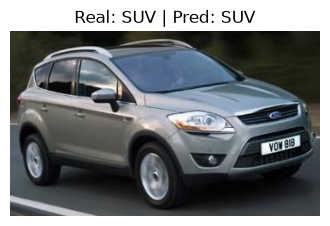

[SUV] 416_jpg.rf.e47dcb9b730adfb2510d2f35099b8cdb.jpg → Predicción: SUV


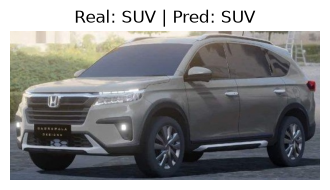

[SUV] 43_jpg.rf.b1118343018c2eda2a7d4324b9471268.jpg → Predicción: SUV


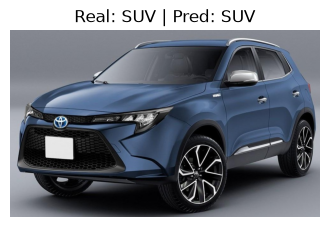

[SUV] 508_jpg.rf.723939e1439d03d3e5aa652e8e99c9df.jpg → Predicción: SUV


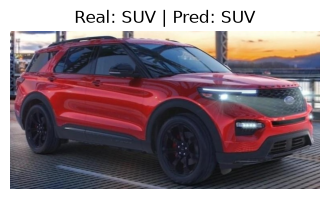

[SUV] 56_jpg.rf.047af8da56c1f75393f8e886e8fbe212.jpg → Predicción: SUV


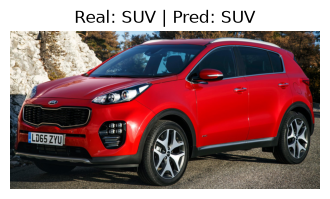

[SUV] 65_jpg.rf.b4577bea19b43effffbae2875b3552d4.jpg → Predicción: SUV


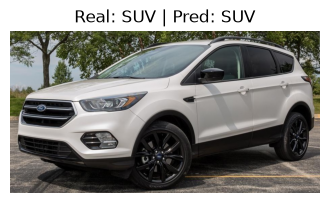

[SUV] 68_jpg.rf.fc402271a7691314254fa3b3f2961c7c.jpg → Predicción: SUV


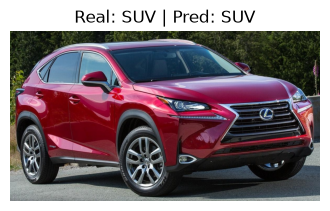

[SUV] 6_jpg.rf.4adfac39cf77f6e463f3325bb197c0fd.jpg → Predicción: SUV


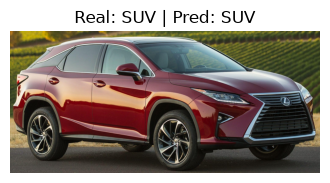

[SUV] 72_jpg.rf.464cece3e1f6d98a55f1b73d3a786a65.jpg → Predicción: SUV


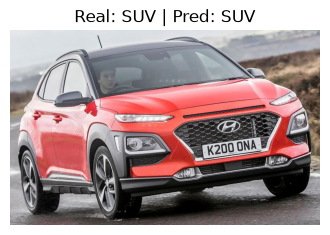

[SUV] 94_jpg.rf.7bceabf61a7a7a5961af68b7c58c5446.jpg → Predicción: SUV


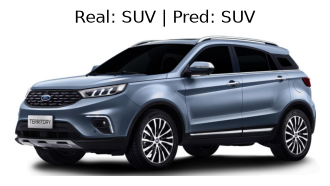

[SUV] Image_114_jpg.rf.ec5911f10409e8c61222981422479249.jpg → Predicción: SUV


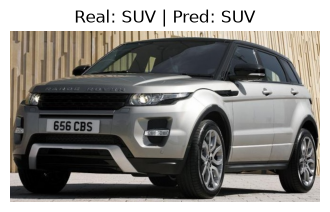

[SUV] Image_55_jpg.rf.c6c2d9dc8da8dd348038a67d14ae2255.jpg → Predicción: SUV


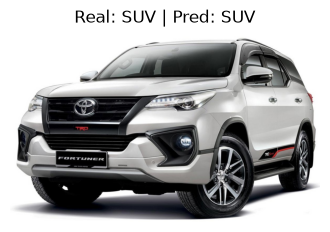

[SUV] Image_86_jpg.rf.080f77c37cb03a003c35ae2dd8257523.jpg → Predicción: SUV


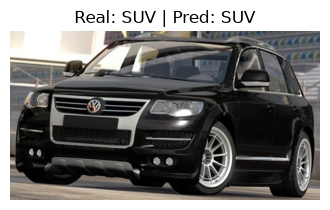

[SUV] Image_96_jpg.rf.13a910fc813a34848178728eb77e2284.jpg → Predicción: SUV


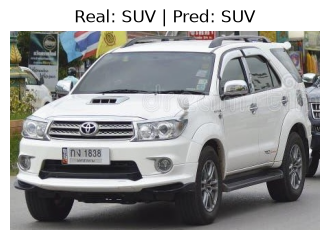

[SUV] SUV_1005_09062020_145840_jpg.rf.a517e93fc0bb91f6f1bfac1e5ec91415.jpg → Predicción: SUV


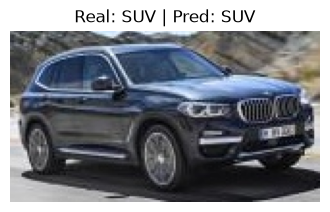

[VAN] 00804_Mercedes-Benz-Sprinter-Van-2012_jpg.rf.239006116b69d6c5c2cff5802c8e2fe5.jpg → Predicción: SUV


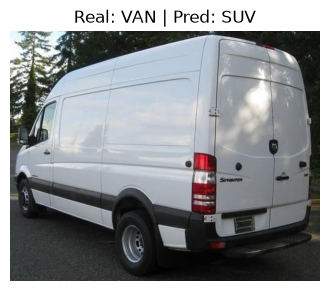

[VAN] 02564_Chevrolet-Express-Van-2007_jpg.rf.62f67a0abb667c0da8734d53f32a1f36.jpg → Predicción: SUV


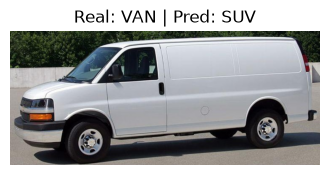

[VAN] 02658_Chevrolet-Express-Cargo-Van-2007_jpg.rf.989a9cf3b8a31e9215407bceaca8ebd2.jpg → Predicción: SUV


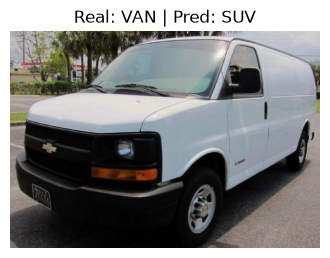

[VAN] 03521_Mercedes-Benz-Sprinter-Van-2012_jpg.rf.469e48fb709014869348c62c6f24fd2f.jpg → Predicción: SUV


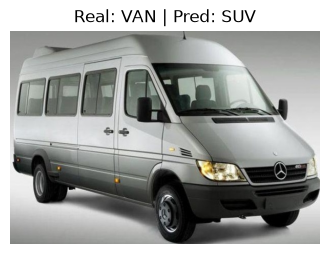

[VAN] 04214_GMC-Savana-Van-2012_jpg.rf.f8c57790bb1d9ef9c649eb13dcf0124b.jpg → Predicción: SUV


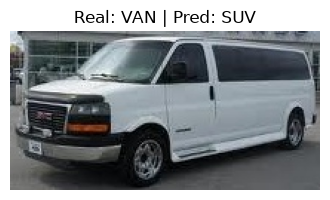

[VAN] 04483_GMC-Savana-Van-2012_jpg.rf.e586bee637f909cafecb3f57a7937e73.jpg → Predicción: SUV


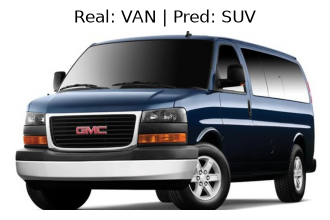

[VAN] 04647_GMC-Savana-Van-2012_jpg.rf.f269f0680bd7a98bd56ce8e68473ec16.jpg → Predicción: SUV


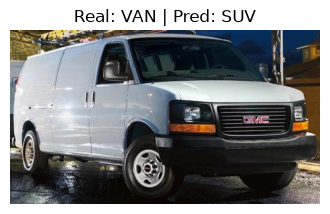

[VAN] 04734_Nissan-NV-Passenger-Van-2012_jpg.rf.b5812a68bb8df1889bf801c3e33d536a.jpg → Predicción: SUV


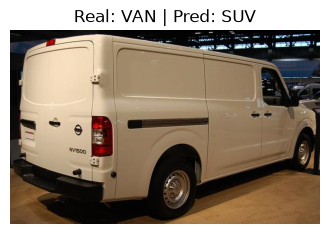

[VAN] 06150_Nissan-NV-Passenger-Van-2012_jpg.rf.5db21b21a1ebe9ea8e532613b12af64c.jpg → Predicción: SUV


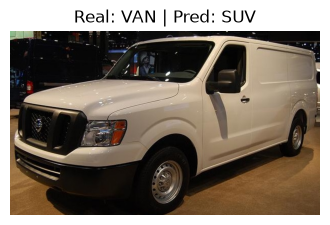

[VAN] 07246_Nissan-NV-Passenger-Van-2012_jpg.rf.d440c0371d3abe6fd3f566a69dbda5d5.jpg → Predicción: SUV


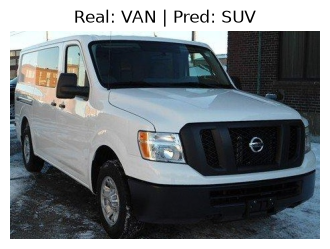

[VAN] 08131_GMC-Savana-Van-2012_jpg.rf.a776cb1c620eae1c898d60b55e311b4f.jpg → Predicción: SUV


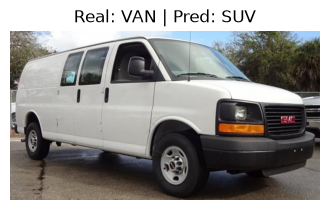

[VAN] 120_jpg.rf.5c8b4c5d82749c8777d31dfbcc9e1569.jpg → Predicción: SUV


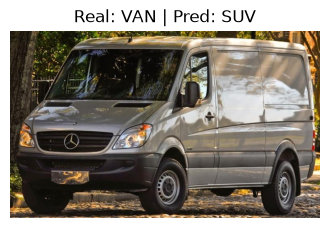

[VAN] 121_jpg.rf.66f2627045929e12e101e5b3fb59d05f.jpg → Predicción: SUV


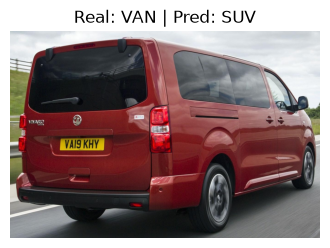

[VAN] 135_jpg.rf.5e0554d81bc2747810cf352dc82bd0aa.jpg → Predicción: SUV


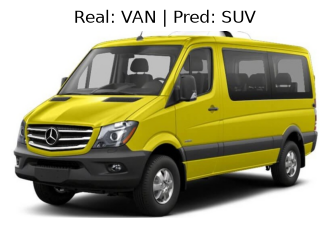

[VAN] 188_jpg.rf.ef498b0bf885efdf19f16e7e67a1f47e.jpg → Predicción: SUV


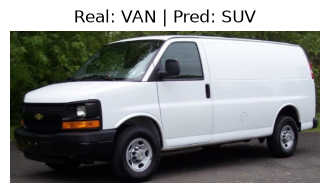

[VAN] 19_jpg.rf.b3a8842099e96c7aee3b5fb614dfaa06.jpg → Predicción: SUV


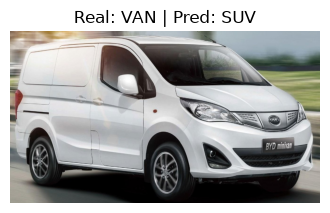

[VAN] 201904056670273_jpg.rf.25afe654444333ee61b461f6378843aa.jpg → Predicción: SUV


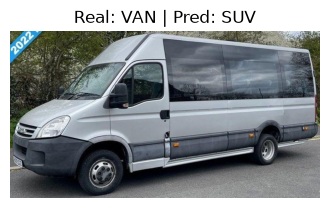

[VAN] 202012106968212_jpg.rf.a4217b172a25766b131aac74bc4dce60.jpg → Predicción: SUV


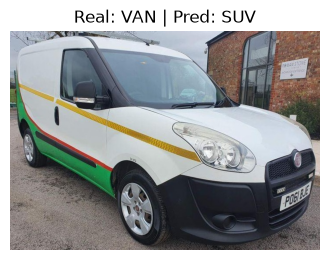

[VAN] 202012127026657_jpg.rf.756fe2d147f6aa5ba2de2c25a3d81883.jpg → Predicción: SUV


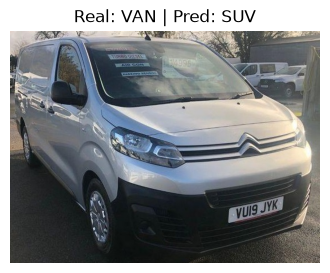

[VAN] 202101057666790_jpg.rf.1b1323a89b91c0555fe9c38d296e5512.jpg → Predicción: SUV


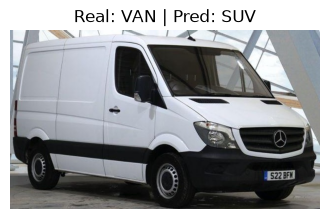

[VAN] 202101137934547_jpg.rf.eda6c133feb46b8b59dd74fff9b33fe9.jpg → Predicción: SUV


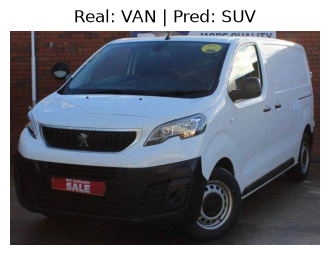

[VAN] 202101208155049_jpg.rf.75cbbee35213b11b4306a0d8d99f4036.jpg → Predicción: SUV


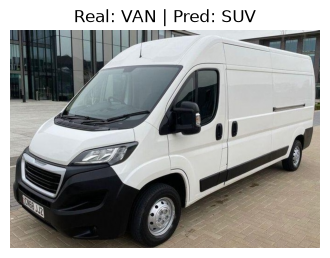

[VAN] 202102038656932_jpg.rf.0bf8eca93daf2cc64cec3266bbf35297.jpg → Predicción: SUV


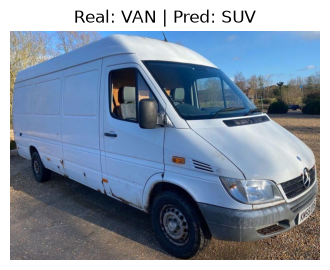

[VAN] 202102088843517_jpg.rf.e6ab832d78a44a5b77a50eb77d19b07b.jpg → Predicción: SUV


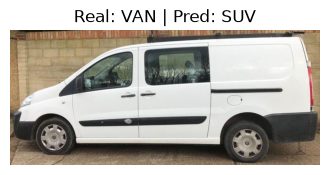

[VAN] 202102159095620_jpg.rf.8319d07dace05b9b8357462ae963bd41.jpg → Predicción: SUV


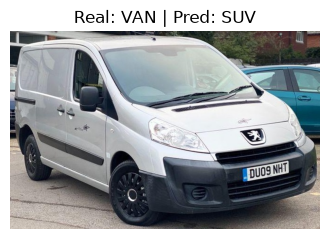

[VAN] 202102269495290_jpg.rf.d8187f600d0e692ded1601b11f79e516.jpg → Predicción: SUV


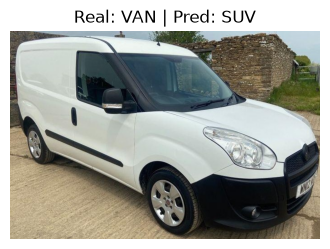

[VAN] 202103029664074_jpg.rf.7ce7d5e480b22654a829f83e5fe0714a.jpg → Predicción: SUV


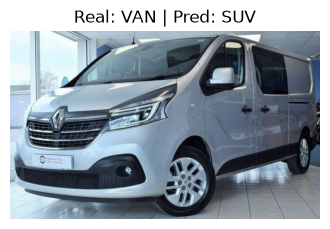

[VAN] 202103039680954_jpg.rf.5841904e7b0291b670cda350e9af6b54.jpg → Predicción: SUV


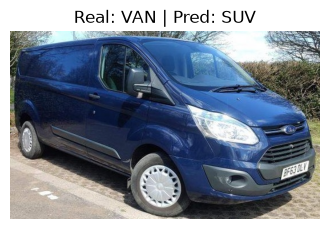

[VAN] 202103099922234_jpg.rf.25450ca9f34b388164be8a4dc9b09a8c.jpg → Predicción: SUV


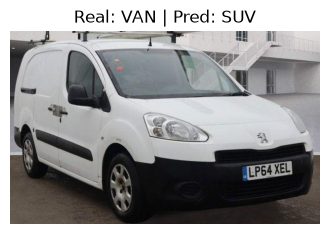

[VAN] 202103099942172_jpg.rf.8f2e1c9759ca77ec6896a0a424e1aa45.jpg → Predicción: SUV


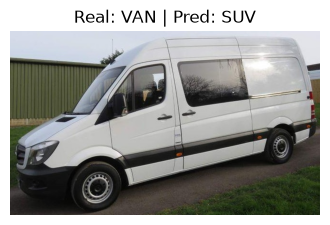

[VAN] 202103099950513_jpg.rf.5144857837cd3b6392b0c8b5ba5ea95f.jpg → Predicción: SUV


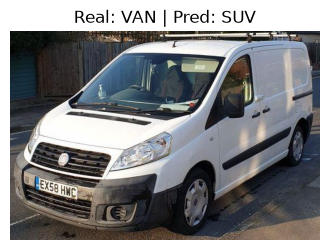

[VAN] 202103109981546_jpg.rf.419543415021758d1e41d375555ff593.jpg → Predicción: SUV


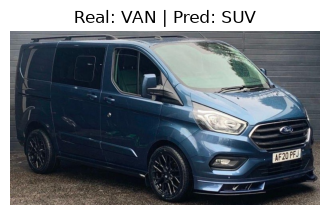

[VAN] 202103130087617_jpg.rf.0784dd9099e98dd112f91be225927a73.jpg → Predicción: SUV


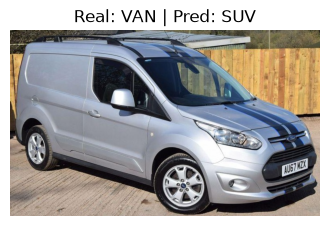

[VAN] 202103130090496_jpg.rf.6d6a0cebb2289cefa9c9df0e87878802.jpg → Predicción: SUV


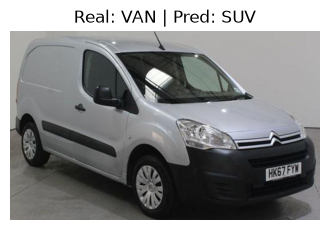

[VAN] 202103130097706_jpg.rf.6c455b8d99665cd3abf8db59526380c6.jpg → Predicción: SUV


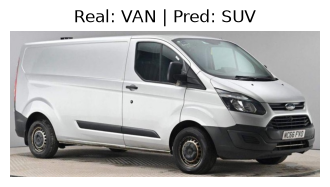

[VAN] 202103170241444_jpg.rf.34349f8352836893c586aaa639508d6c.jpg → Predicción: SUV


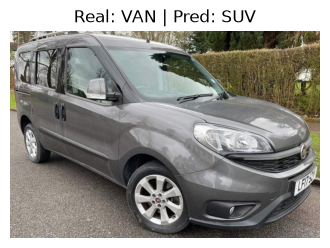

[VAN] 202103180301242_jpg.rf.ad21a5d4a7197a1a701538a26c5c5551.jpg → Predicción: SUV


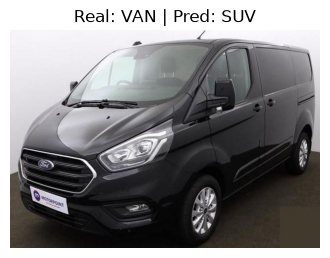

[VAN] 202103190325219_jpg.rf.9d4acfcd3a88bb931b66d57d4e8ca5cf.jpg → Predicción: SUV


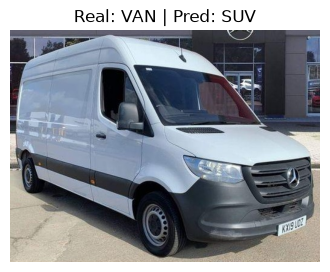

[VAN] 202103240542574_jpg.rf.f04ba8bdb3035ad002247a85b0a6f63b.jpg → Predicción: SUV


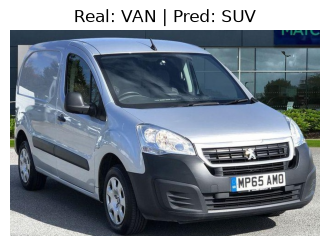

[VAN] 202103240546455_jpg.rf.0c6122241c148bd2cf1fe3fc9147f8cd.jpg → Predicción: SUV


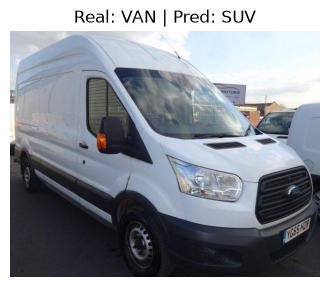

[VAN] 202103240550617_jpg.rf.4820dc93e07875c2780fe2847c84729f.jpg → Predicción: SUV


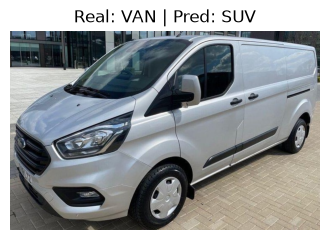

[VAN] 202103300754782_jpg.rf.2e38918e4be43496261d6af3809809c7.jpg → Predicción: SUV


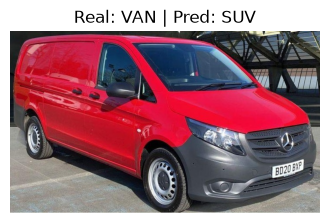

[VAN] 202103300758911_jpg.rf.3593f5879f118482ab80a9b4172aa31d.jpg → Predicción: SUV


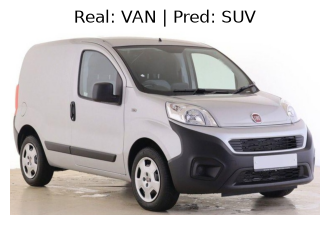

[VAN] 202103300765921_jpg.rf.9e117f3e8db327cddfa491ff39f87649.jpg → Predicción: SUV


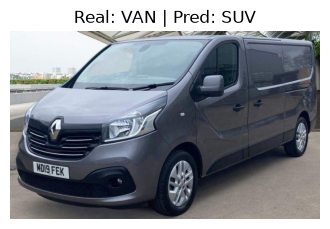

[VAN] 202104030936322_jpg.rf.92c792562024004a2516c02092c4bc73.jpg → Predicción: SUV


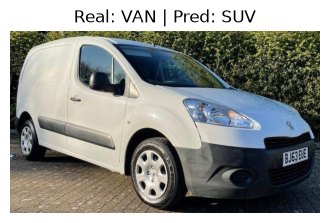

[VAN] 202104030955174_jpg.rf.09101bdaf06f99cc79e5661714a34a7a.jpg → Predicción: SUV


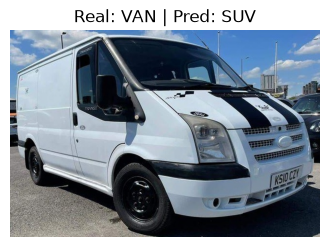

[VAN] 202104061021589_jpg.rf.01277766d30191bdb559ff0f4f177a84.jpg → Predicción: SUV


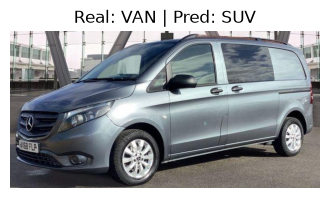

[VAN] 202104071073973_jpg.rf.9db2413752a5ba7588790481c0478a18.jpg → Predicción: SUV


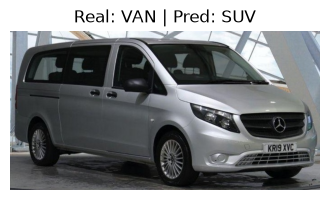

[VAN] 202104081112350_jpg.rf.80485bc7528e677f5a9b4b37a04be37d.jpg → Predicción: SUV


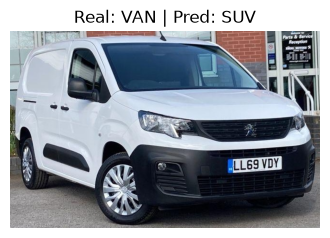

[VAN] 202104091165041_jpg.rf.9008a03ea82f4faa2c3e6ccbe97a09e0.jpg → Predicción: SUV


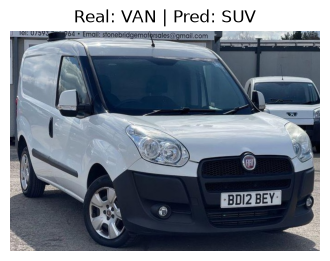

[VAN] 202104101211155_jpg.rf.bd9207703f149c99033826414825710f.jpg → Predicción: SUV


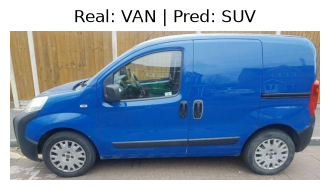

[VAN] 202104121262095_jpg.rf.eb5a72ccf472b2c2a69d3166ae524c17.jpg → Predicción: SUV


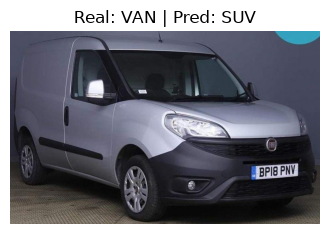

[VAN] 202104121274592_jpg.rf.69d6e5018830a283e12efeb4df3d6543.jpg → Predicción: SUV


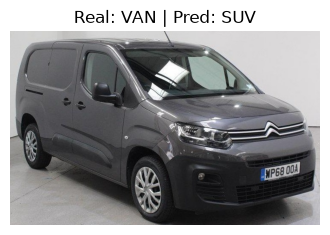

[VAN] 202104121277139_jpg.rf.0a5459920b84722ca9244dc4d07998e4.jpg → Predicción: SUV


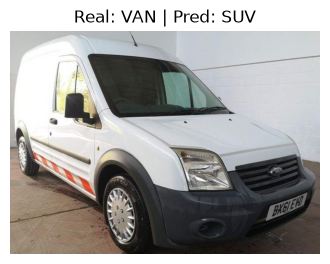

[VAN] 202104131319122_jpg.rf.a3a6b5c1822fd2d0e86291695871458d.jpg → Predicción: SUV


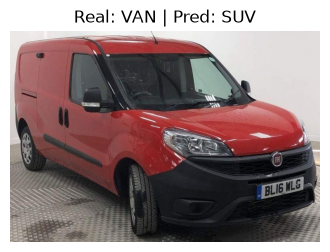

[VAN] 202104141364319_jpg.rf.3b0df411112672ce758200c3a56e3aca.jpg → Predicción: SUV


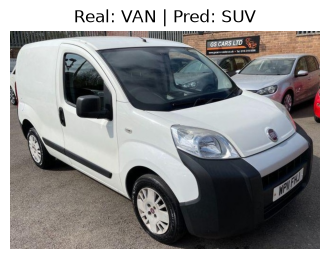

[VAN] 202104141372706_jpg.rf.aa842e78fec8829e9da712ea0d5e18fe.jpg → Predicción: SUV


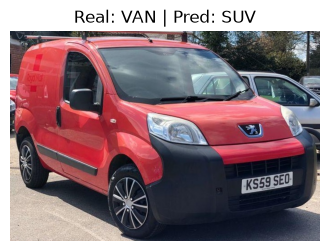

[VAN] 202104151410314_jpg.rf.16e871d090c11e63a636d4b0c7a4eac4.jpg → Predicción: SUV


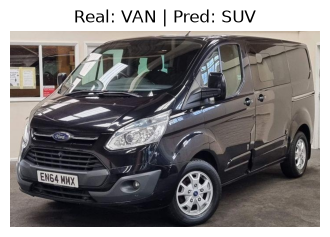

[VAN] 202104161457819_jpg.rf.043f85db33579ef729fcdc6fba20bfa2.jpg → Predicción: SUV


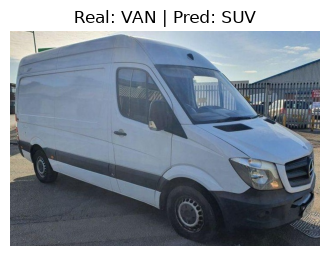

[VAN] 202104211632317_jpg.rf.25011b4102eada843835af543ca9428d.jpg → Predicción: SUV


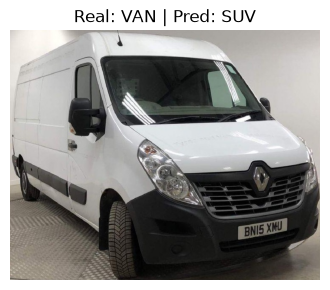

[VAN] 202104241778708_jpg.rf.f0ce77c220d8cc87fb76ea74ce2d4b19.jpg → Predicción: SUV


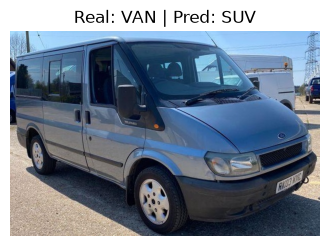

[VAN] 202104251795657_jpg.rf.4284023a08e74d99eb7dab3cb6267ab0.jpg → Predicción: SUV


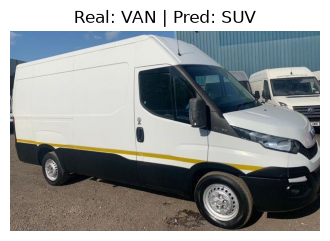

[VAN] 202104271879981_jpg.rf.c1e65e5128358b0a0cc68e9c024c4707.jpg → Predicción: SUV


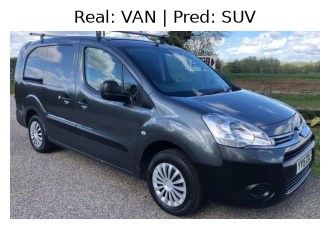

[VAN] 202104291957535_jpg.rf.7cee0e5337d78032c8f6d6099a7230b7.jpg → Predicción: SUV


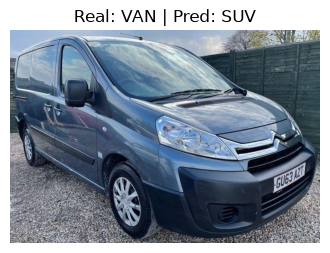

[VAN] 202105032152887_jpg.rf.ce87479c23d9b5edef6f76a14cfd4783.jpg → Predicción: SUV


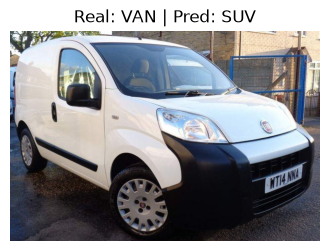

[VAN] 202105042191801_jpg.rf.e7e2b85a0bfe8bb2591a2449cec0c834.jpg → Predicción: SUV


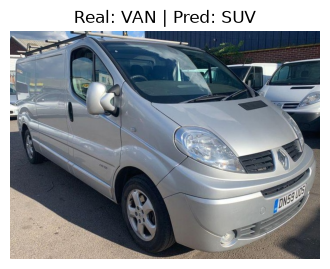

[VAN] 202105052218781_jpg.rf.b977cff3af5ed76ad84380e52e75ca65.jpg → Predicción: SUV


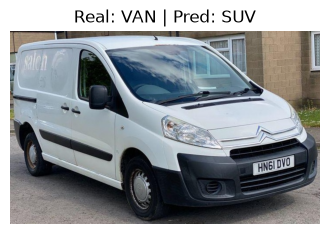

[VAN] 202105052218847_jpg.rf.8a8189408129ed7ee08b72b6dabc9dbc.jpg → Predicción: SUV


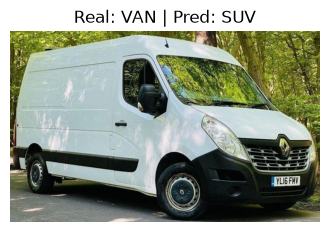

[VAN] 202105122531379_jpg.rf.356562b1e5670c4c4d7b9e50dd707df2.jpg → Predicción: SUV


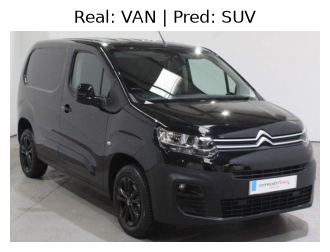

[VAN] 202105142609852_jpg.rf.db087c46be7ed30434ea9e78f7a222f9.jpg → Predicción: SUV


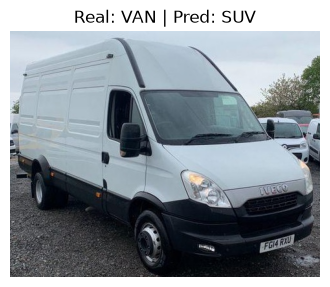

[VAN] 202105182780518_jpg.rf.bc8332289c4440a7684b877021635057.jpg → Predicción: SUV


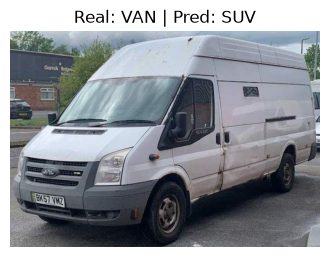

[VAN] 202105182780851_jpg.rf.07e276c25090941188eb86733e055731.jpg → Predicción: SUV


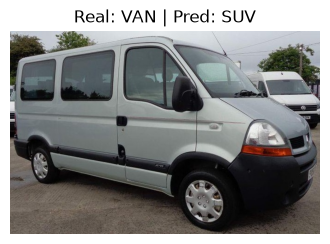

[VAN] 202105182796671_jpg.rf.c3ec2508054a0e73e38d21ae4b1f2abc.jpg → Predicción: SUV


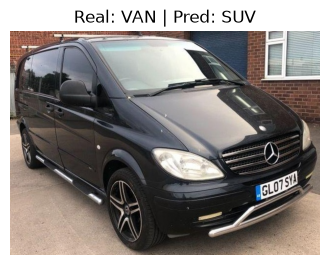

[VAN] 202105202856541_jpg.rf.672f8b2d302dd1399aca51ef398d056a.jpg → Predicción: SUV


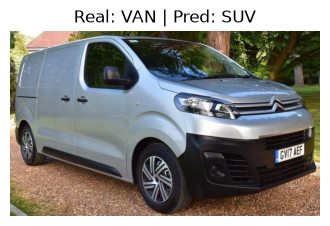

[VAN] 202105202863576_jpg.rf.11f90a8a5d231b77722a351628b082c6.jpg → Predicción: SUV


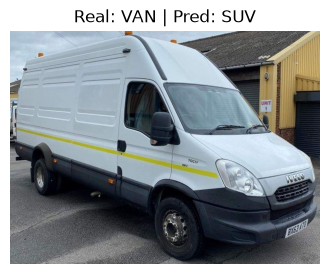

[VAN] 202105212922697_jpg.rf.da9504544c8e097c5376b7f1ecf2f689.jpg → Predicción: SUV


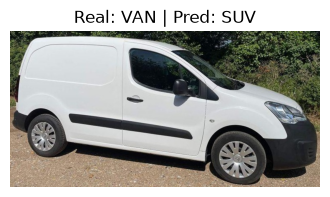

[VAN] 202105243017895_jpg.rf.47c105cd90f1a05ed3a88d424cf7991f.jpg → Predicción: SUV


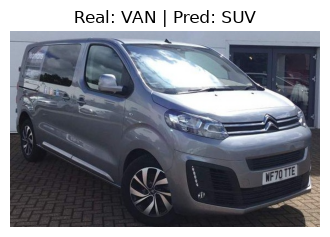

[VAN] 202105243031718_jpg.rf.bf1bced2959a0ff19f95b5ec0e31d7b8.jpg → Predicción: SUV


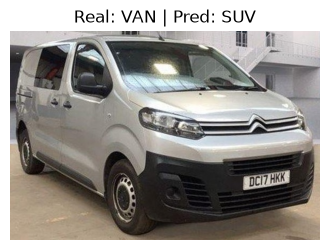

[VAN] 202105253085145_jpg.rf.8e3d934c66381822ec966d6f897b0480.jpg → Predicción: SUV


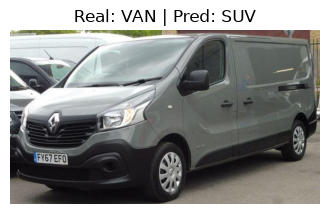

[VAN] 202105273152942_jpg.rf.128f066c3124ca8726b12b60aa5c0a64.jpg → Predicción: SUV


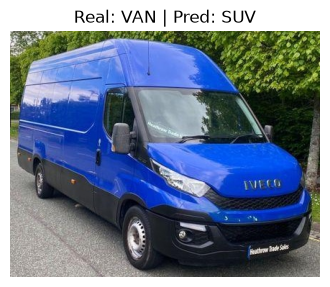

[VAN] 202105283197037_jpg.rf.60e6e57a14d14146bc04c514c544167d.jpg → Predicción: SUV


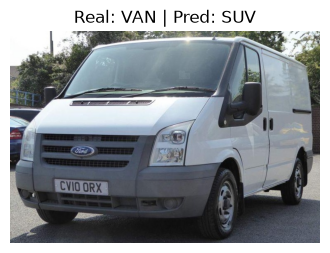

[VAN] 202105283205498_jpg.rf.222fc4e21765779f2765e8d0922fefb9.jpg → Predicción: SUV


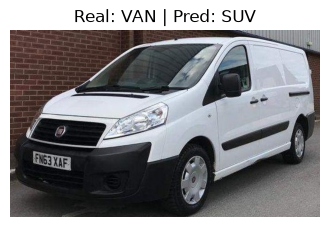

[VAN] 202105293235286_jpg.rf.71cc9b77be28502a43270115ca508040.jpg → Predicción: SUV


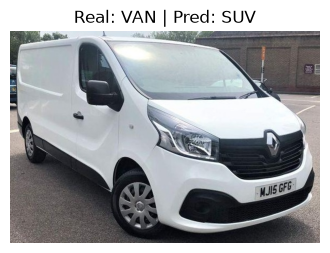

[VAN] 202105293245305_jpg.rf.b10e638dcc51b6cbb85ccc870841e741.jpg → Predicción: SUV


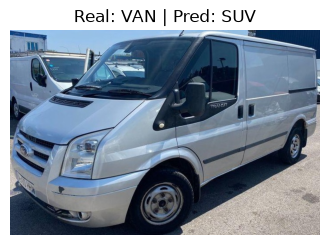

[VAN] 202106023357339_jpg.rf.a1148b99614d670fcdaa5ac4041470e7.jpg → Predicción: SUV


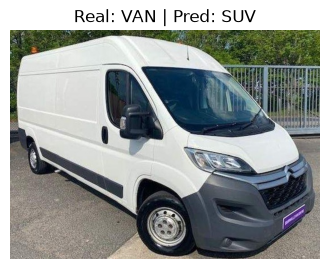

[VAN] 202106023365398_jpg.rf.ab31e0be499ac2045cbb9c558e237c11.jpg → Predicción: SUV


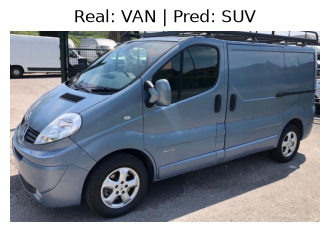

[VAN] 202106033402658_jpg.rf.7f0ce737f357f17ab55a3b5687311f82.jpg → Predicción: SUV


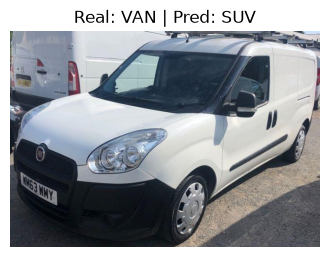

[VAN] 202106053511370_jpg.rf.fceedfdab7c2ccac0cd9002e38ac9357.jpg → Predicción: SUV


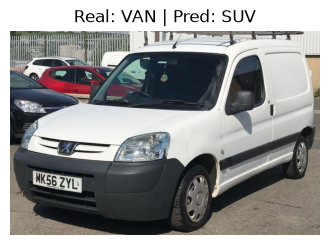

[VAN] 202106063532212_jpg.rf.4d0ed01eea90d6af9f391eb3cac34f6f.jpg → Predicción: SUV


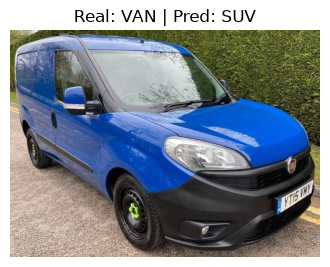

[VAN] 202106073568917_jpg.rf.95f8fb0ad392d3eef236224c89bc4d20.jpg → Predicción: SUV


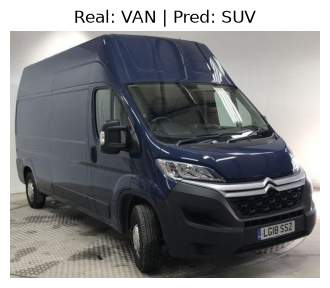

[VAN] 202106083601911_jpg.rf.4599189328bf3e9bcf4028ccb999aa1d.jpg → Predicción: SUV


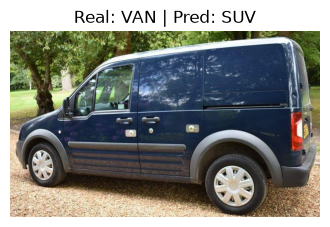

[VAN] 202106083606828_jpg.rf.f72bad4951bee70d94a2d6cfce4303b8.jpg → Predicción: SUV


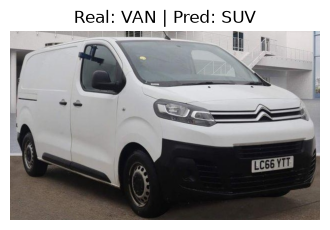

[VAN] 202106083614142_jpg.rf.6cc56bd70b966f7738733083c9c71055.jpg → Predicción: SUV


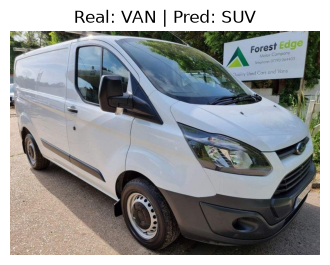

[VAN] 202106083631400_jpg.rf.fc1bd1c50274afbc077a230910984935.jpg → Predicción: SUV


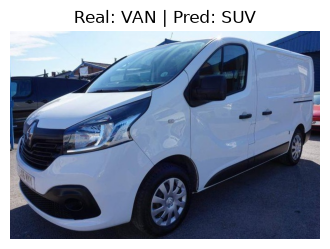

[VAN] 202106103706627_jpg.rf.1c43fe8466878591186f93d957c19cd3.jpg → Predicción: SUV


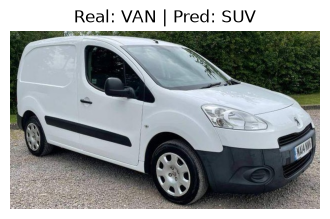

[VAN] 202106113748932_jpg.rf.fbff900663e7bf2dfb719e750e70a4f9.jpg → Predicción: SUV


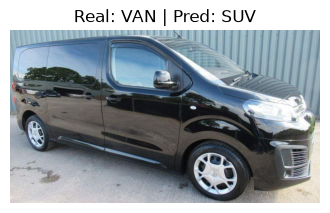

[VAN] 236_jpg.rf.92f6acd92b5dc8d02682645eca5be931.jpg → Predicción: SUV


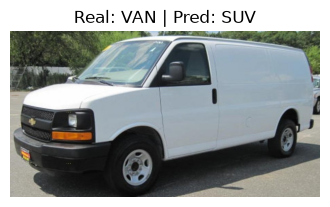

[VAN] 267_jpg.rf.769bfb40a328b76e28461723e7310c1c.jpg → Predicción: SUV


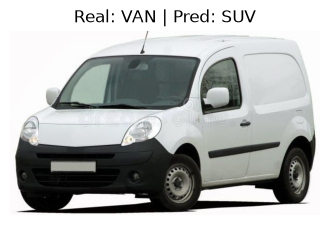

[VAN] 276_jpg.rf.e5bcfce4ef85be07828f4e5baeec990f.jpg → Predicción: SUV


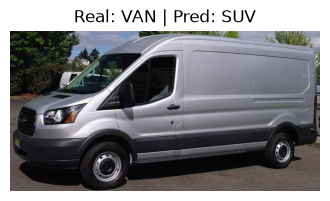

[VAN] 37_jpg.rf.24db2670cdc2ed125b8846cd6bd49fd4.jpg → Predicción: SUV


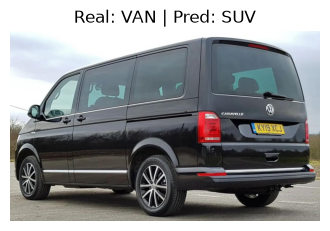

[VAN] 71_jpg.rf.7ecb3ece89fd978f4f489470c2c3c718.jpg → Predicción: SUV


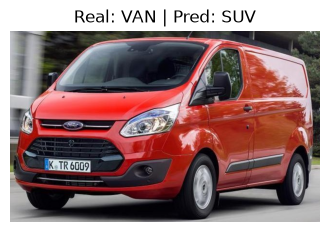

[VAN] 78_jpg.rf.e621249e53b419d4e2fbf6c2359d720b.jpg → Predicción: SUV


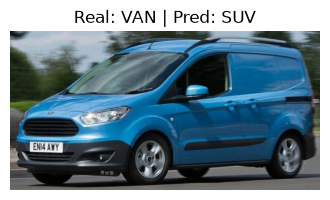

[VAN] Image_181_jpg.rf.95942dc8c7c60cb5fa4422ff4f75243f.jpg → Predicción: SUV


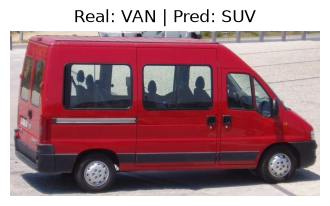

[VAN] Image_274_jpg.rf.5c2ba56c4181f56da4234bb13b29e8d7.jpg → Predicción: SUV


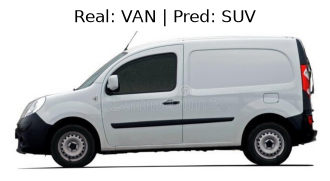

[VAN] Image_34_jpg.rf.5e305699d2da31c5685172a3b4f2a99f.jpg → Predicción: SUV


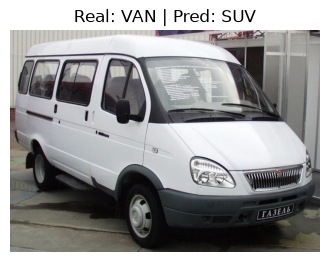

[VAN] Image_62_jpg.rf.e7c064c8ee5d564cfc66480e961b9e2e.jpg → Predicción: SUV


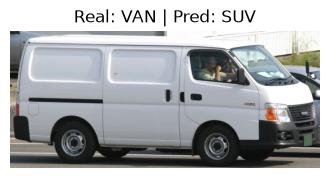

In [ ]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1. Cargar modelo y label encoder
print("Cargando modelo y label encoder...")
modelo = load_model("modelo_cars.keras")

with open("labelencoder.pkl", "rb") as f:
    labelencoder = pickle.load(f)

# 2. Definir ruta de prueba
ruta_nuevos = r"C:\Users\Luis Felipe\Desktop\Trabajo IA\Cars_Body_Type\test"
img_size = (150, 150)

# 3. Función actualizada para buscar imágenes dentro de subcarpetas
def predecir_y_mostrar_carpetas(ruta_raiz, modelo, labelencoder, img_size=img_size):
    resultados = []
    
    if not os.path.exists(ruta_raiz):
        print(f"Error: La ruta '{ruta_raiz}' no existe.")
        return resultados

    # Usamos os.walk para recorrer la carpeta principal y todas sus subcarpetas
    total_imagenes = 0
    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                total_imagenes += 1

    if total_imagenes == 0:
        print(f"No se encontraron imágenes válidas en '{ruta_raiz}' ni en sus subcarpetas.")
        return resultados

    print(f"Se encontraron {total_imagenes} imágenes. Procesando...")

    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                ruta = os.path.join(root, archivo)
                # Opcional: obtener la clase real basada en el nombre de la subcarpeta
                clase_real = os.path.basename(root)

                # Cargar y preprocesar la imagen
                img = Image.open(ruta)
                img_resized = img.resize(img_size)
                
                img_array = np.array(img_resized) / 255.0
                img_array = np.expand_dims(img_array, axis=0)

                # Predicción
                pred = modelo.predict(img_array, verbose=0)
                clase_pred = np.argmax(pred, axis=1)

                # Convertir a etiqueta original
                etiqueta = labelencoder.inverse_transform(clase_pred)
                
                resultados.append((archivo, etiqueta[0]))

                # Imprimir resultado en consola (mostrando la carpeta/clase real y la predicha)
                print(f"[{clase_real}] {archivo} → Predicción: {etiqueta[0]}")

                # Mostrar imagen con matplotlib
                plt.figure(figsize=(4, 4))
                plt.imshow(img)
                plt.title(f"Real: {clase_real} | Pred: {etiqueta[0]}")
                plt.axis("off")
                plt.show()

    return resultados

# Ejecutar el proceso actualizado
resultados = predecir_y_mostrar_carpetas(ruta_nuevos, modelo, labelencoder)